# Experiments

In [2]:
import importlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import Functions
import Experiments

importlib.reload(Functions)
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

## E1. Full case-study network 

In [25]:
data = Functions.load_master_data("Master_Data.xlsx")

data_E1 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2","P3", "P4", "P5", "P6", "P7","P8", "P9", "P10", "P11", "P12","P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4","M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

### E1.1 Minimum cost


In [26]:
mdl_E1_1, vars_E1_1 = Functions.build_model(data_E1, objective="cost")

mdl_E1_1.parameters.mip.tolerances.mipgap = 0.001
mdl_E1_1.parameters.timelimit = 900

results_E1_1 = Functions.solve_and_extract(mdl_E1_1, vars_E1_1, data_E1, log_output=False)

Experiments.experiment_report(
    results_E1_1,
    mdl_E1_1,
    experiment_id="E1.1",
    scenario_name="Full-network min-cost",
    objective_name="Min-Cost"
)



EXPERIMENT REPORT
Experiment : E1.1
Scenario   : Full-network min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 20,175,829.14 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 2,266,552.05 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,845,277.09 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F5: 5,600.00 tonnes
P4 

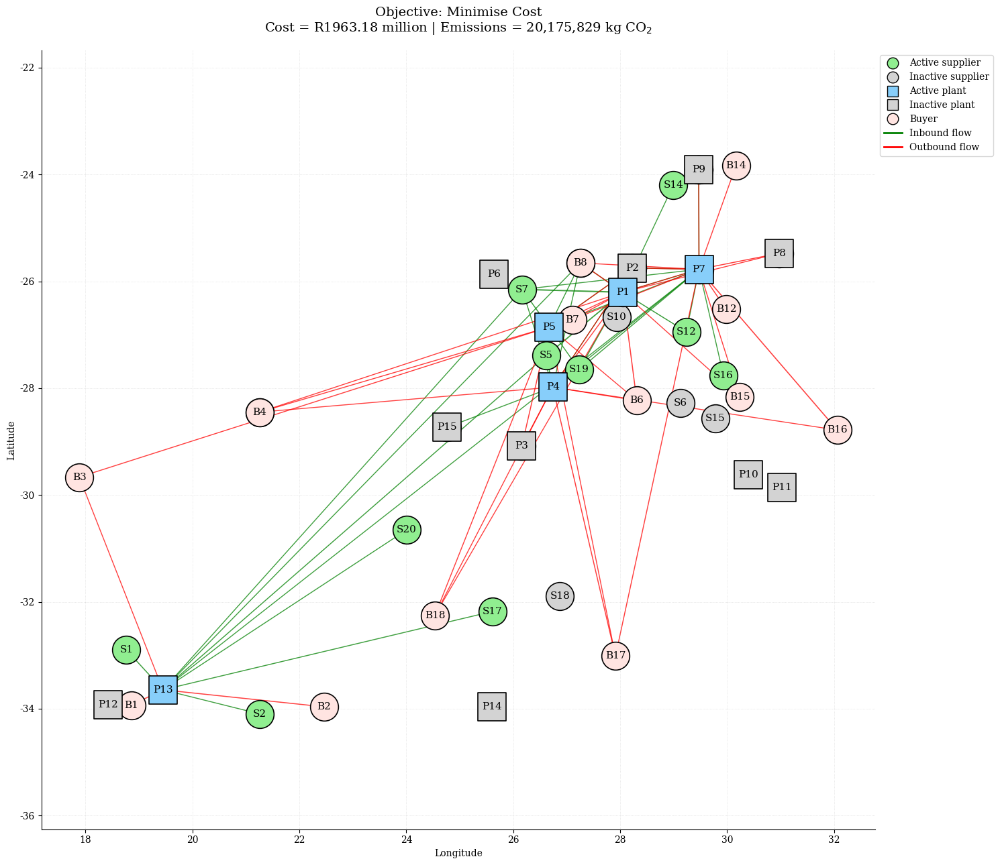

In [5]:
Experiments.plot_exp_solution(
    results_E1_1,
    data_E1,
    coord_file="Master_Coordinates.xlsx"
)


### E1.2 Minimum emissions


In [27]:
mdl_E1_2, vars_E1_2 = Functions.build_model(data_E1, objective="emissions")

mdl_E1_2.parameters.mip.tolerances.mipgap = 0.001
mdl_E1_2.parameters.timelimit = 900

results_E1_2 = Functions.solve_and_extract(mdl_E1_2, vars_E1_2, data_E1, log_output=False)

Experiments.experiment_report(
    results_E1_2,
    mdl_E1_2,
    experiment_id="E1.2",
    scenario_name="Full-network min-emissions",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E1.2
Scenario   : Full-network min-emissions
Objective  : Min-Cost

Objective value : 18,964,156.80
Total cost      : R 2,112,128,500.38
Total emissions : 18,964,156.80 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,653,432.88
inbound_transport_cost        : R 108,260,990.00
production_cost               : R 299,469,673.50
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,549,404.00

--- Emissions breakdown ---
inbound_emissions             : 2,263,135.17 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,637,021.63 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 tonnes
P2 - F4: 8,870.00

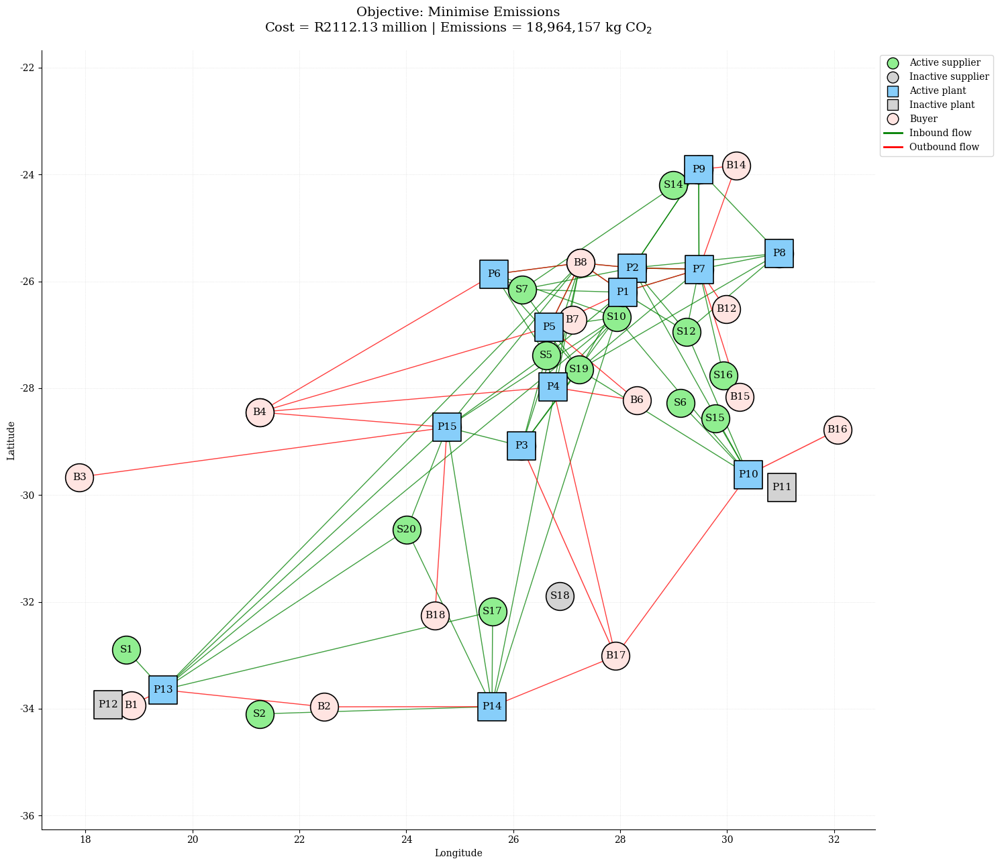

In [7]:
Experiments.plot_exp_solution(
    results_E1_2,
    data_E1,
    coord_file="Master_Coordinates.xlsx"
)


### E1.3 Pareto frontier


In [26]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [27]:
results_E1_3, pareto_E1_3 = Experiments.pareto_results(
    data_E1,
    results_E1_1,
    results_E1_2,
    experiment_id="E1.3",
    time_limit=600
)

Running E1.3.01 of E1.3.21 | Emissions cap: 20,175,829.14 kg CO2
Running E1.3.02 of E1.3.21 | Emissions cap: 20,115,245.52 kg CO2
Running E1.3.03 of E1.3.21 | Emissions cap: 20,054,661.91 kg CO2
Running E1.3.04 of E1.3.21 | Emissions cap: 19,994,078.29 kg CO2
Running E1.3.05 of E1.3.21 | Emissions cap: 19,933,494.67 kg CO2
Running E1.3.06 of E1.3.21 | Emissions cap: 19,872,911.05 kg CO2
Running E1.3.07 of E1.3.21 | Emissions cap: 19,812,327.44 kg CO2
Running E1.3.08 of E1.3.21 | Emissions cap: 19,751,743.82 kg CO2
Running E1.3.09 of E1.3.21 | Emissions cap: 19,691,160.20 kg CO2
Running E1.3.10 of E1.3.21 | Emissions cap: 19,630,576.59 kg CO2
Running E1.3.11 of E1.3.21 | Emissions cap: 19,569,992.97 kg CO2
Running E1.3.12 of E1.3.21 | Emissions cap: 19,509,409.35 kg CO2
Running E1.3.13 of E1.3.21 | Emissions cap: 19,448,825.74 kg CO2
Running E1.3.14 of E1.3.21 | Emissions cap: 19,388,242.12 kg CO2
Running E1.3.15 of E1.3.21 | Emissions cap: 19,327,658.50 kg CO2
Running E1.3.16 of E1.3.2

,run_id,epsilon,total_cost,total_emissions,open_plants,solve_status,solve_time,mip_gap,number_of_variables,number_of_constraints,number_of_binaries,number_of_integers
0,E1.3.01,2.017583e+07,1.963010e+09,20174683.44,"P1, P4, P5, P7, P13","integer optimal, tolerance",169.953,0.000365,184905,185454,15,92400
1,E1.3.02,2.011525e+07,1.963372e+09,20115245.52,"P1, P4, P5, P7, P13","integer optimal, tolerance",52.843,0.000608,184905,185454,15,92400
2,E1.3.03,2.005466e+07,1.964453e+09,19879584.25,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",27.078,0.000987,184905,185454,15,92400
3,E1.3.04,1.999408e+07,1.964338e+09,19878871.25,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",24.828,0.000666,184905,185454,15,92400
4,E1.3.05,1.993349e+07,1.964488e+09,19880179.33,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",24.797,0.000545,184905,185454,15,92400
5,E1.3.06,1.987291e+07,1.964141e+09,19872911.06,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",112.859,0.000356,184905,185454,15,92400
6,E1.3.07,1.981233e+07,1.964644e+09,19812327.44,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",92.297,0.000417,184905,185454,15,92400
7,E1.3.08,1.975174e+07,1.965614e+09,19751743.82,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",82.343,0.000430,184905,185454,15,92400
8,E1.3.09,1.969116e+07,1.967244e+09,19691160.20,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",23.094,0.000831,184905,185454,15,92400
9,E1.3.10,1.963058e+07,1.970215e+09,19630576.59,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",21.563,0.000954,184905,185454,15,92400


In [ ]:
pareto_table_E1_3 = Experiments.pareto_table(
    pareto_E1_3
)

,Point,Total emissions (kg CO2),Total cost (R)
0,E1.3.01,"20,174,683.44","1,963,010,203.29"
1,E1.3.02,"20,115,245.52","1,963,372,324.91"
2,E1.3.03,"19,879,584.25","1,964,453,202.90"
3,E1.3.04,"19,878,871.25","1,964,338,460.68"
4,E1.3.05,"19,880,179.33","1,964,487,781.11"
5,E1.3.06,"19,872,911.06","1,964,140,591.87"
6,E1.3.07,"19,812,327.44","1,964,644,202.58"
7,E1.3.08,"19,751,743.82","1,965,614,141.27"
8,E1.3.09,"19,691,160.20","1,967,244,311.52"
9,E1.3.10,"19,630,576.59","1,970,215,042.85"


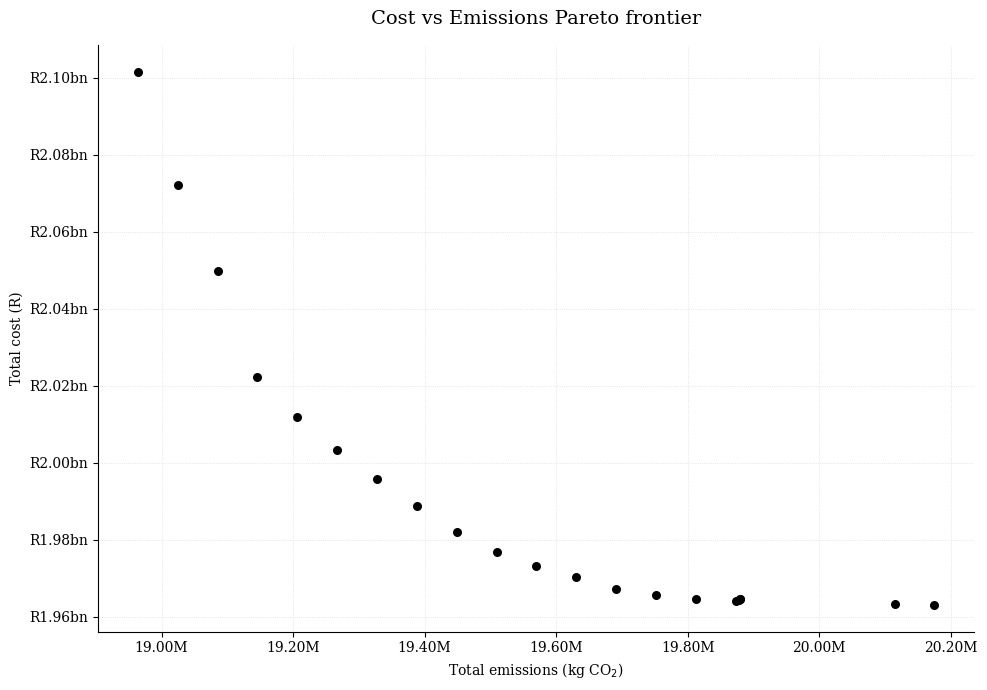

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Cost vs Emissions Pareto frontier'}, xlabel='Total emissions (kg CO$_2$)', ylabel='Total cost (R)'>)

In [29]:
Experiments.pareto_plot(
    pareto_E1_3, 
    label_points=False,
)

In [32]:
results_E1_3

{'E1.3.01': {'epsilon': 20175829.14,
  'results': {'objective_value': 1963010203.29,
   'total_cost': np.float64(1963010203.29),
   'total_emissions': np.float64(20174683.44),
   'open_plants': ['P1', 'P4', 'P5', 'P7', 'P13'],
   'production': {('P1', 'F1'): 7382.799999999999,
    ('P1', 'F2'): 7986.0,
    ('P1', 'F3'): 32600.0,
    ('P1', 'F4'): 8996.0,
    ('P1', 'F5'): 31000.0,
    ('P1', 'F6'): 31987.142857142862,
    ('P4', 'F1'): 1064.0,
    ('P4', 'F2'): 1400.0,
    ('P4', 'F3'): 5800.0,
    ('P4', 'F4'): 1600.0,
    ('P4', 'F5'): 5600.0,
    ('P4', 'F6'): 5800.0,
    ('P5', 'F1'): 2600.0000000000005,
    ('P5', 'F2'): 2800.0,
    ('P5', 'F3'): 11800.0,
    ('P5', 'F4'): 3192.0,
    ('P5', 'F5'): 11200.0,
    ('P5', 'F6'): 11600.0,
    ('P7', 'F1'): 7363.200000000001,
    ('P7', 'F2'): 7984.0,
    ('P7', 'F3'): 22240.0,
    ('P7', 'F4'): 8632.0,
    ('P7', 'F5'): 20530.0,
    ('P7', 'F6'): 22522.857142857138,
    ('P13', 'F3'): 9430.0,
    ('P13', 'F5'): 9740.0,
    ('P13', 'F6'


### E1.4 Selected Pareto configurations

Theory and interpretation, no code to run 

## E2. Supplier availability


### E2.1 Restricted Supplier Availability (few)


In [3]:
data = Functions.load_master_data("Master_Data.xlsx")

data_E2_1 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S5", "S7", "S8", "S10", "S11", "S12", "S14", "S15", "S19"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)


In [4]:
## min-cost

mdl_E2_1_cost, vars_E2_1_cost = Functions.build_model(data_E2_1, objective="cost")

mdl_E2_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E2_1_cost.parameters.timelimit = 900

results_E2_1_cost = Functions.solve_and_extract(mdl_E2_1_cost, vars_E2_1_cost, data_E2_1, log_output=False)

Experiments.experiment_report(
    results_E2_1_cost,
    mdl_E2_1_cost,
    experiment_id="E2.1",
    scenario_name="Restricted supplier availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E2.1
Scenario   : Restricted supplier availability – min-cost
Objective  : Min-Cost

Objective value : 1,974,487,674.60
Total cost      : R 1,974,487,674.60
Total emissions : 20,391,793.87 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,399,632,513.60
inbound_transport_cost        : R 111,274,912.00
production_cost               : R 287,658,703.00
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 94,581,546.00

--- Emissions breakdown ---
inbound_emissions             : 2,313,328.25 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 3,014,465.62 kg CO2

--- Production ---
P1 - F1: 7,368.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,600.00 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 30,954.00 tonnes
P1 - F6: 31,984.00 tonnes
P4 - F1: 1,042.00 tonnes
P4 - F2: 1,375.71 tonnes
P4 - F3: 5,797.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F

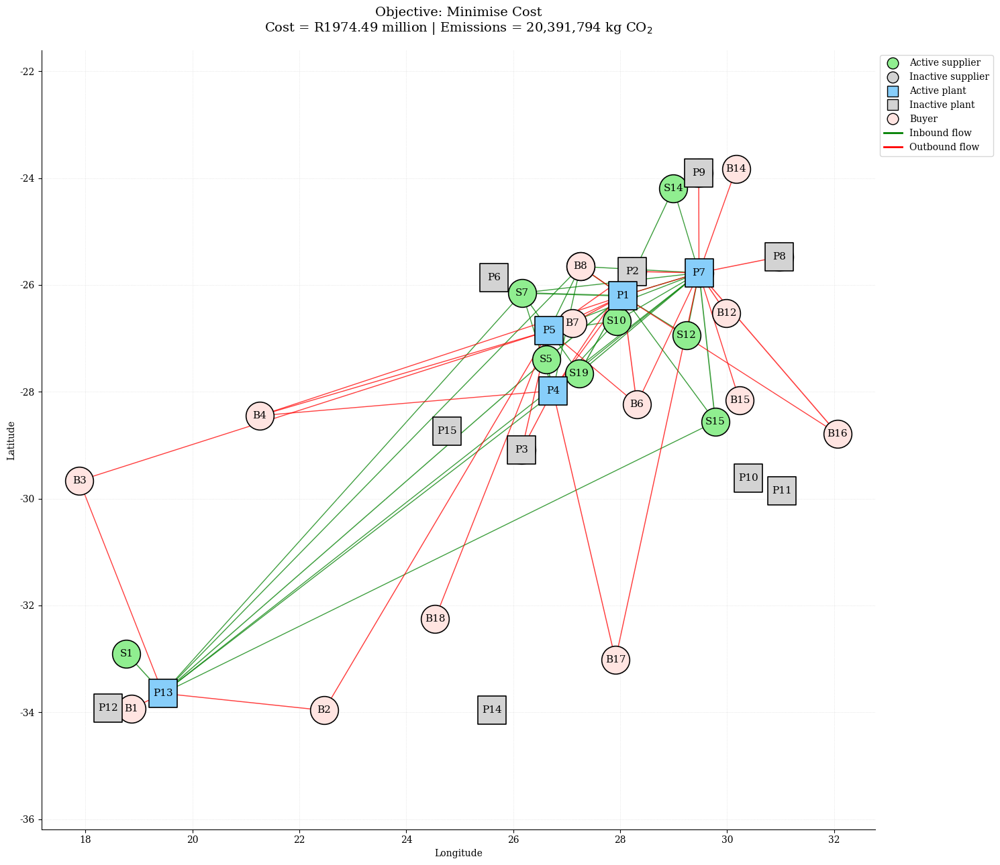

In [5]:
## Min-cost network plot

Experiments.plot_exp_solution(
    results_E2_1_cost,
    data_E2_1
)



In [6]:
## min-emissions

mdl_E2_1_emissions, vars_E2_1_emissions = Functions.build_model(data_E2_1, objective="emissions")

mdl_E2_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E2_1_emissions.parameters.timelimit = 900

results_E2_1_emissions = Functions.solve_and_extract(mdl_E2_1_emissions, vars_E2_1_emissions, data_E2_1, log_output=False)

Experiments.experiment_report(
    results_E2_1_emissions,
    mdl_E2_1_emissions,
    experiment_id="E2.1",
    scenario_name="Restricted supplier availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E2.1
Scenario   : Restricted supplier availability – min-emissions
Objective  : Min-Emissions

Objective value : 19,382,039.27
Total cost      : R 2,151,979,479.51
Total emissions : 19,382,039.27 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P13, P15

--- Cost breakdown ---
raw_material_cost             : R 1,437,217,269.86
inbound_transport_cost        : R 126,507,218.00
production_cost               : R 299,291,933.65
plant_opening_cost            : R 234,356,000.00
outbound_transport_cost       : R 54,607,058.00

--- Emissions breakdown ---
inbound_emissions             : 2,584,658.33 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,733,380.93 kg CO2

--- Production ---
P1 - F1: 7,396.36 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,450.00 tonnes
P1 - F4: 7,090.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 10,534.00 tonnes
P2 - F1: 7,358.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410

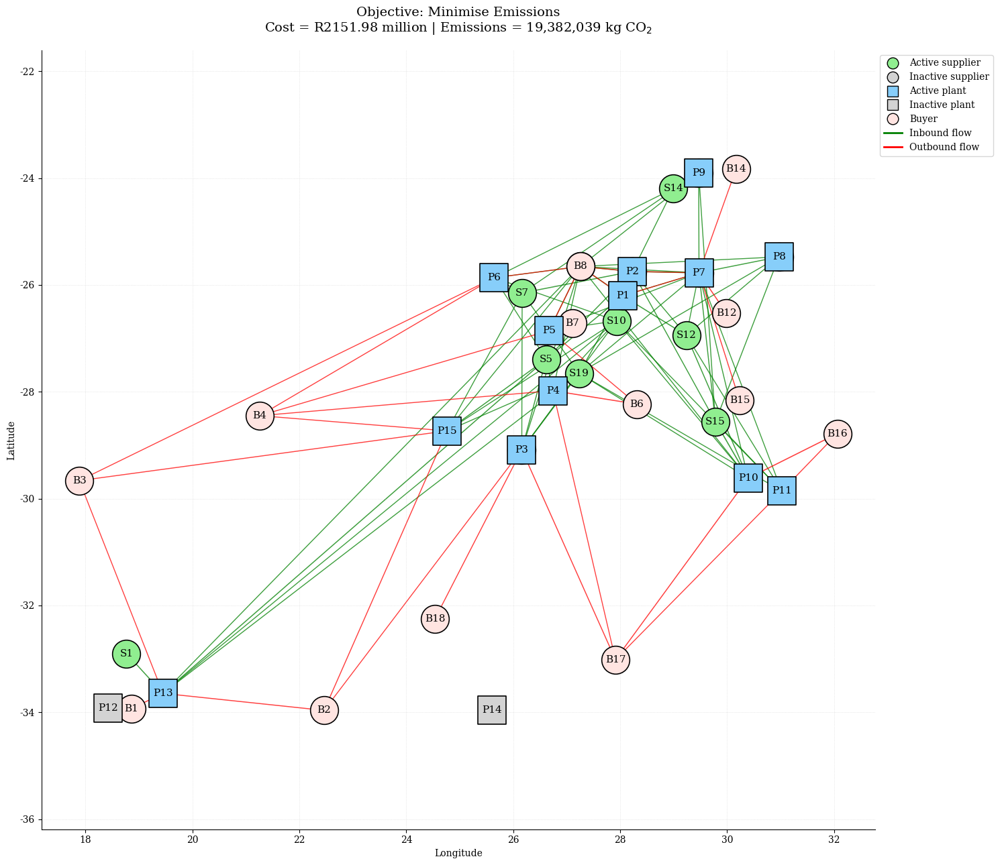

In [7]:
## Min-emissions network plot

Experiments.plot_exp_solution(
    results_E2_1_emissions,
    data_E2_1
)

Running E2.1.01 of E2.1.21 | Emissions cap: 20,391,793.87 kg CO2
Running E2.1.02 of E2.1.21 | Emissions cap: 20,341,306.14 kg CO2
Running E2.1.03 of E2.1.21 | Emissions cap: 20,290,818.41 kg CO2
Running E2.1.04 of E2.1.21 | Emissions cap: 20,240,330.68 kg CO2
Running E2.1.05 of E2.1.21 | Emissions cap: 20,189,842.95 kg CO2
Running E2.1.06 of E2.1.21 | Emissions cap: 20,139,355.22 kg CO2
Running E2.1.07 of E2.1.21 | Emissions cap: 20,088,867.49 kg CO2
Running E2.1.08 of E2.1.21 | Emissions cap: 20,038,379.76 kg CO2
Running E2.1.09 of E2.1.21 | Emissions cap: 19,987,892.03 kg CO2
Running E2.1.10 of E2.1.21 | Emissions cap: 19,937,404.30 kg CO2
Running E2.1.11 of E2.1.21 | Emissions cap: 19,886,916.57 kg CO2
Running E2.1.12 of E2.1.21 | Emissions cap: 19,836,428.84 kg CO2
Running E2.1.13 of E2.1.21 | Emissions cap: 19,785,941.11 kg CO2
Running E2.1.14 of E2.1.21 | Emissions cap: 19,735,453.38 kg CO2
Running E2.1.15 of E2.1.21 | Emissions cap: 19,684,965.65 kg CO2
Running E2.1.16 of E2.1.2

,run_id,epsilon,total_cost,total_emissions,open_plants,solve_status,solve_time,mip_gap,number_of_variables,number_of_constraints,number_of_binaries,number_of_integers
0,E2.1.01,20391793.87,1.974748e+09,20383606.63,"P1, P4, P5, P7, P13","integer optimal, tolerance",5.468,0.000881,124905,125354,15,62400
1,E2.1.02,20341306.14,1.975254e+09,20341306.14,"P1, P4, P5, P7, P13","integer optimal, tolerance",6.547,0.000749,124905,125354,15,62400
2,E2.1.03,20290818.41,1.975282e+09,20275106.29,"P1, P4, P5, P6, P7, P13","integer optimal, tolerance",118.219,0.000369,124905,125354,15,62400
3,E2.1.04,20240330.68,1.976904e+09,20020452.79,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",15.547,0.000981,124905,125354,15,62400
4,E2.1.05,20189842.95,1.976647e+09,20023231.91,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",45.984,0.000947,124905,125354,15,62400
5,E2.1.06,20139355.22,1.976943e+09,20023144.41,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",22.906,0.000827,124905,125354,15,62400
6,E2.1.07,20088867.49,1.976949e+09,20020382.58,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",31.313,0.000922,124905,125354,15,62400
7,E2.1.08,20038379.76,1.976724e+09,20017647.44,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",27.937,0.000507,124905,125354,15,62400
8,E2.1.09,19987892.03,1.977278e+09,19987892.03,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",17.844,0.000634,124905,125354,15,62400
9,E2.1.10,19937404.30,1.980241e+09,19937404.30,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",15.891,0.000627,124905,125354,15,62400


,Point,Total emissions (kg CO2),Total cost (R)
0,E2.1.01,"20,383,606.63","1,974,747,729.21"
1,E2.1.02,"20,341,306.14","1,975,253,755.40"
2,E2.1.03,"20,275,106.29","1,975,281,792.83"
3,E2.1.04,"20,020,452.79","1,976,903,539.35"
4,E2.1.05,"20,023,231.91","1,976,647,134.02"
5,E2.1.06,"20,023,144.41","1,976,943,151.71"
6,E2.1.07,"20,020,382.58","1,976,948,719.25"
7,E2.1.08,"20,017,647.44","1,976,723,538.37"
8,E2.1.09,"19,987,892.03","1,977,278,252.45"
9,E2.1.10,"19,937,404.30","1,980,241,238.50"


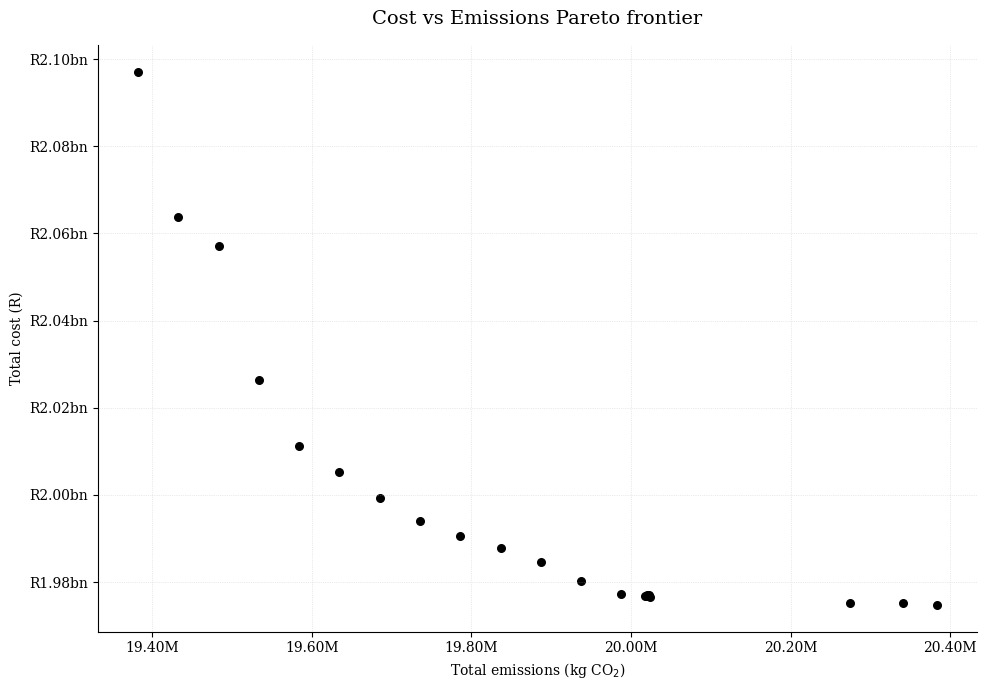

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Cost vs Emissions Pareto frontier'}, xlabel='Total emissions (kg CO$_2$)', ylabel='Total cost (R)'>)

In [8]:
## Pareto E2.1

results_E2_1, pareto_E2_1 = Experiments.pareto_results(
    data_E2_1,
    results_E2_1_cost,
    results_E2_1_emissions,
    experiment_id="E2.1",
    time_limit=600
)

pareto_table_E2_1 = Experiments.pareto_table(
    pareto_E2_1
)

Experiments.pareto_plot(
    pareto_E2_1, 
    label_points=False,
)

### E2.2 Intermediate Supplier Availability (many)


In [2]:
data = Functions.load_master_data("Master_Data.xlsx")

data_E2_2 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S4", "S5", "S6", "S7", "S8", "S10", "S11", "S12", "S14", "S15", "S16", "S17", "S19"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [3]:
## Min-cost

mdl_E2_2_cost, vars_E2_2_cost = Functions.build_model(data_E2_2, objective="cost")

mdl_E2_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E2_2_cost.parameters.timelimit = 900

results_E2_2_cost = Functions.solve_and_extract(mdl_E2_2_cost, vars_E2_2_cost, data_E2_2, log_output=False)

Experiments.experiment_report(
    results_E2_2_cost,
    mdl_E2_2_cost,
    experiment_id="E2.2",
    scenario_name="Intermediate supplier availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E2.2
Scenario   : Intermediate supplier availability – min-cost
Objective  : Min-Cost

Objective value : 1,971,123,066.03
Total cost      : R 1,971,123,066.03
Total emissions : 19,989,302.31 kg CO2
Open plants     : P1, P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,398,994,074.04
inbound_transport_cost        : R 105,573,534.00
production_cost               : R 289,595,777.99
plant_opening_cost            : R 92,168,000.00
outbound_transport_cost       : R 84,791,680.00

--- Emissions breakdown ---
inbound_emissions             : 2,224,959.01 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,700,343.30 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 26,172.00 tonnes
P1 - F4: 8,938.52 tonnes
P1 - F5: 22,542.00 tonnes
P1 - F6: 23,526.00 tonnes
P3 - F3: 11,800.00 tonnes
P3 - F4: 1,594.48 tonnes
P3 - F5: 11,189.96 tonnes
P3 - F6: 11,566.00 tonn

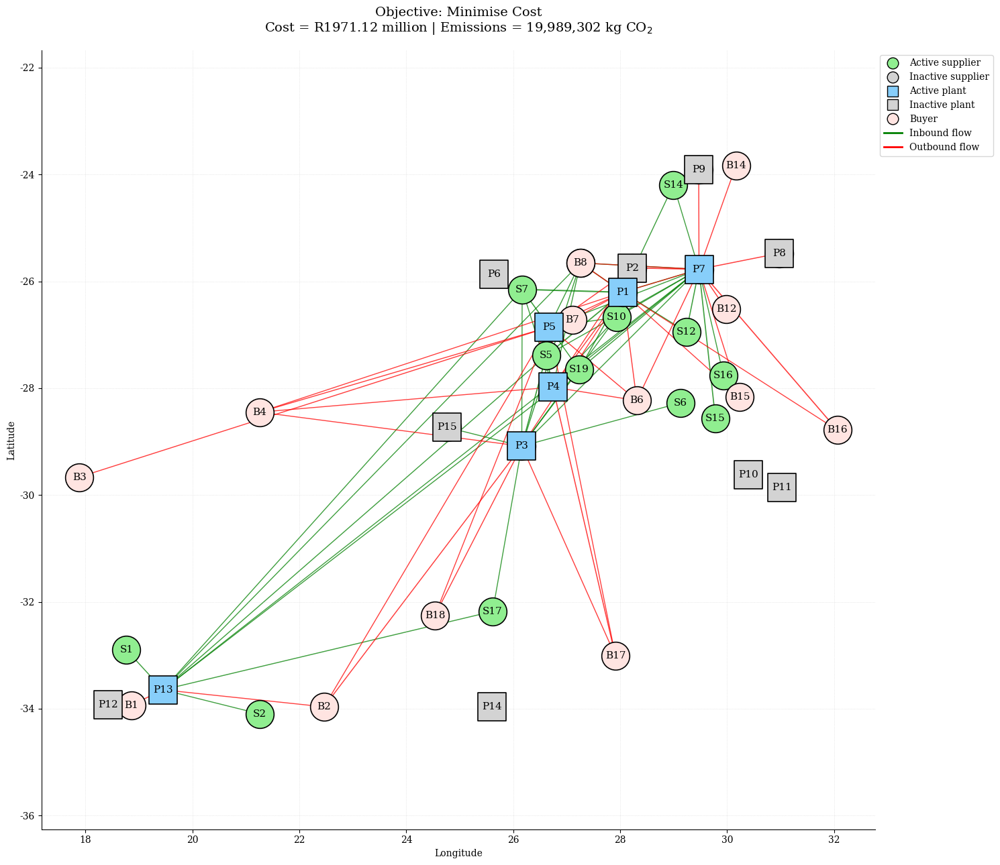

In [4]:
## Min-cost network plot

Experiments.plot_exp_solution(
    results_E2_2_cost,
    data_E2_2
)

In [5]:
## Min-emissions

mdl_E2_2_emissions, vars_E2_2_emissions = Functions.build_model(data_E2_2, objective="emissions")

mdl_E2_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E2_2_emissions.parameters.timelimit = 900

results_E2_2_emissions = Functions.solve_and_extract(mdl_E2_2_emissions, vars_E2_2_emissions, data_E2_2, log_output=False)

Experiments.experiment_report(
    results_E2_2_emissions,
    mdl_E2_2_emissions,
    experiment_id="E2.2",
    scenario_name="Intermediate supplier availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E2.2
Scenario   : Intermediate supplier availability – min-emissions
Objective  : Min-Emissions

Objective value : 19,117,907.43
Total cost      : R 2,121,129,050.67
Total emissions : 19,117,907.43 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,159,981.00
inbound_transport_cost        : R 117,498,928.00
production_cost               : R 298,744,959.67
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 52,530,182.00

--- Emissions breakdown ---
inbound_emissions             : 2,386,727.59 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,667,179.83 kg CO2

--- Production ---
P1 - F1: 7,365.83 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,450.00 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,890.00 tonnes
P1 - F6: 10,254.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,4

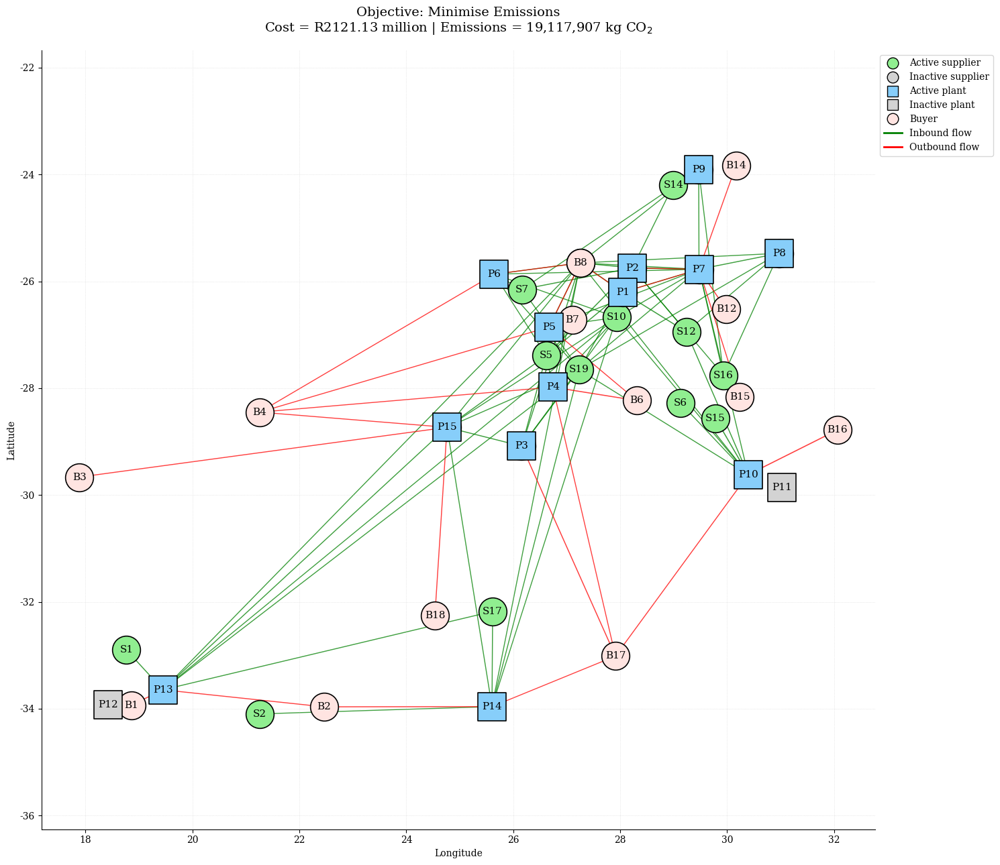

In [6]:
## Min-emissions network plot

Experiments.plot_exp_solution(
    results_E2_2_emissions,
    data_E2_2
)

### E2.3 Full Supplier Availability (all)

In [7]:
data = Functions.load_master_data("Master_Data.xlsx")

data_E2_3 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [8]:
## Min-cost

mdl_E2_3_cost, vars_E2_3_cost = Functions.build_model(data_E2_3, objective="cost")

mdl_E2_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E2_3_cost.parameters.timelimit = 900

results_E2_3_cost = Functions.solve_and_extract(mdl_E2_3_cost, vars_E2_3_cost, data_E2_3, log_output=False)

Experiments.experiment_report(
    results_E2_3_cost,
    mdl_E2_3_cost,
    experiment_id="E2.3",
    scenario_name="Full supplier availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E2.3
Scenario   : Full supplier availability – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 20,175,829.14 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 2,266,552.05 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,845,277.09 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F5: 5,6

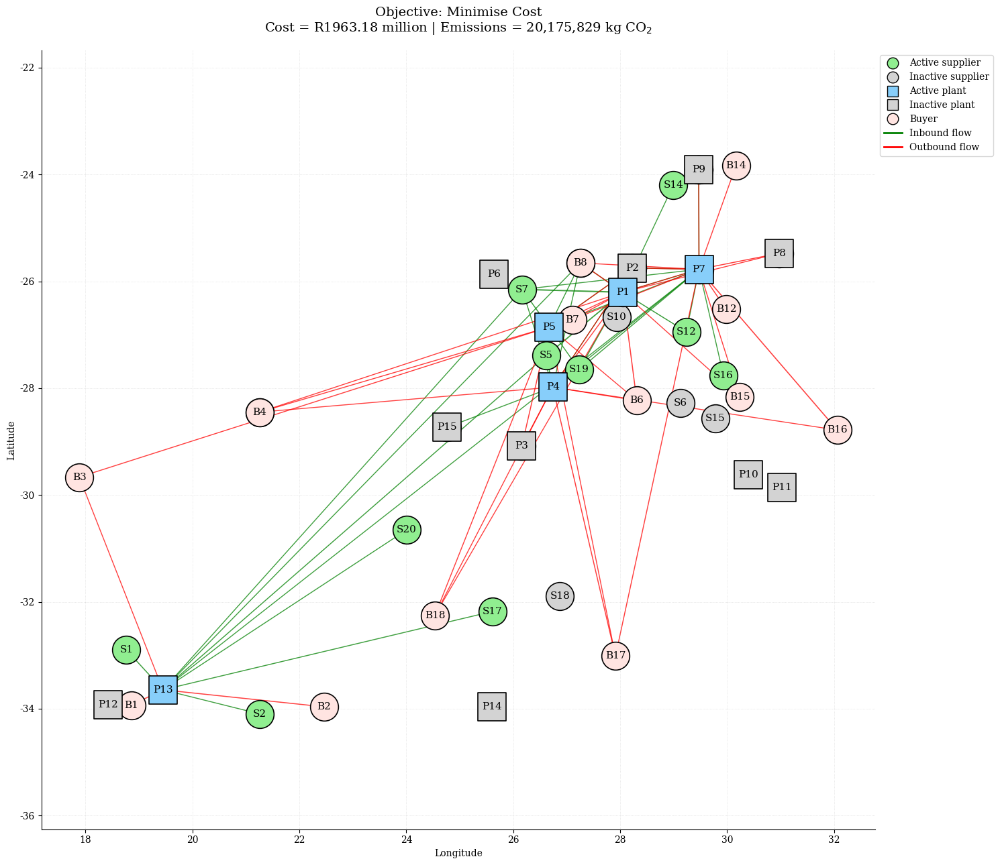

In [9]:
## Min-cost network plot

Experiments.plot_exp_solution(
    results_E2_3_cost,
    data_E2_3
)

In [10]:
## Min-emissions

mdl_E2_3_emissions, vars_E2_3_emissions = Functions.build_model(data_E2_3, objective="emissions")

mdl_E2_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E2_3_emissions.parameters.timelimit = 900

results_E2_3_emissions = Functions.solve_and_extract(mdl_E2_3_emissions, vars_E2_3_emissions, data_E2_3, log_output=False)

Experiments.experiment_report(
    results_E2_3_emissions,
    mdl_E2_3_emissions,
    experiment_id="E2.3",
    scenario_name="Full supplier availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E2.3
Scenario   : Full supplier availability – min-emissions
Objective  : Min-Emissions

Objective value : 18,964,156.80
Total cost      : R 2,112,128,500.38
Total emissions : 18,964,156.80 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,653,432.88
inbound_transport_cost        : R 108,260,990.00
production_cost               : R 299,469,673.50
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,549,404.00

--- Emissions breakdown ---
inbound_emissions             : 2,263,135.17 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,637,021.63 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 ton

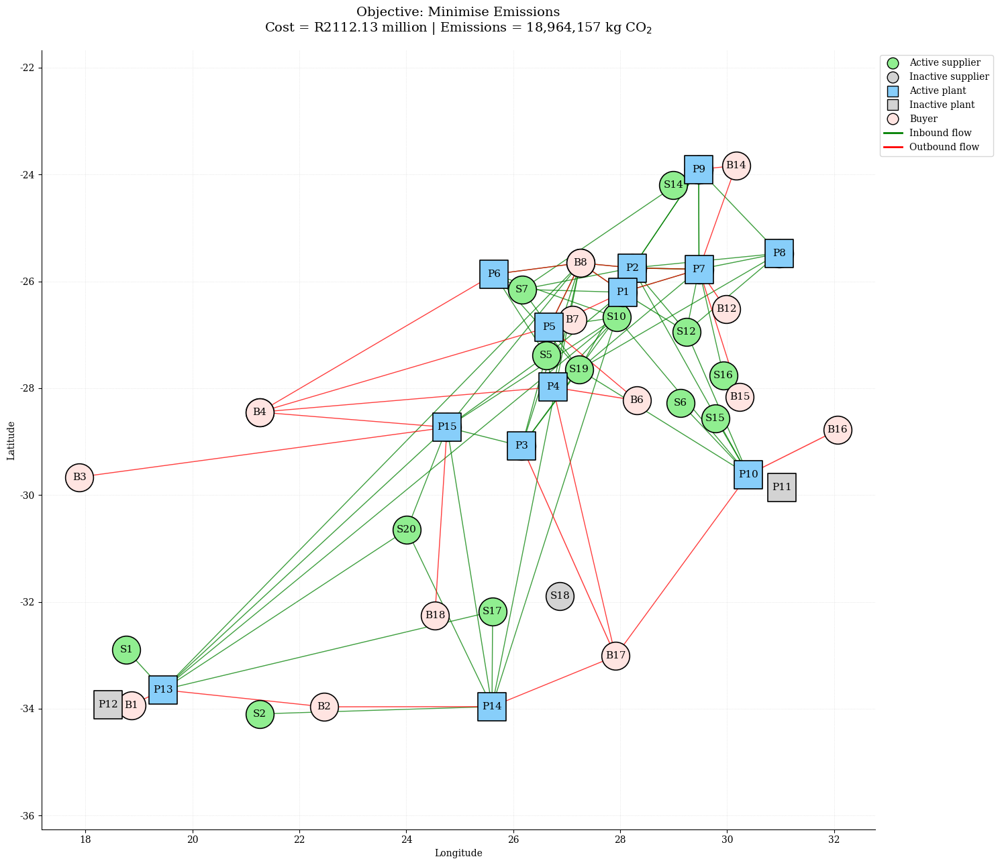

In [11]:
## Min-emissions network plot

Experiments.plot_exp_solution(
    results_E2_3_emissions,
    data_E2_3
)

## E3. Candidate plant availability


### E3.1 Limited Plant Availability (few)


In [15]:
data = Functions.load_master_data("Master_Data.xlsx")

data_E3_1 = Functions.build_experiment_data(
    data,
    plants=["P1", "P3", "P7", "P10", "P12"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [16]:
# Min-cost

mdl_E3_1_cost, vars_E3_1_cost = Functions.build_model(data_E3_1, objective="cost")

mdl_E3_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E3_1_cost.parameters.timelimit = 900

results_E3_1_cost = Functions.solve_and_extract(mdl_E3_1_cost, vars_E3_1_cost, data_E3_1, log_output=False)

Experiments.experiment_report(
    results_E3_1_cost,
    mdl_E3_1_cost,
    experiment_id="E3.1",
    scenario_name="Few plant availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E3.1
Scenario   : Few plant availability – min-cost
Objective  : Min-Cost

Objective value : 1,997,452,454.26
Total cost      : R 1,997,452,454.26
Total emissions : 20,853,352.35 kg CO2
Open plants     : P1, P3, P7, P10

--- Cost breakdown ---
raw_material_cost             : R 1,403,767,143.70
inbound_transport_cost        : R 105,065,694.00
production_cost               : R 289,551,772.56
plant_opening_cost            : R 88,591,000.00
outbound_transport_cost       : R 110,476,844.00

--- Emissions breakdown ---
inbound_emissions             : 2,263,686.29 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 3,525,666.05 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,600.00 tonnes
P1 - F4: 8,998.71 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,930.50 tonnes
P3 - F1: 2,576.00 tonnes
P3 - F2: 2,786.00 tonnes
P3 - F3: 11,800.00 tonnes
P3 - F4: 3,200.00 tonnes
P3 - F5: 11,197.91

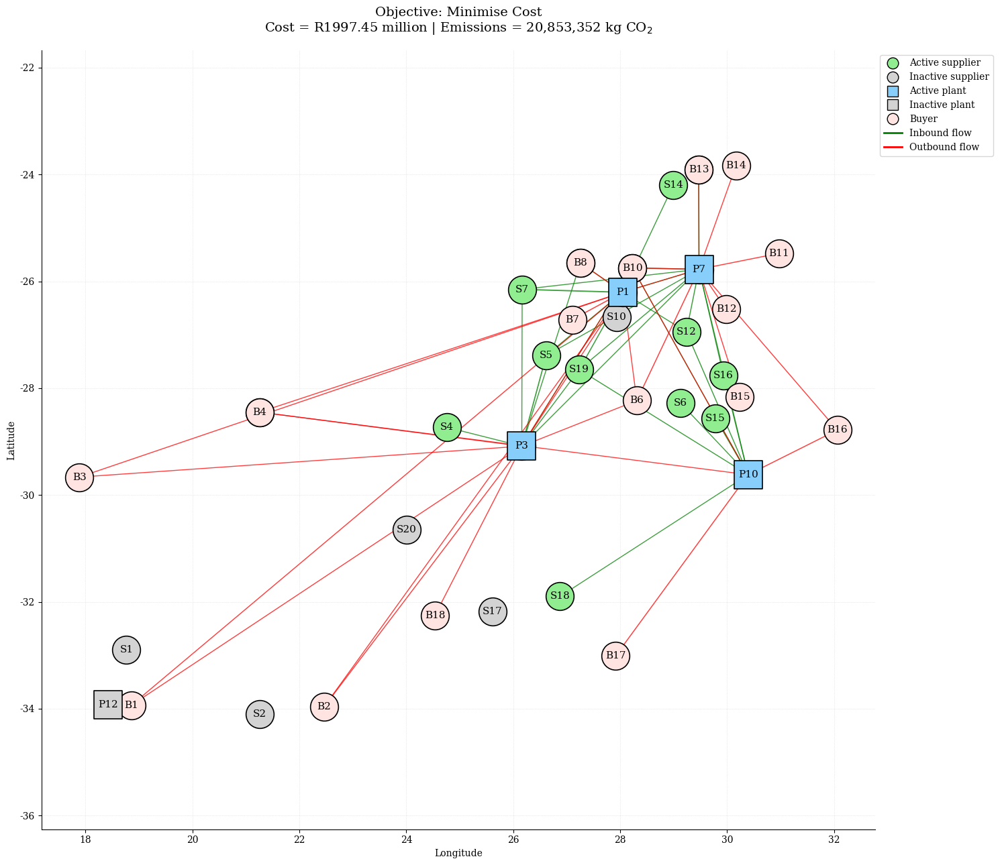

In [17]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E3_1_cost,
    data_E3_1,
    coord_file="Master_Coordinates.xlsx"
)

In [18]:
# Min-emissions

mdl_E3_1_emissions, vars_E3_1_emissions = Functions.build_model(data_E3_1, objective="emissions")

mdl_E3_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E3_1_emissions.parameters.timelimit = 900

results_E3_1_emissions = Functions.solve_and_extract(mdl_E3_1_emissions, vars_E3_1_emissions, data_E3_1, log_output=False)

Experiments.experiment_report(
    results_E3_1_emissions,
    mdl_E3_1_emissions,
    experiment_id="E3.1",
    scenario_name="Few plant availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E3.1
Scenario   : Few plant availability – min-emissions
Objective  : Min-Emissions

Objective value : 19,890,995.77
Total cost      : R 2,072,923,774.00
Total emissions : 19,890,995.77 kg CO2
Open plants     : P1, P3, P7, P10, P12

--- Cost breakdown ---
raw_material_cost             : R 1,455,212,990.00
inbound_transport_cost        : R 117,355,088.00
production_cost               : R 290,584,502.00
plant_opening_cost            : R 134,039,000.00
outbound_transport_cost       : R 75,732,194.00

--- Emissions breakdown ---
inbound_emissions             : 2,421,389.68 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,405,606.09 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,600.00 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 32,000.00 tonnes
P3 - F1: 2,574.00 tonnes
P3 - F2: 2,800.00 tonnes
P3 - F3: 11,800.00 tonnes
P3 - F4: 3,200.00 tonnes
P3 - F

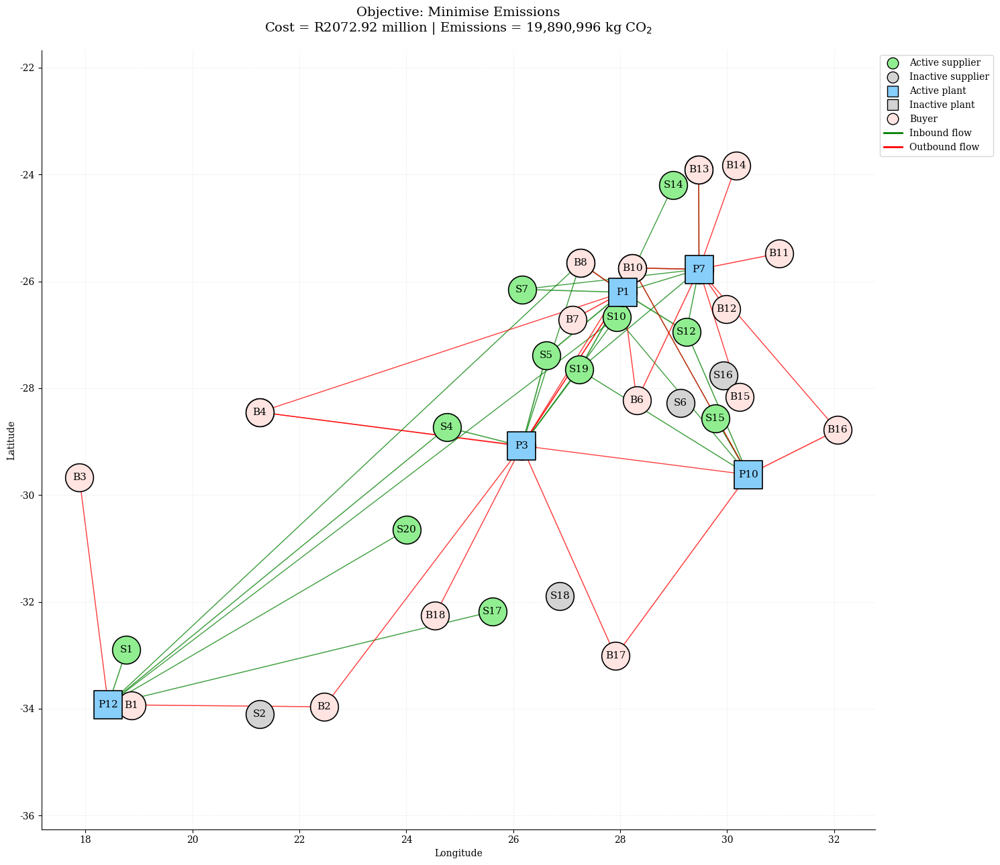

In [19]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E3_1_emissions,
    data_E3_1,
    coord_file="Master_Coordinates.xlsx"
)

Running E3.1.01 of E3.1.21 | Emissions cap: 20,853,352.35 kg CO2
Running E3.1.02 of E3.1.21 | Emissions cap: 20,805,234.52 kg CO2
Running E3.1.03 of E3.1.21 | Emissions cap: 20,757,116.69 kg CO2
Running E3.1.04 of E3.1.21 | Emissions cap: 20,708,998.86 kg CO2
Running E3.1.05 of E3.1.21 | Emissions cap: 20,660,881.03 kg CO2
Running E3.1.06 of E3.1.21 | Emissions cap: 20,612,763.21 kg CO2
Running E3.1.07 of E3.1.21 | Emissions cap: 20,564,645.38 kg CO2
Running E3.1.08 of E3.1.21 | Emissions cap: 20,516,527.55 kg CO2
Running E3.1.09 of E3.1.21 | Emissions cap: 20,468,409.72 kg CO2
Running E3.1.10 of E3.1.21 | Emissions cap: 20,420,291.89 kg CO2
Running E3.1.11 of E3.1.21 | Emissions cap: 20,372,174.06 kg CO2
Running E3.1.12 of E3.1.21 | Emissions cap: 20,324,056.23 kg CO2
Running E3.1.13 of E3.1.21 | Emissions cap: 20,275,938.40 kg CO2
Running E3.1.14 of E3.1.21 | Emissions cap: 20,227,820.57 kg CO2
Running E3.1.15 of E3.1.21 | Emissions cap: 20,179,702.74 kg CO2
Running E3.1.16 of E3.1.2

,run_id,epsilon,total_cost,total_emissions,open_plants,solve_status,solve_time,mip_gap,number_of_variables,number_of_constraints,number_of_binaries,number_of_integers
0,E3.1.01,2.085335e+07,1.997795e+09,20845710.41,"P1, P3, P7, P10","integer optimal, tolerance",0.812,0.000657,61635,62024,5,30800
1,E3.1.02,2.080523e+07,1.998184e+09,20805234.52,"P1, P3, P7, P10","integer optimal, tolerance",2.063,0.000473,61635,62024,5,30800
2,E3.1.03,2.075712e+07,2.000420e+09,20757116.69,"P1, P3, P7, P10","integer optimal, tolerance",3.109,0.000661,61635,62024,5,30800
3,E3.1.04,2.070900e+07,2.005201e+09,20708998.86,"P1, P3, P7, P10","integer optimal, tolerance",2.484,0.000840,61635,62024,5,30800
4,E3.1.05,2.066088e+07,2.010846e+09,20660881.03,"P1, P3, P7, P10","integer optimal, tolerance",3.609,0.000872,61635,62024,5,30800
5,E3.1.06,2.061276e+07,2.016945e+09,20612763.21,"P1, P3, P7, P10","integer optimal, tolerance",4.141,0.000593,61635,62024,5,30800
6,E3.1.07,2.056465e+07,2.026330e+09,20564645.38,"P1, P3, P7, P10","integer optimal, tolerance",2.375,0.000726,61635,62024,5,30800
7,E3.1.08,2.051653e+07,2.030132e+09,20312998.83,"P1, P3, P7, P10, P12","integer optimal, tolerance",3.687,0.000433,61635,62024,5,30800
8,E3.1.09,2.046841e+07,2.030910e+09,20301992.22,"P1, P3, P7, P10, P12","integer optimal, tolerance",4.453,0.000816,61635,62024,5,30800
9,E3.1.10,2.042029e+07,2.030431e+09,20312950.89,"P1, P3, P7, P10, P12","integer optimal, tolerance",3.984,0.000576,61635,62024,5,30800


,Point,Total emissions (kg CO2),Total cost (R)
0,E3.1.01,"20,845,710.41","1,997,794,876.00"
1,E3.1.02,"20,805,234.52","1,998,183,674.74"
2,E3.1.03,"20,757,116.69","2,000,420,095.05"
3,E3.1.04,"20,708,998.86","2,005,201,321.52"
4,E3.1.05,"20,660,881.03","2,010,846,438.06"
5,E3.1.06,"20,612,763.21","2,016,945,330.60"
6,E3.1.07,"20,564,645.38","2,026,330,486.76"
7,E3.1.08,"20,312,998.83","2,030,131,635.98"
8,E3.1.09,"20,301,992.22","2,030,910,357.05"
9,E3.1.10,"20,312,950.89","2,030,430,815.27"


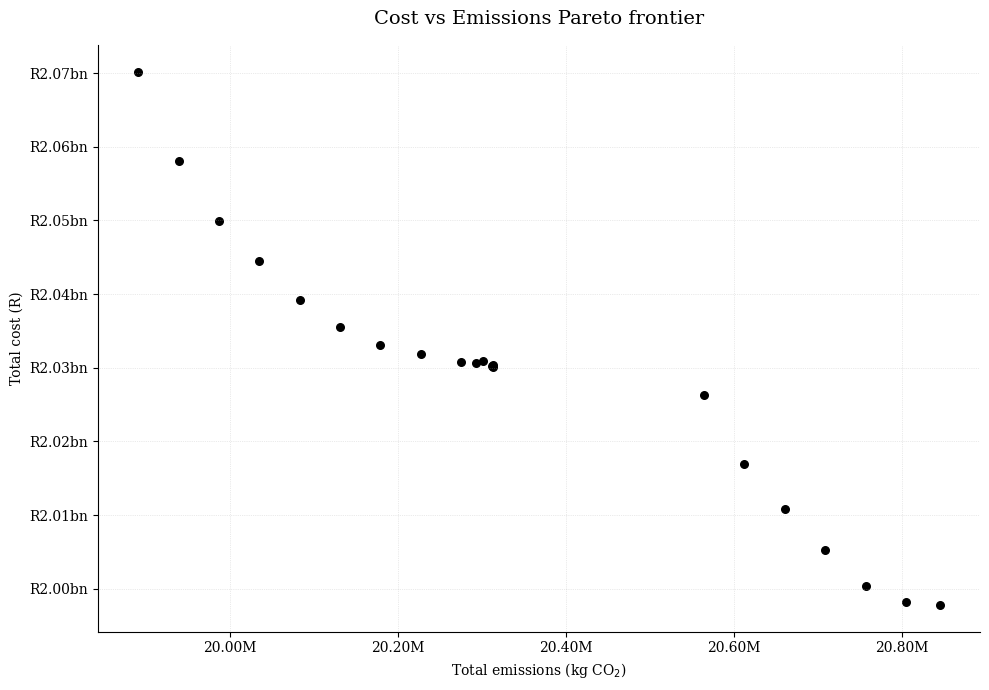

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Cost vs Emissions Pareto frontier'}, xlabel='Total emissions (kg CO$_2$)', ylabel='Total cost (R)'>)

In [20]:
## Pareto E3.1

results_E3_1, pareto_E3_1 = Experiments.pareto_results(
    data_E3_1,
    results_E3_1_cost,
    results_E3_1_emissions,
    experiment_id="E3.1",
    time_limit=600
)

pareto_table_E3_1 = Experiments.pareto_table(
    pareto_E3_1
)

Experiments.pareto_plot(
    pareto_E3_1, 
    label_points=False,
)

### E3.2 Meduim Plant Availability (many)

In [17]:
data_E3_2 = Functions.build_experiment_data(
    data,
    plants=["P1", "P3", "P5", "P7", "P8", "P10", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [18]:
# Min-cost

mdl_E3_2_cost, vars_E3_2_cost = Functions.build_model(data_E3_2, objective="cost")

mdl_E3_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E3_2_cost.parameters.timelimit = 900

results_E3_2_cost = Functions.solve_and_extract(mdl_E3_2_cost, vars_E3_2_cost, data_E3_2, log_output=False)

Experiments.experiment_report(
    results_E3_2_cost,
    mdl_E3_2_cost,
    experiment_id="E3.2",
    scenario_name="Medium plant availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E3.2
Scenario   : Medium plant availability – min-cost
Objective  : Min-Cost

Objective value : 1,967,353,149.68
Total cost      : R 1,967,353,149.68
Total emissions : 20,037,346.99 kg CO2
Open plants     : P1, P3, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,399,702,273.38
inbound_transport_cost        : R 105,299,930.00
production_cost               : R 288,709,184.30
plant_opening_cost            : R 89,217,000.00
outbound_transport_cost       : R 84,424,762.00

--- Emissions breakdown ---
inbound_emissions             : 2,283,381.16 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,689,965.83 kg CO2

--- Production ---
P1 - F1: 7,396.40 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 31,834.00 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 27,792.00 tonnes
P1 - F6: 25,159.43 tonnes
P3 - F1: 1,026.70 tonnes
P3 - F2: 1,370.00 tonnes
P3 - F3: 11,762.00 tonnes
P3 - F4: 3,026.00 tonnes
P3 - F5: 11,

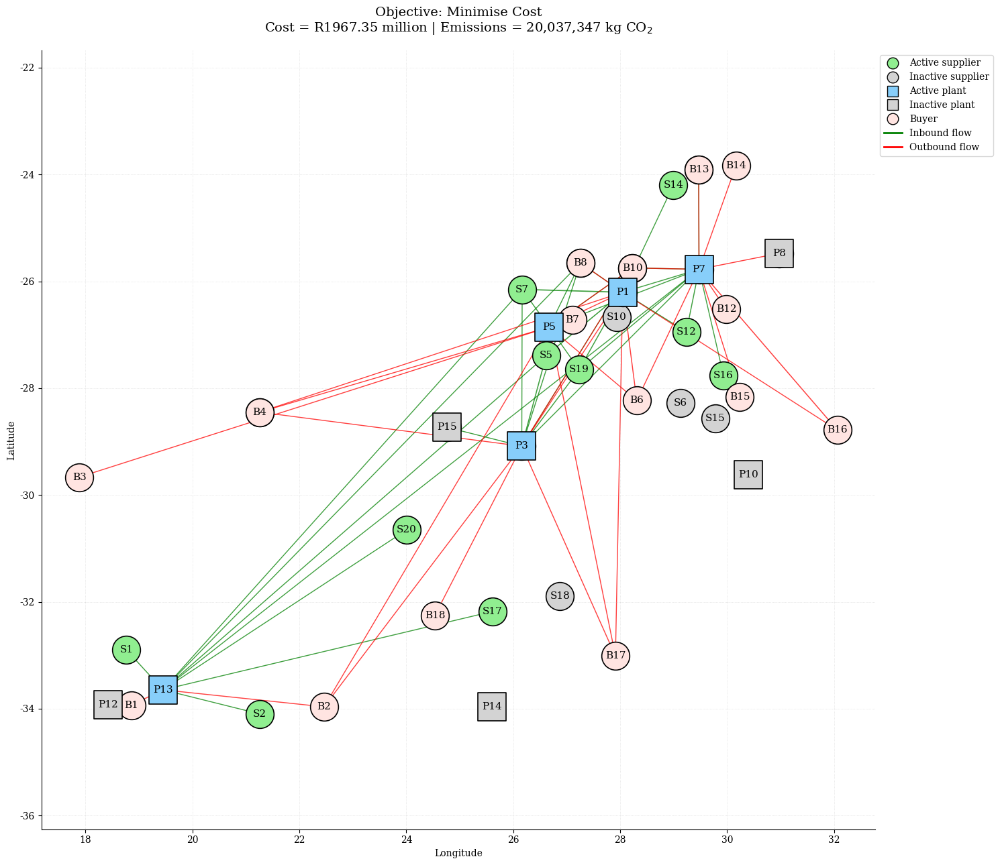

In [19]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E3_2_cost,
    data_E3_2,
    coord_file="Master_Coordinates.xlsx"
)

In [20]:
# Min-emissions

mdl_E3_2_emissions, vars_E3_2_emissions = Functions.build_model(data_E3_2, objective="emissions")

mdl_E3_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E3_2_emissions.parameters.timelimit = 900

results_E3_2_emissions = Functions.solve_and_extract(mdl_E3_2_emissions, vars_E3_2_emissions, data_E3_2, log_output=False)

Experiments.experiment_report(
    results_E3_2_emissions,
    mdl_E3_2_emissions,
    experiment_id="E3.2",
    scenario_name="Medium plant availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E3.2
Scenario   : Medium plant availability – min-emissions
Objective  : Min-Emissions

Objective value : 19,244,006.27
Total cost      : R 2,045,261,732.00
Total emissions : 19,244,006.27 kg CO2
Open plants     : P1, P3, P5, P7, P8, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,452,199,404.00
inbound_transport_cost        : R 104,916,216.00
production_cost               : R 294,018,318.00
plant_opening_cost            : R 130,777,000.00
outbound_transport_cost       : R 63,350,794.00

--- Emissions breakdown ---
inbound_emissions             : 2,164,762.25 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,015,244.02 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 11,868.00 tonnes
P1 - F4: 7,090.00 tonnes
P1 - F5: 23,970.00 tonnes
P1 - F6: 25,470.00 tonnes
P3 - F3: 11,800.00 tonnes
P3 - F4: 1,530.00 tonnes
P3 - F5: 10,640.00 tonnes
P3 - F6: 

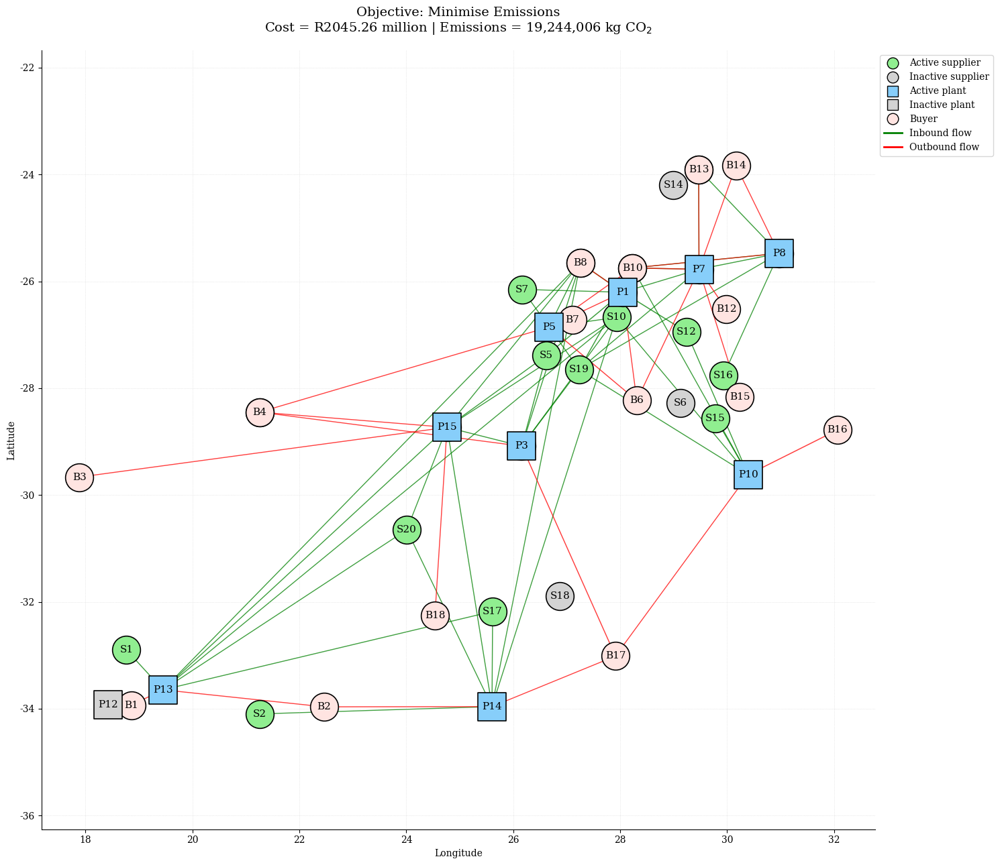

In [21]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E3_2_emissions,
    data_E3_2,
    coord_file="Master_Coordinates.xlsx"
)


### E3.3 Full Plant Availability (all)
didn't run - same as E1.1 & E1.2

In [ ]:
data_E3_3 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [ ]:
# Min-cost

mdl_E3_3_cost, vars_E3_3_cost = Functions.build_model(data_E3_3, objective="cost")

mdl_E3_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E3_3_cost.parameters.timelimit = 900

results_E3_3_cost = Functions.solve_and_extract(mdl_E3_3_cost, vars_E3_3_cost, data_E3_3, log_output=False)

Experiments.experiment_report(
    results_E3_3_cost,
    mdl_E3_3_cost,
    experiment_id="E3.3",
    scenario_name="Many plant availability – min-cost",
    objective_name="Min-Cost"
)

In [ ]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E3_3_cost,
    data_E3_3,
    coord_file="Master_Coordinates.xlsx"
)

In [ ]:
# Min-emissions

mdl_E3_3_emissions, vars_E3_3_emissions = Functions.build_model(data_E3_3, objective="emissions")

mdl_E3_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E3_3_emissions.parameters.timelimit = 900

results_E3_3_emissions = Functions.solve_and_extract(mdl_E3_3_emissions, vars_E3_3_emissions, data_E3_3, log_output=False)

Experiments.experiment_report(
    results_E3_3_emissions,
    mdl_E3_3_emissions,
    experiment_id="E3.3",
    scenario_name="Many plant availability – min-emissions",
    objective_name="Min-Emissions"
)

In [ ]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E3_3_emissions,
    data_E3_3,
    coord_file="Master_Coordinates.xlsx"
)

## E4. Buyer / distribution network scale


### E4.1 Few Buyers

In [22]:
data = Functions.load_master_data("Master_Data.xlsx")

data_E4_1 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B5", "B7", "B9", "B11", "B16"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [23]:
# Min-cost

mdl_E4_1_cost, vars_E4_1_cost = Functions.build_model(data_E4_1, objective="cost")

mdl_E4_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E4_1_cost.parameters.timelimit = 900

results_E4_1_cost = Functions.solve_and_extract(mdl_E4_1_cost, vars_E4_1_cost, data_E4_1, log_output=False)

Experiments.experiment_report(
    results_E4_1_cost,
    mdl_E4_1_cost,
    experiment_id="E4.1",
    scenario_name="Few buyer availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E4.1
Scenario   : Few buyer availability – min-cost
Objective  : Min-Cost

Objective value : 843,023,384.50
Total cost      : R 843,023,384.50
Total emissions : 8,712,798.01 kg CO2
Open plants     : P4, P5, P7

--- Cost breakdown ---
raw_material_cost             : R 610,273,662.33
inbound_transport_cost        : R 22,602,564.00
production_cost               : R 122,440,931.17
plant_opening_cost            : R 34,195,000.00
outbound_transport_cost       : R 53,511,227.00

--- Emissions breakdown ---
inbound_emissions             : 434,297.27 kg CO2
plant_emissions               : 6,573,000.00 kg CO2
outbound_emissions            : 1,705,500.74 kg CO2

--- Production ---
P4 - F3: 5,800.00 tonnes
P4 - F5: 5,600.00 tonnes
P4 - F6: 5,800.00 tonnes
P5 - F1: 2,571.17 tonnes
P5 - F2: 2,800.00 tonnes
P5 - F3: 11,800.00 tonnes
P5 - F4: 3,192.00 tonnes
P5 - F5: 11,200.00 tonnes
P5 - F6: 9,270.00 tonnes
P7 - F1: 6,128.83 tonnes
P7 - F2: 5,880.00 tonnes
P7 - F3: 20,

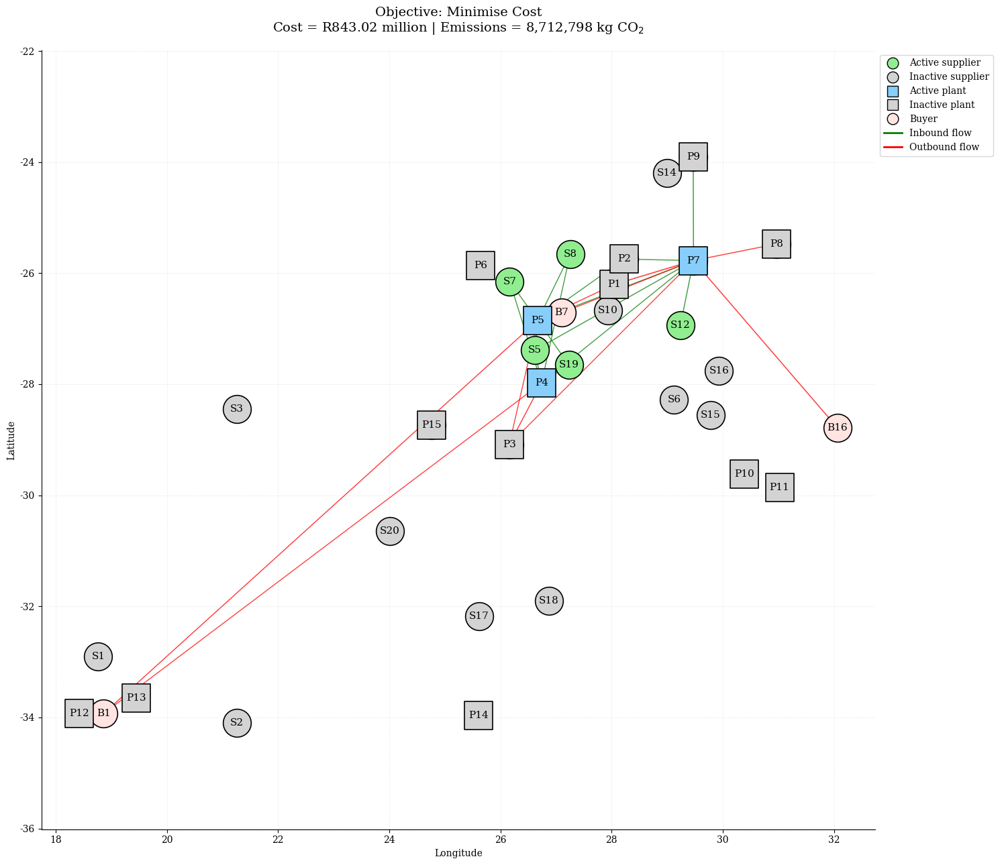

In [24]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E4_1_cost,
    data_E4_1,
    coord_file="Master_Coordinates.xlsx"
)

In [25]:
# Min-emissions

mdl_E4_1_emissions, vars_E4_1_emissions = Functions.build_model(data_E4_1, objective="emissions")

mdl_E4_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E4_1_emissions.parameters.timelimit = 900

results_E4_1_emissions = Functions.solve_and_extract(mdl_E4_1_emissions, vars_E4_1_emissions, data_E4_1, log_output=False)

Experiments.experiment_report(
    results_E4_1_emissions,
    mdl_E4_1_emissions,
    experiment_id="E4.1",
    scenario_name="Few buyer availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E4.1
Scenario   : Few buyer availability – min-emissions
Objective  : Min-Emissions

Objective value : 7,975,658.55
Total cost      : R 969,337,794.00
Total emissions : 7,975,658.55 kg CO2
Open plants     : P1, P2, P3, P5, P8, P10, P13

--- Cost breakdown ---
raw_material_cost             : R 636,809,214.00
inbound_transport_cost        : R 53,221,854.00
production_cost               : R 130,055,444.00
plant_opening_cost            : R 139,994,000.00
outbound_transport_cost       : R 9,257,282.00

--- Emissions breakdown ---
inbound_emissions             : 1,107,609.35 kg CO2
plant_emissions               : 6,573,000.00 kg CO2
outbound_emissions            : 295,049.20 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 4,960.00 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,250.00 tonnes
P1 - F6: 7,790.00 tonnes
P2 - F1: 1,288.00 tonnes
P2 - F2: 680.00 tonnes
P2 - F5: 80.00 tonnes
P3 - F3: 6,760.00 tonnes
P3 - F5: 5,780.00 

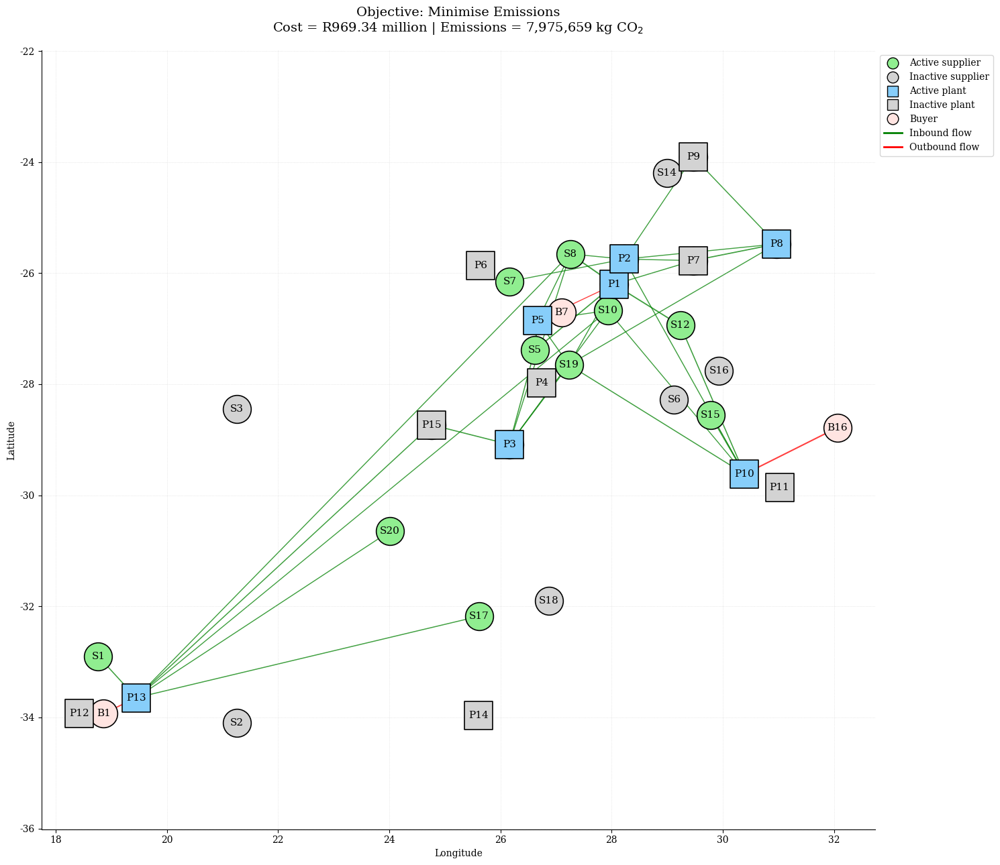

In [26]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E4_1_emissions,
    data_E4_1,
    coord_file="Master_Coordinates.xlsx"
)

### E4.2 - Medium Buyers

In [27]:
data_E4_2 = Functions.build_experiment_data(
    data,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B4", "B5", "B6", "B7", "B9", "B11", "B13", "B15", "B16", "B17"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

In [28]:
# Min-cost

mdl_E4_2_cost, vars_E4_2_cost = Functions.build_model(data_E4_2, objective="cost")

mdl_E4_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E4_2_cost.parameters.timelimit = 900

results_E4_2_cost = Functions.solve_and_extract(mdl_E4_2_cost, vars_E4_2_cost, data_E4_2, log_output=False)

Experiments.experiment_report(
    results_E4_2_cost,
    mdl_E4_2_cost,
    experiment_id="E4.2",
    scenario_name="Medium buyer availability – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E4.2
Scenario   : Medium buyer availability – min-cost
Objective  : Min-Cost

Objective value : 1,304,522,618.50
Total cost      : R 1,304,522,618.50
Total emissions : 13,637,906.46 kg CO2
Open plants     : P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 928,850,677.76
inbound_transport_cost        : R 60,867,317.00
production_cost               : R 190,913,686.73
plant_opening_cost            : R 51,648,000.00
outbound_transport_cost       : R 72,242,937.00

--- Emissions breakdown ---
inbound_emissions             : 1,261,726.78 kg CO2
plant_emissions               : 10,070,500.00 kg CO2
outbound_emissions            : 2,305,679.68 kg CO2

--- Production ---
P3 - F3: 11,529.30 tonnes
P3 - F4: 1,680.00 tonnes
P3 - F5: 11,168.83 tonnes
P3 - F6: 11,104.00 tonnes
P4 - F2: 635.20 tonnes
P4 - F3: 5,797.20 tonnes
P4 - F4: 1,458.00 tonnes
P4 - F5: 5,574.00 tonnes
P4 - F6: 5,754.00 tonnes
P5 - F1: 2,600.00 tonnes
P5 - F2: 2,800.00 

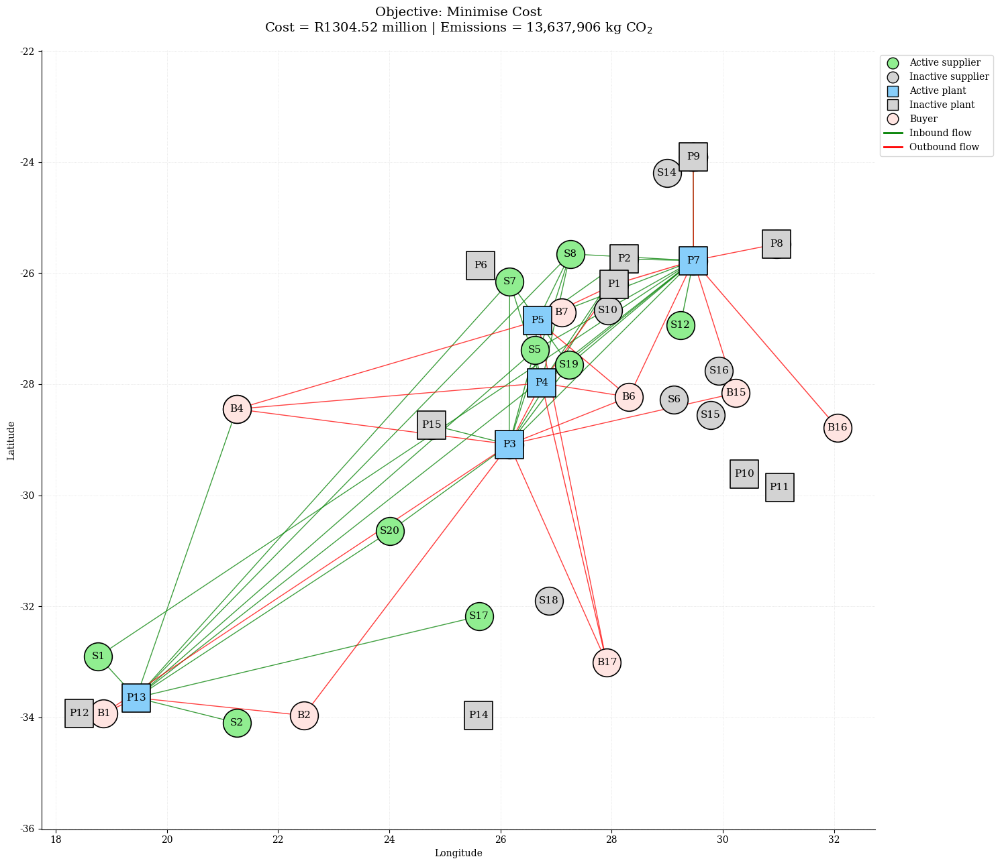

In [29]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E4_2_cost,
    data_E4_2,
    coord_file="Master_Coordinates.xlsx"
)

In [30]:
# Min-emissions

mdl_E4_2_emissions, vars_E4_2_emissions = Functions.build_model(data_E4_2, objective="emissions")

mdl_E4_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E4_2_emissions.parameters.timelimit = 900

results_E4_2_emissions = Functions.solve_and_extract(mdl_E4_2_emissions, vars_E4_2_emissions, data_E4_2, log_output=False)

Experiments.experiment_report(
    results_E4_2_emissions,
    mdl_E4_2_emissions,
    experiment_id="E4.2",
    scenario_name="Medium buyer availability – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E4.2
Scenario   : Medium buyer availability – min-emissions
Objective  : Min-Emissions

Objective value : 12,992,296.07
Total cost      : R 1,487,130,580.00
Total emissions : 12,992,296.07 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 969,144,078.33
inbound_transport_cost        : R 81,571,628.00
production_cost               : R 199,384,931.67
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 37,834,942.00

--- Emissions breakdown ---
inbound_emissions             : 1,721,077.30 kg CO2
plant_emissions               : 10,070,500.00 kg CO2
outbound_emissions            : 1,200,718.77 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 4,961.33 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,262.00 tonnes
P1 - F6: 7,790.00 tonnes
P2 - F1: 1,288.00 tonnes
P2 - F2: 680.00 tonnes
P2 - F5: 80.00 tonnes
P3 - F

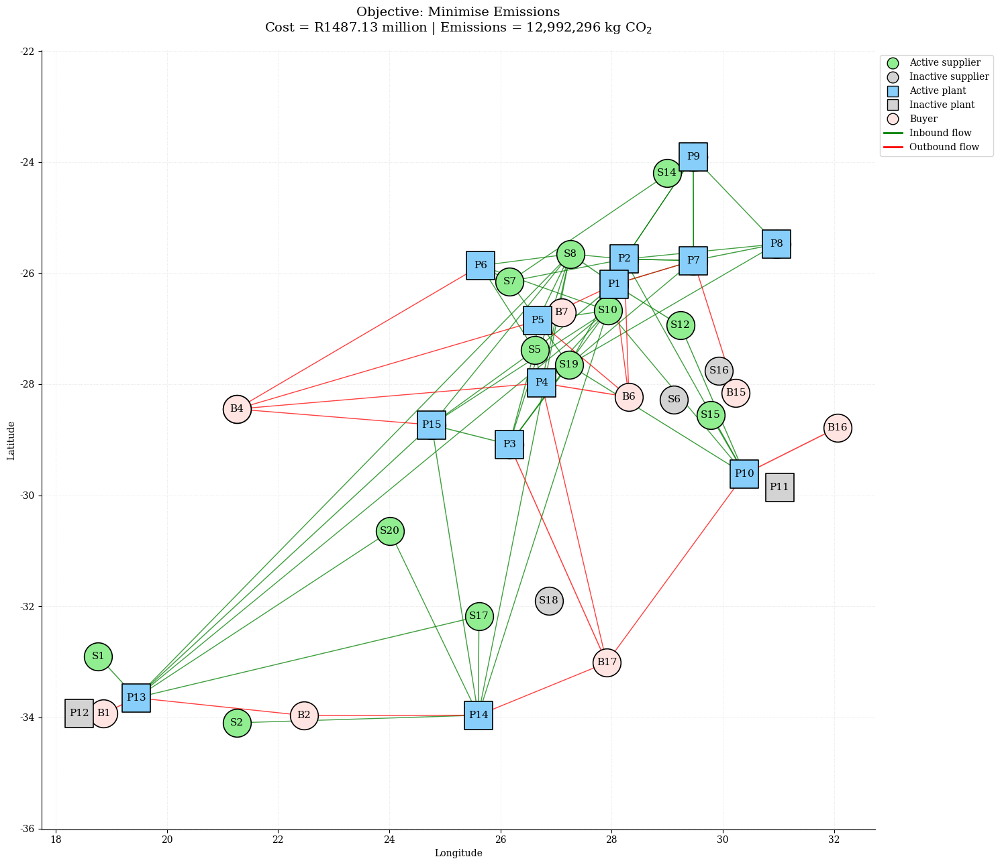

In [31]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E4_2_emissions,
    data_E4_2,
    coord_file="Master_Coordinates.xlsx"
)

### E4.3 All Buyers
didn't run - same as E1.1 & E1.2

## E5. Network flexibility trade-off comparison


### E5.0 — Full network 
(E1.3 configuration)


In [21]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [28]:
results_E1_targets, targets_E1 = Experiments.target_reduction_results(
    data_E1,
    results_E1_1,
    experiment_id="E1",
    time_limit=60
)

Running E1.1% | Emissions reduction: 1% | Emissions cap: 19,974,070.85 kg CO2
Running E1.2% | Emissions reduction: 2% | Emissions cap: 19,772,312.56 kg CO2
Running E1.3% | Emissions reduction: 3% | Emissions cap: 19,570,554.27 kg CO2
Running E1.4% | Emissions reduction: 4% | Emissions cap: 19,368,795.97 kg CO2

Target emissions reduction analysis complete.



,run_id,reduction_target,emissions_cap,total_emissions,actual_emissions_reduction,total_cost,cost_increase,open_plants,solve_status,solve_time,mip_gap
0,E1.1%,1,1.997407e+07,19879148.35,1.470476,1.964408e+09,0.062338,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",43.781,0.000731
1,E1.2%,2,1.977231e+07,19772312.56,2.000000,1.965372e+09,0.111457,"P1, P3, P4, P5, P7, P13",time limit exceeded,60.547,0.000683
2,E1.3%,3,1.957055e+07,19570554.27,3.000000,1.985800e+09,1.152014,"P1, P4, P5, P7, P13, P14, P15",time limit exceeded,60.562,0.007318
3,E1.4%,4,1.936880e+07,19368795.97,4.000000,1.991497e+09,1.442182,"P1, P3, P4, P5, P7, P13, P15","integer optimal, tolerance",42.750,0.000809


### E5.1 — Supplier availability: Restricted suppliers 
(E2.1 configuration)


In [22]:
results_E2_1_targets, targets_E2_1 = Experiments.target_reduction_results(
    data_E2_1,
    results_E2_1_cost,
    experiment_id="E2.1",
    time_limit=60
)

Running E2.1.1% | Emissions reduction: 1% | Emissions cap: 20,187,875.93 kg CO2
Running E2.1.2% | Emissions reduction: 2% | Emissions cap: 19,983,957.99 kg CO2
Running E2.1.3% | Emissions reduction: 3% | Emissions cap: 19,780,040.05 kg CO2
Running E2.1.4% | Emissions reduction: 4% | Emissions cap: 19,576,122.12 kg CO2

Target emissions reduction analysis complete.



,run_id,reduction_target,emissions_cap,total_emissions,actual_emissions_reduction,total_cost,cost_increase,open_plants,solve_status,solve_time,mip_gap
0,E2.1.1%,1,2.018788e+07,20022777.48,1.809632,1.976893e+09,0.121815,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",16.922,0.000674
1,E2.1.2%,2,1.998396e+07,19983957.99,2.000000,1.977077e+09,0.131143,"P1, P3, P4, P5, P7, P13","integer optimal, tolerance",36.328,0.000478
2,E2.1.3%,3,1.978004e+07,19780040.05,3.000000,1.991335e+09,0.853263,"P1, P3, P4, P5, P7, P10, P13","integer optimal, tolerance",12.531,0.000716
3,E2.1.4%,4,1.957612e+07,19576122.12,4.000000,2.012399e+09,1.920050,"P1, P3, P4, P5, P6, P7, P10, P13","integer optimal, tolerance",50.234,0.000871


### E5.2 — Candidate plant availability: Few candidate plants 
(E3.1 configuration)

In [23]:
results_E3_1_targets, targets_E3_1 = Experiments.target_reduction_results(
    data_E3_1,
    results_E3_1_cost,
    experiment_id="E3.1",
    time_limit=60
)

Running E3.1.1% | Emissions reduction: 1% | Emissions cap: 20,644,818.83 kg CO2
Running E3.1.2% | Emissions reduction: 2% | Emissions cap: 20,436,285.30 kg CO2
Running E3.1.3% | Emissions reduction: 3% | Emissions cap: 20,227,751.78 kg CO2
Running E3.1.4% | Emissions reduction: 4% | Emissions cap: 20,019,218.26 kg CO2

Target emissions reduction analysis complete.



,run_id,reduction_target,emissions_cap,total_emissions,actual_emissions_reduction,total_cost,cost_increase,open_plants,solve_status,solve_time,mip_gap
0,E3.1.1%,1,2.064482e+07,20644818.83,1.000000,2.012229e+09,0.739746,"P1, P3, P7, P10","integer optimal, tolerance",10.266,0.000633
1,E3.1.2%,2,2.043629e+07,20305344.28,2.627914,2.030590e+09,1.659000,"P1, P3, P7, P10, P12","integer optimal, tolerance",7.750,0.000659
2,E3.1.3%,3,2.022775e+07,20227751.78,3.000000,2.031549e+09,1.706997,"P1, P3, P7, P10, P12","integer optimal, tolerance",27.125,0.000309
3,E3.1.4%,4,2.001922e+07,20019218.26,4.000000,2.046269e+09,2.443941,"P1, P3, P7, P10, P12","integer optimal, tolerance",7.015,0.000405


## E6 – Demand Distribution Variation


In [36]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>


### E6.0 – Baseline Demand
not showing results bc same as E1


In [40]:
master = Functions.load_master_data("Master_Data.xlsx")

data_E6_0 = Functions.build_experiment_data(
    master,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)


### E6.1 – Eastern Cape Demand +50%


In [43]:
data_E6_1 = Experiments.vary_buyer_demand(data_E6_0, buyers=["B17", "B18"], factor=1.50)

In [44]:
# Min-cost

mdl_E6_1_cost, vars_E6_1_cost = Functions.build_model(data_E6_1, objective="cost")

mdl_E6_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_1_cost.parameters.timelimit = 900

results_E6_1_cost = Functions.solve_and_extract(mdl_E6_1_cost, vars_E6_1_cost, data_E6_1, log_output=False)

Experiments.experiment_report(
    results_E6_1_cost,
    mdl_E6_1_cost,
    experiment_id="E6.1",
    scenario_name="Eastern Cape demand +50% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E6.1
Scenario   : Eastern Cape demand +50% – min-cost
Objective  : Min-Cost

Objective value : 2,045,498,255.00
Total cost      : R 2,045,498,255.00
Total emissions : 20,882,734.15 kg CO2
Open plants     : P1, P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,453,716,386.94
inbound_transport_cost        : R 108,558,826.00
production_cost               : R 300,464,921.06
plant_opening_cost            : R 92,168,000.00
outbound_transport_cost       : R 90,590,121.00

--- Emissions breakdown ---
inbound_emissions             : 2,355,218.97 kg CO2
plant_emissions               : 15,640,000.00 kg CO2
outbound_emissions            : 2,887,515.18 kg CO2

--- Production ---
P1 - F1: 7,382.55 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 26,027.10 tonnes
P1 - F4: 8,978.00 tonnes
P1 - F5: 24,046.00 tonnes
P1 - F6: 30,038.00 tonnes
P3 - F3: 11,800.00 tonnes
P3 - F4: 1,568.00 tonnes
P3 - F5: 11,200.00 tonnes
P3 - F6: 8,487.00 tonnes
P4 - F1:

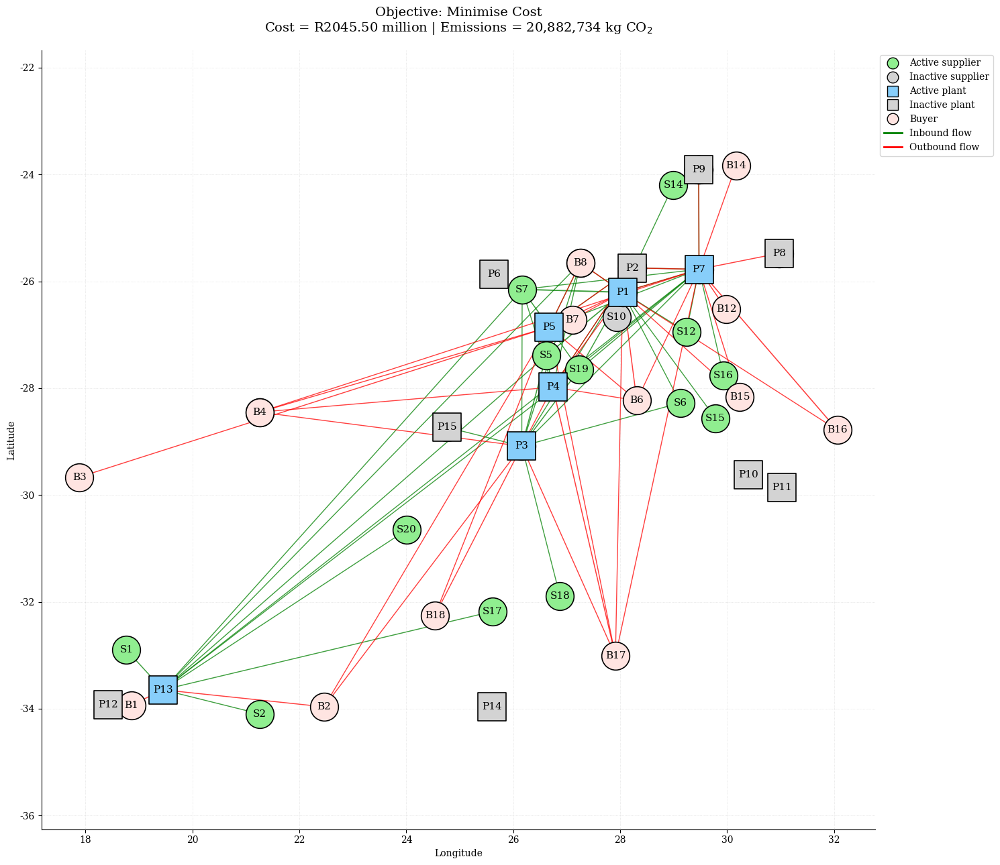

In [45]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E6_1_cost,
    data_E6_1,
    coord_file="Master_Coordinates.xlsx"
)

In [46]:
# Min-emissions

mdl_E6_1_emissions, vars_E6_1_emissions = Functions.build_model(data_E6_1, objective="emissions")

mdl_E6_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_1_emissions.parameters.timelimit = 900

results_E6_1_emissions = Functions.solve_and_extract(mdl_E6_1_emissions, vars_E6_1_emissions, data_E6_1, log_output=False)

Experiments.experiment_report(
    results_E6_1_emissions,
    mdl_E6_1_emissions,
    experiment_id="E6.1",
    scenario_name="Eastern Cape demand +50% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E6.1
Scenario   : Eastern Cape demand +50% – min-emissions
Objective  : Min-Emissions

Objective value : 19,881,829.57
Total cost      : R 2,196,114,940.33
Total emissions : 19,881,829.57 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,509,928,539.67
inbound_transport_cost        : R 118,369,718.00
production_cost               : R 310,672,328.67
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 57,949,354.00

--- Emissions breakdown ---
inbound_emissions             : 2,448,947.24 kg CO2
plant_emissions               : 15,640,000.00 kg CO2
outbound_emissions            : 1,792,882.33 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,450.00 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,910.00 tonnes
P1 - F6: 10,190.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 tonn

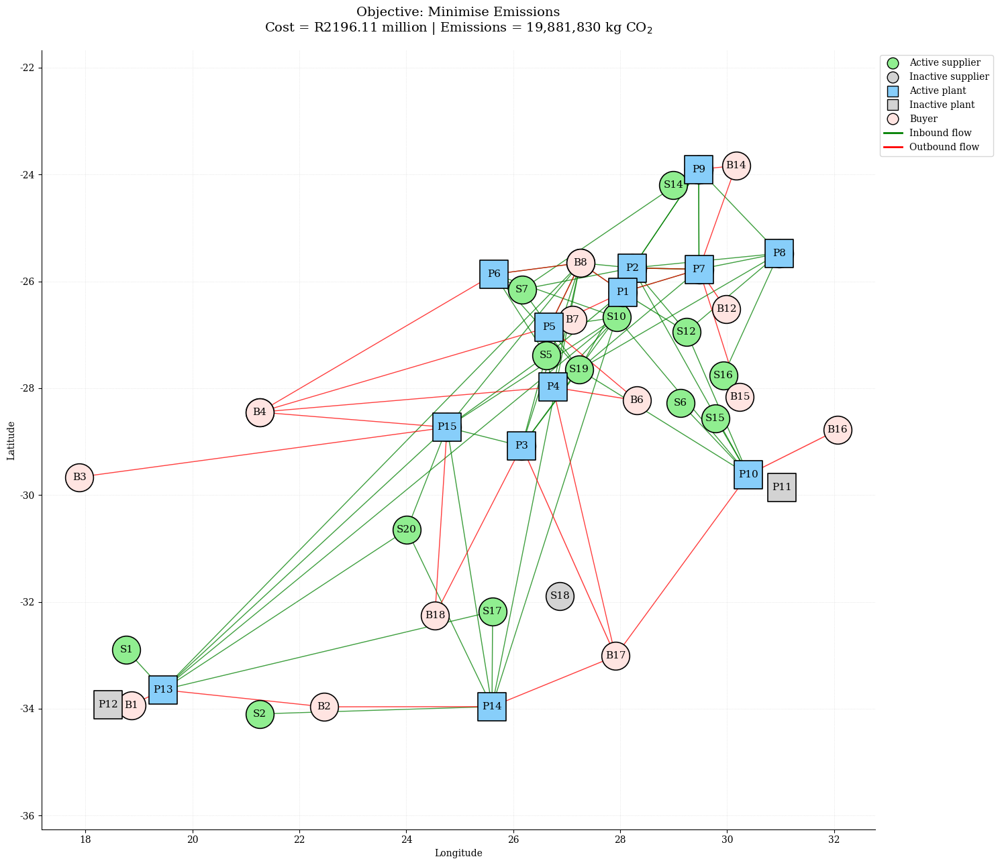

In [47]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E6_1_emissions,
    data_E6_1,
    coord_file="Master_Coordinates.xlsx"
)


### E6.2 – Eastern Cape Demand +100%


In [49]:
data_E6_2 = Experiments.vary_buyer_demand(data_E6_0, buyers=["B17", "B18"], factor=2.00)

In [50]:
# Min-cost

mdl_E6_2_cost, vars_E6_2_cost = Functions.build_model(data_E6_2, objective="cost")

mdl_E6_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_2_cost.parameters.timelimit = 900

results_E6_2_cost = Functions.solve_and_extract(mdl_E6_2_cost, vars_E6_2_cost, data_E6_2, log_output=False)

Experiments.experiment_report(
    results_E6_2_cost,
    mdl_E6_2_cost,
    experiment_id="E6.2",
    scenario_name="Eastern Cape demand +100% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E6.2
Scenario   : Eastern Cape demand +100% – min-cost
Objective  : Min-Cost

Objective value : 2,126,761,365.81
Total cost      : R 2,126,761,365.81
Total emissions : 21,892,800.09 kg CO2
Open plants     : P1, P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,507,920,591.86
inbound_transport_cost        : R 116,576,180.00
production_cost               : R 311,549,839.95
plant_opening_cost            : R 92,168,000.00
outbound_transport_cost       : R 98,546,754.00

--- Emissions breakdown ---
inbound_emissions             : 2,530,997.34 kg CO2
plant_emissions               : 16,216,000.00 kg CO2
outbound_emissions            : 3,145,802.75 kg CO2

--- Production ---
P1 - F1: 7,389.36 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,115.47 tonnes
P1 - F4: 8,981.48 tonnes
P1 - F5: 23,404.67 tonnes
P1 - F6: 29,852.00 tonnes
P3 - F3: 11,782.50 tonnes
P3 - F4: 1,792.00 tonnes
P3 - F5: 11,098.93 tonnes
P3 - F6: 11,498.00 tonnes
P4 - F

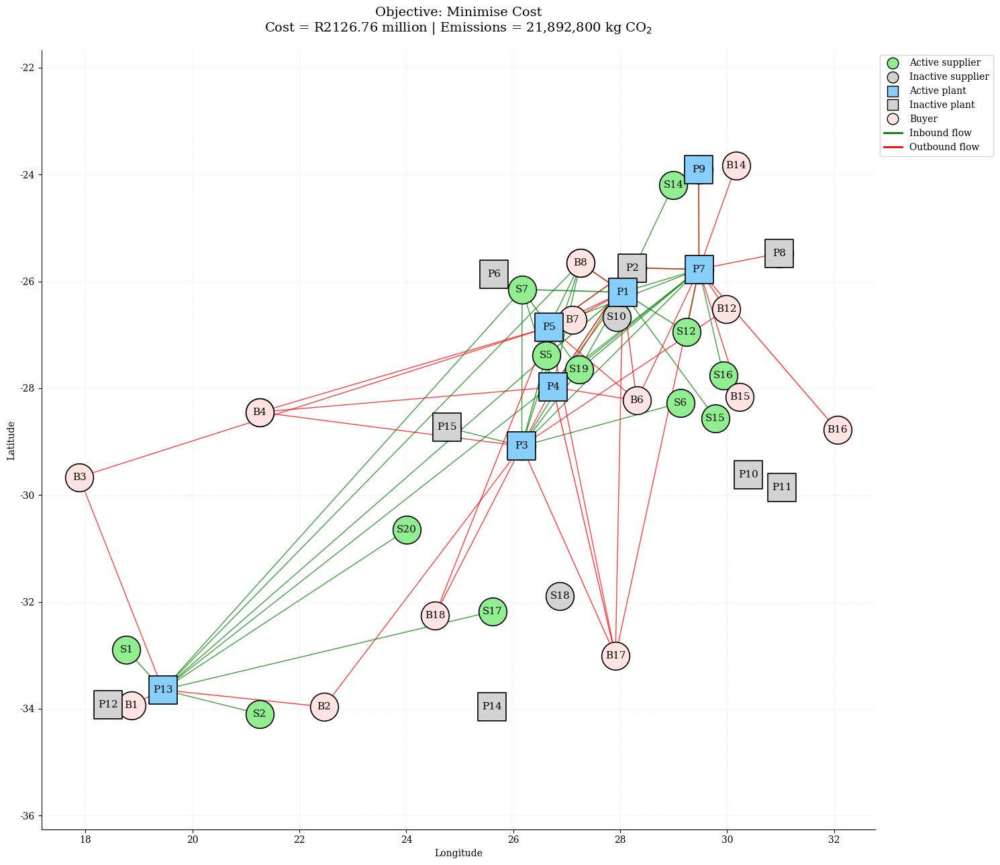

In [51]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E6_2_cost,
    data_E6_2,
    coord_file="Master_Coordinates.xlsx"
)

In [54]:
# Min-emissions

mdl_E6_2_emissions, vars_E6_2_emissions = Functions.build_model(data_E6_2, objective="emissions")

mdl_E6_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_2_emissions.parameters.timelimit = 900

results_E6_2_emissions = Functions.solve_and_extract(mdl_E6_2_emissions, vars_E6_2_emissions, data_E6_2, log_output=False)

Experiments.experiment_report(
    results_E6_2_emissions,
    mdl_E6_2_emissions,
    experiment_id="E6.2",
    scenario_name="Eastern Cape demand +100% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E6.2
Scenario   : Eastern Cape demand +100% – min-emissions
Objective  : Min-Emissions

Objective value : 20,831,845.59
Total cost      : R 2,319,755,385.14
Total emissions : 20,831,845.59 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,565,010,927.71
inbound_transport_cost        : R 125,216,892.00
production_cost               : R 321,887,397.43
plant_opening_cost            : R 245,971,000.00
outbound_transport_cost       : R 61,669,168.00

--- Emissions breakdown ---
inbound_emissions             : 2,656,800.85 kg CO2
plant_emissions               : 16,216,000.00 kg CO2
outbound_emissions            : 1,959,044.74 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 7,994.09 tonnes
P1 - F3: 6,468.00 tonnes
P1 - F4: 6,163.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 10,534.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.0

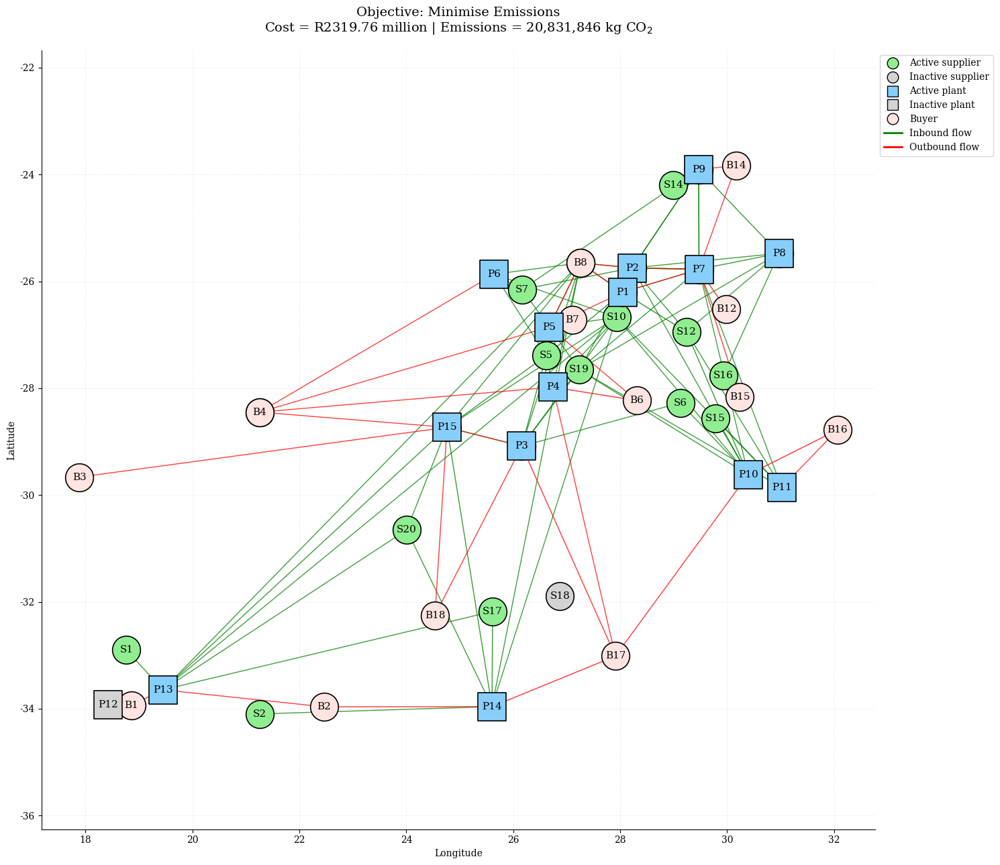

In [53]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E6_2_emissions,
    data_E6_2,
    coord_file="Master_Coordinates.xlsx"
)


### E6.3 – Eastern Cape Demand +150%


In [55]:
data_E6_3 = Experiments.vary_buyer_demand(data_E6_0, buyers=["B17", "B18"], factor=2.50)

In [56]:
# Min-cost

mdl_E6_3_cost, vars_E6_3_cost = Functions.build_model(data_E6_3, objective="cost")

mdl_E6_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_3_cost.parameters.timelimit = 900

results_E6_3_cost = Functions.solve_and_extract(mdl_E6_3_cost, vars_E6_3_cost, data_E6_3, log_output=False)

Experiments.experiment_report(
    results_E6_3_cost,
    mdl_E6_3_cost,
    experiment_id="E6.3",
    scenario_name="Eastern Cape demand +150% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E6.3
Scenario   : Eastern Cape demand +150% – min-cost
Objective  : Min-Cost

Objective value : 2,209,436,422.27
Total cost      : R 2,209,436,422.27
Total emissions : 22,938,722.24 kg CO2
Open plants     : P1, P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,562,750,065.55
inbound_transport_cost        : R 123,997,951.00
production_cost               : R 321,940,275.72
plant_opening_cost            : R 92,168,000.00
outbound_transport_cost       : R 108,580,130.00

--- Emissions breakdown ---
inbound_emissions             : 2,682,409.66 kg CO2
plant_emissions               : 16,792,000.00 kg CO2
outbound_emissions            : 3,464,312.58 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,600.00 tonnes
P1 - F4: 8,958.51 tonnes
P1 - F5: 25,158.00 tonnes
P1 - F6: 30,486.00 tonnes
P3 - F3: 11,799.00 tonnes
P3 - F4: 1,602.00 tonnes
P3 - F5: 11,200.00 tonnes
P3 - F6: 11,568.62 tonnes
P4 - 

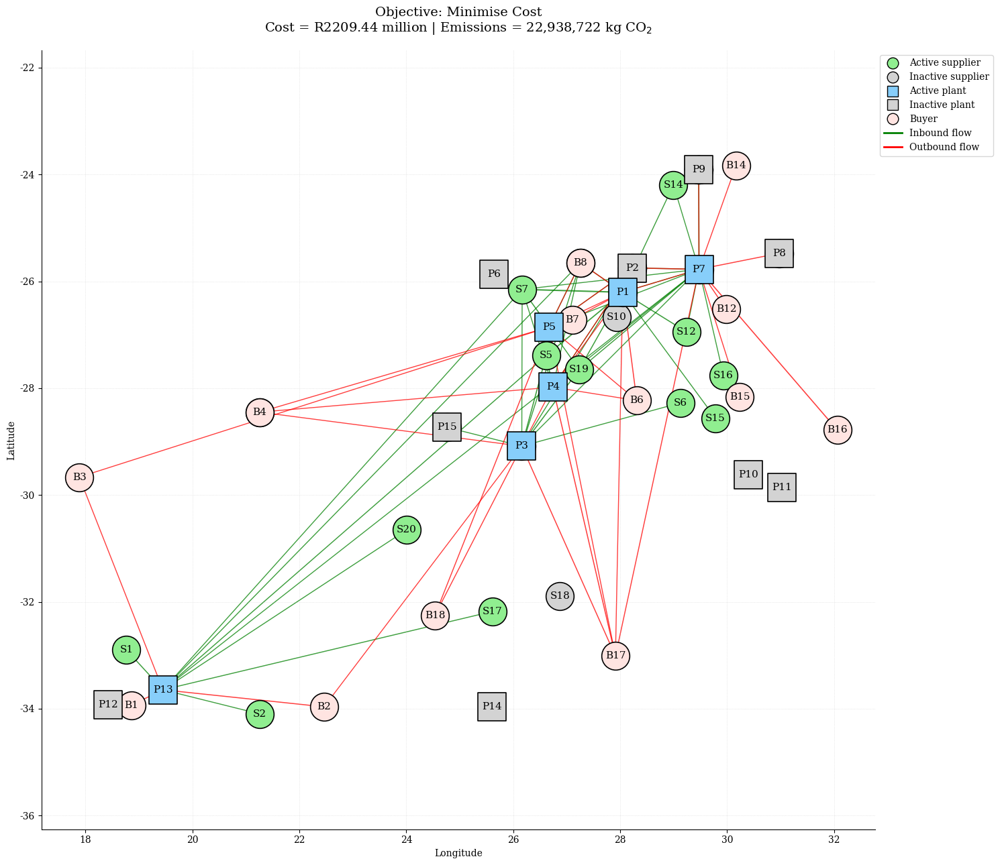

In [57]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E6_3_cost,
    data_E6_3,
    coord_file="Master_Coordinates.xlsx"
)

In [58]:
# Min-emissions

mdl_E6_3_emissions, vars_E6_3_emissions = Functions.build_model(data_E6_3, objective="emissions")

mdl_E6_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_3_emissions.parameters.timelimit = 900

results_E6_3_emissions = Functions.solve_and_extract(mdl_E6_3_emissions, vars_E6_3_emissions, data_E6_3, log_output=False)

Experiments.experiment_report(
    results_E6_3_emissions,
    mdl_E6_3_emissions,
    experiment_id="E6.3",
    scenario_name="Eastern Cape demand +150% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E6.3
Scenario   : Eastern Cape demand +150% – min-emissions
Objective  : Min-Emissions

Objective value : 21,771,444.32
Total cost      : R 2,401,203,946.00
Total emissions : 21,771,444.32 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,619,522,325.00
inbound_transport_cost        : R 134,177,189.00
production_cost               : R 332,622,540.00
plant_opening_cost            : R 245,971,000.00
outbound_transport_cost       : R 68,910,892.00

--- Emissions breakdown ---
inbound_emissions             : 2,831,275.80 kg CO2
plant_emissions               : 16,792,000.00 kg CO2
outbound_emissions            : 2,148,168.52 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,450.00 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,840.00 tonnes
P1 - F6: 10,550.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.0

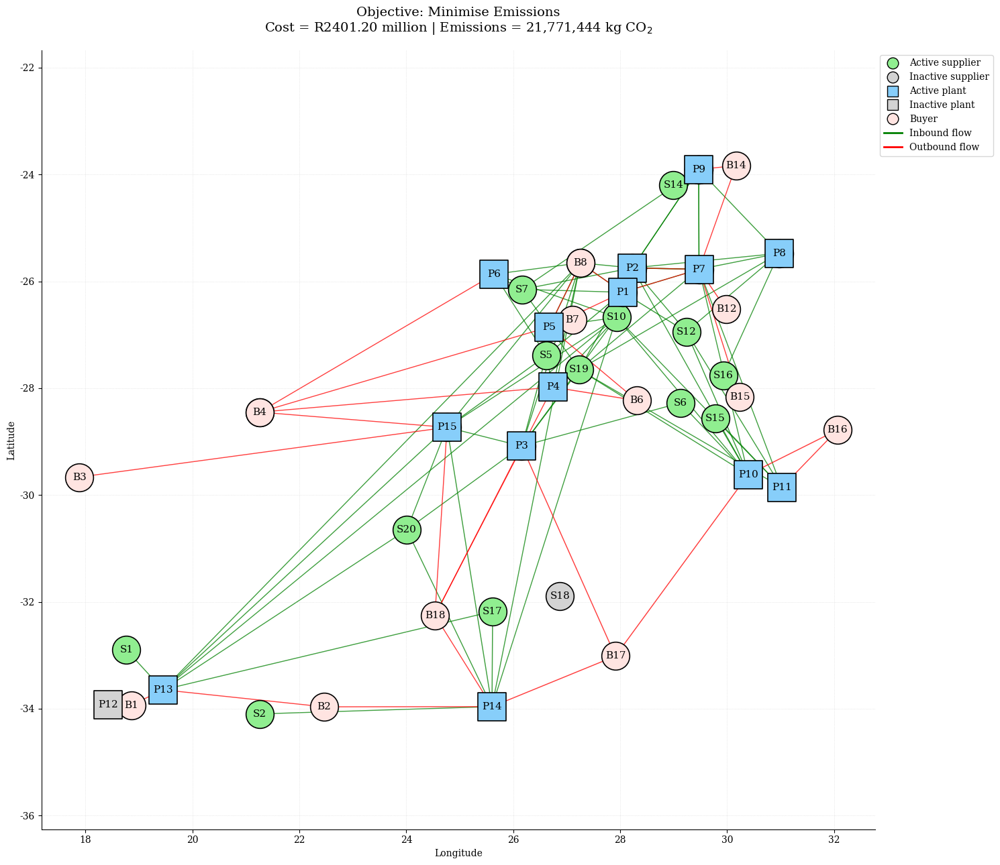

In [59]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E6_3_emissions,
    data_E6_3,
    coord_file="Master_Coordinates.xlsx"
)

### E6 Sensitivity Comparison
no strong visual plots, just gonna do a table & discussion

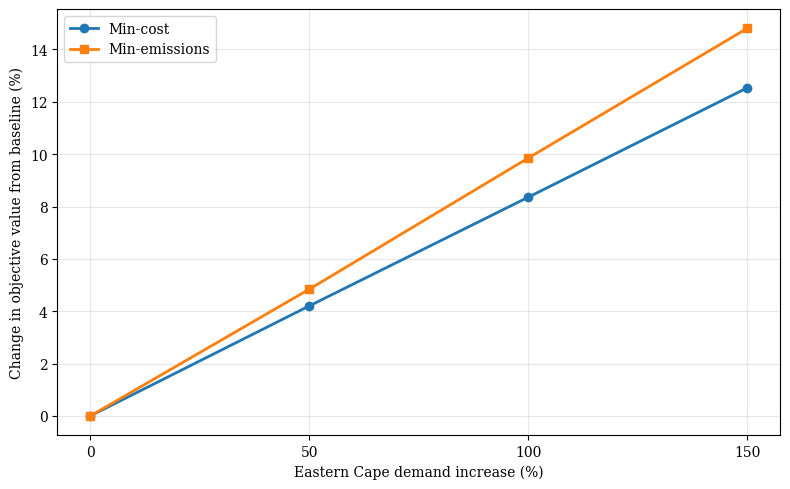

In [ ]:
# Sensitivity Plot: Obejctive values 


import matplotlib.pyplot as plt

# Demand increase (%)
demand_increase = [0, 50, 100, 150]

# Objective values
min_cost = [
    1963000000,       # E6.0 / E1 baseline
    2045498255.00,    # E6.1
    2127000000,       # E6.2
    2209000000        # E6.3
]

min_emissions = [
    18964000,         # E6.0 / E1 baseline
    19881829.57,      # E6.1
    20831845.59,      # E6.2
    21771444.32       # E6.3
]

# Convert to percentage change from baseline
cost_change = [(x / min_cost[0] - 1) * 100 for x in min_cost]
emissions_change = [(x / min_emissions[0] - 1) * 100 for x in min_emissions]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    demand_increase,
    cost_change,
    marker="o",
    linewidth=2,
    label="Min-cost"
)

plt.plot(
    demand_increase,
    emissions_change,
    marker="s",
    linewidth=2,
    label="Min-emissions"
)

plt.xlabel("Eastern Cape demand increase (%)")
plt.ylabel("Change in objective value from baseline (%)")

plt.xticks(demand_increase)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

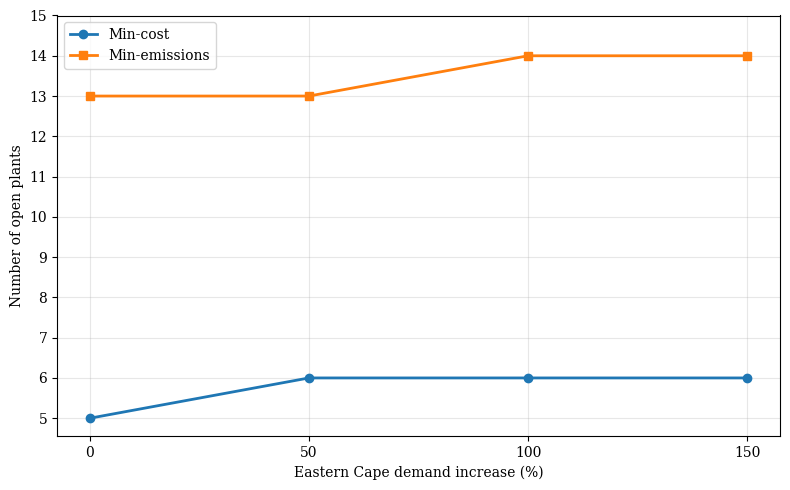

In [ ]:
# Sensitivity Plot: Open plants

import matplotlib.pyplot as plt

# Eastern Cape demand increase (%)
demand_increase = [0, 50, 100, 150]

# Number of open plants
min_cost_plants = [5, 6, 6, 6]
min_emissions_plants = [13, 13, 14, 14]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    demand_increase,
    min_cost_plants,
    marker="o",
    linewidth=2,
    label="Min-cost"
)

plt.plot(
    demand_increase,
    min_emissions_plants,
    marker="s",
    linewidth=2,
    label="Min-emissions"
)

plt.xlabel("Eastern Cape demand increase (%)")
plt.ylabel("Number of open plants")

plt.xticks(demand_increase)
plt.yticks(range(5, 16))

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### 500% test 
don's reported on 

In [60]:
data_E6_5 = Experiments.vary_buyer_demand(data_E6_0, buyers=["B17", "B18"], factor=5)

In [61]:
# Min-cost

mdl_E6_5_cost, vars_E6_5_cost = Functions.build_model(data_E6_5, objective="cost")

mdl_E6_5_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E6_5_cost.parameters.timelimit = 900

results_E6_5_cost = Functions.solve_and_extract(mdl_E6_5_cost, vars_E6_5_cost, data_E6_5, log_output=False)

Experiments.experiment_report(
    results_E6_5_cost,
    mdl_E6_5_cost,
    experiment_id="E6.5",
    scenario_name="Eastern Cape demand +500% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E6.5
Scenario   : Eastern Cape demand +500% – min-cost
Objective  : Min-Cost

Objective value : 2,636,508,338.59
Total cost      : R 2,636,508,338.59
Total emissions : 27,722,684.94 kg CO2
Open plants     : P1, P3, P4, P5, P7, P10, P13, P14

--- Cost breakdown ---
raw_material_cost             : R 1,838,746,178.04
inbound_transport_cost        : R 165,140,472.00
production_cost               : R 377,568,819.54
plant_opening_cost            : R 117,108,000.00
outbound_transport_cost       : R 137,944,869.00

--- Emissions breakdown ---
inbound_emissions             : 3,643,465.30 kg CO2
plant_emissions               : 19,672,000.00 kg CO2
outbound_emissions            : 4,407,219.64 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,600.00 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 24,152.00 tonnes
P1 - F6: 28,490.42 tonnes
P3 - F3: 11,800.00 tonnes
P3 - F4: 1,596.50 tonnes
P3 - F5: 11,156.00 tonnes
P3 - F6: 11,592.33 t

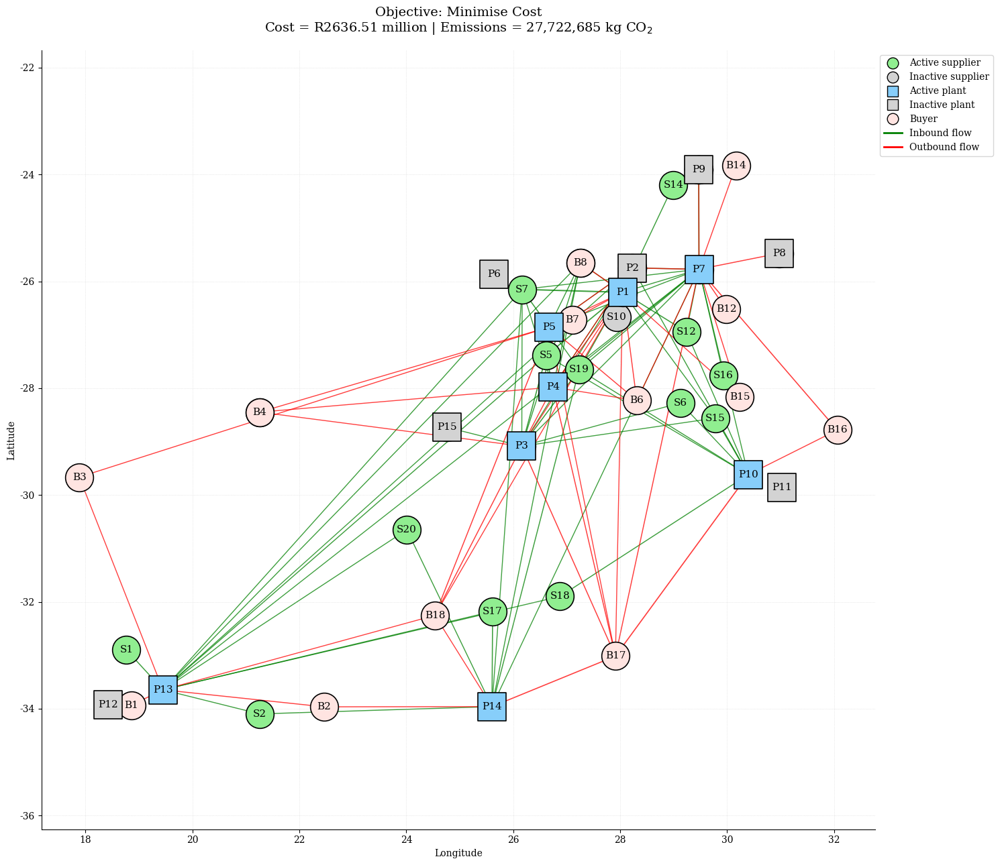

In [62]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E6_5_cost,
    data_E6_5,
    coord_file="Master_Coordinates.xlsx"
)

## E7. Plant capacity variation


In [4]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [5]:
master = Functions.load_master_data("Master_Data.xlsx")

data_E7_0 = Functions.build_experiment_data(
    master,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

### E7.1 – Plant Capacity 75% (25% reduction)

In [6]:
data_E7_1 = Experiments.vary_plant_capacity(data_E7_0, plants=data_E7_0["P"], factor=0.75)

In [7]:
# Min-cost

mdl_E7_1_cost, vars_E7_1_cost = Functions.build_model(data_E7_1, objective="cost")

mdl_E7_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E7_1_cost.parameters.timelimit = 900

results_E7_1_cost = Functions.solve_and_extract(mdl_E7_1_cost, vars_E7_1_cost, data_E7_1, log_output=False)

Experiments.experiment_report(
    results_E7_1_cost,
    mdl_E7_1_cost,
    experiment_id="E7.1",
    scenario_name="Plant capacity 75% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E7.1
Scenario   : Plant capacity 75% – min-cost
Objective  : Min-Cost

Objective value : 1,985,983,766.82
Total cost      : R 1,985,983,766.82
Total emissions : 20,176,573.24 kg CO2
Open plants     : P1, P3, P4, P5, P6, P7, P13, P15

--- Cost breakdown ---
raw_material_cost             : R 1,399,778,926.04
inbound_transport_cost        : R 106,284,290.00
production_cost               : R 291,482,341.78
plant_opening_cost            : R 100,303,000.00
outbound_transport_cost       : R 88,135,209.00

--- Emissions breakdown ---
inbound_emissions             : 2,306,921.87 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,805,651.38 kg CO2

--- Production ---
P1 - F1: 5,550.00 tonnes
P1 - F2: 6,000.00 tonnes
P1 - F3: 24,450.00 tonnes
P1 - F4: 6,750.00 tonnes
P1 - F5: 23,250.00 tonnes
P1 - F6: 23,621.00 tonnes
P3 - F1: 1,950.00 tonnes
P3 - F2: 2,098.00 tonnes
P3 - F3: 8,850.00 tonnes
P3 - F4: 2,400.00 tonnes
P3 - F

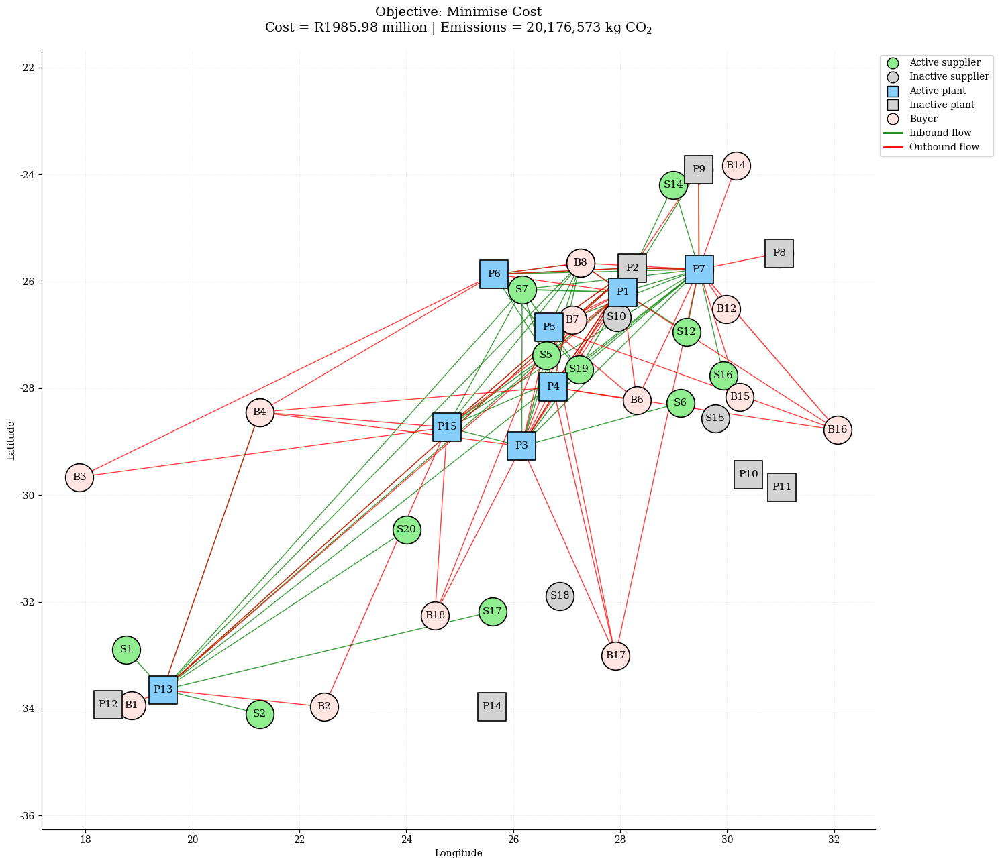

In [8]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E7_1_cost,
    data_E7_1,
    coord_file="Master_Coordinates.xlsx"
)

In [9]:
# Min-emissions

mdl_E7_1_emissions, vars_E7_1_emissions = Functions.build_model(data_E7_1, objective="emissions")

mdl_E7_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E7_1_emissions.parameters.timelimit = 900

results_E7_1_emissions = Functions.solve_and_extract(mdl_E7_1_emissions, vars_E7_1_emissions, data_E7_1, log_output=False)

Experiments.experiment_report(
    results_E7_1_emissions,
    mdl_E7_1_emissions,
    experiment_id="E7.1",
    scenario_name="Plant capacity 75% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E7.1
Scenario   : Plant capacity 75% – min-emissions
Objective  : Min-Emissions

Objective value : 19,035,548.87
Total cost      : R 2,208,849,371.65
Total emissions : 19,035,548.87 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P12, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,455,517,613.13
inbound_transport_cost        : R 111,436,632.00
production_cost               : R 298,605,082.52
plant_opening_cost            : R 291,419,000.00
outbound_transport_cost       : R 51,871,044.00

--- Emissions breakdown ---
inbound_emissions             : 2,324,828.39 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,646,720.48 kg CO2

--- Production ---
P1 - F1: 5,550.00 tonnes
P1 - F2: 6,000.00 tonnes
P1 - F3: 9,411.00 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 11,550.00 tonnes
P1 - F6: 10,572.00 tonnes
P2 - F1: 5,550.00 tonnes
P2 - F2: 6,000.00 tonnes
P2 - F3: 11,410.00

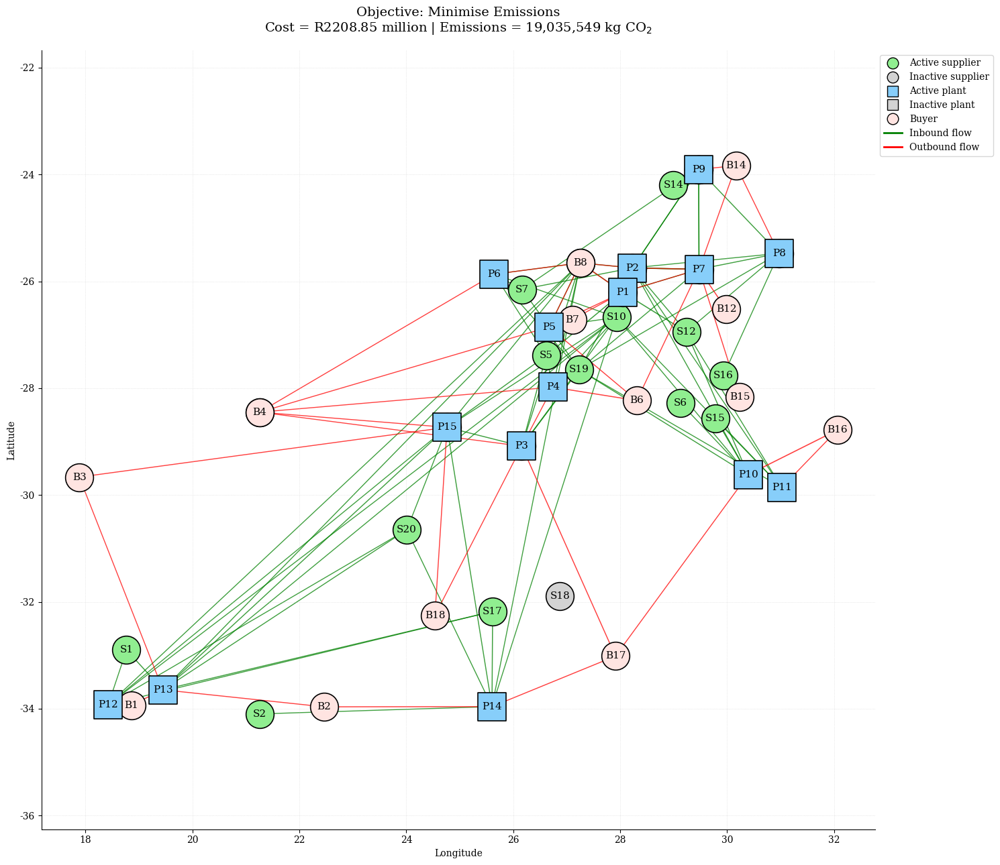

In [10]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E7_1_emissions,
    data_E7_1,
    coord_file="Master_Coordinates.xlsx"
)

### E7.2 – Plant Capacity 50%

In [11]:
data_E7_2 = Experiments.vary_plant_capacity(data_E7_0, plants=data_E7_0["P"], factor=0.50)

In [12]:
# Min-cost

mdl_E7_2_cost, vars_E7_2_cost = Functions.build_model(data_E7_2, objective="cost")

mdl_E7_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E7_2_cost.parameters.timelimit = 900

results_E7_2_cost = Functions.solve_and_extract(mdl_E7_2_cost, vars_E7_2_cost, data_E7_2, log_output=False)

Experiments.experiment_report(
    results_E7_2_cost,
    mdl_E7_2_cost,
    experiment_id="E7.2",
    scenario_name="Plant capacity 50% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E7.2
Scenario   : Plant capacity 50% – min-cost
Objective  : Min-Cost

Objective value : 2,066,777,957.04
Total cost      : R 2,066,777,957.04
Total emissions : 20,135,940.04 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P9, P10, P13, P15

--- Cost breakdown ---
raw_material_cost             : R 1,401,567,460.45
inbound_transport_cost        : R 110,721,996.00
production_cost               : R 295,337,248.59
plant_opening_cost            : R 176,138,000.00
outbound_transport_cost       : R 83,013,252.00

--- Emissions breakdown ---
inbound_emissions             : 2,428,811.04 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,643,129.00 kg CO2

--- Production ---
P1 - F1: 3,700.00 tonnes
P1 - F2: 4,000.00 tonnes
P1 - F3: 16,186.67 tonnes
P1 - F4: 4,500.00 tonnes
P1 - F5: 15,500.00 tonnes
P1 - F6: 16,000.00 tonnes
P2 - F1: 3,700.00 tonnes
P2 - F2: 4,000.00 tonnes
P2 - F3: 15,873.83 tonnes
P2 - F4: 4,500.00

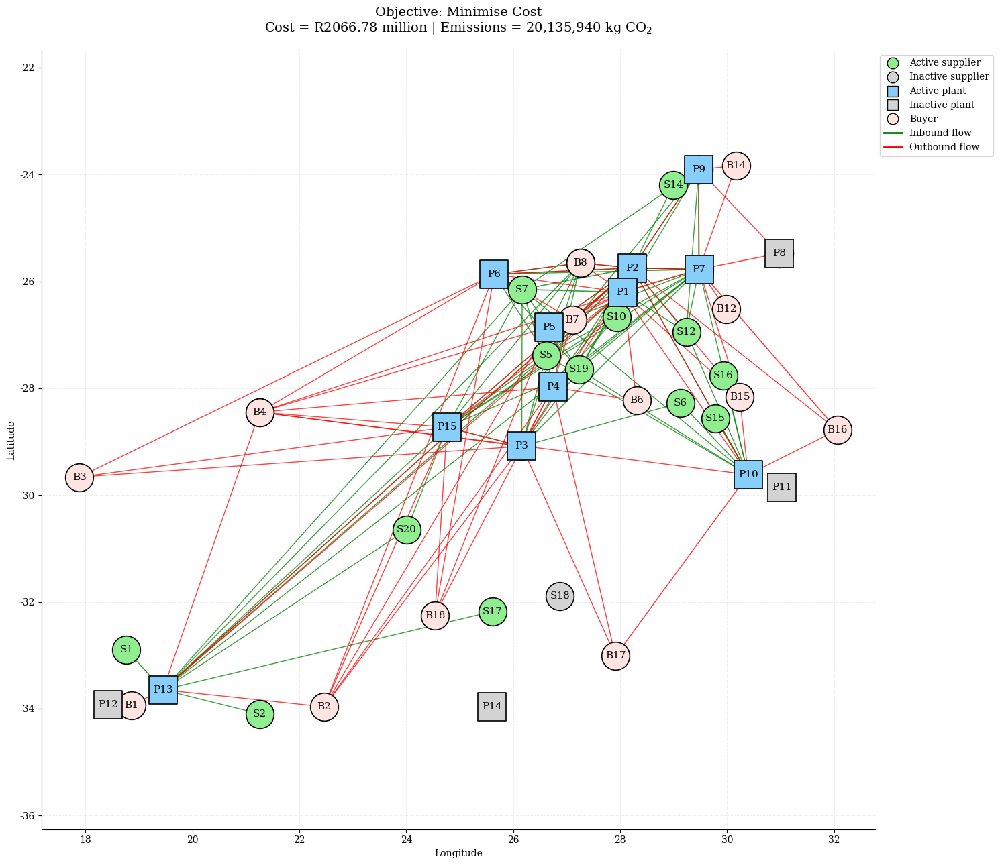

In [13]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E7_2_cost,
    data_E7_2,
    coord_file="Master_Coordinates.xlsx"
)

In [14]:
# Min-emissions

mdl_E7_2_emissions, vars_E7_2_emissions = Functions.build_model(data_E7_2, objective="emissions")

mdl_E7_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E7_2_emissions.parameters.timelimit = 900

results_E7_2_emissions = Functions.solve_and_extract(mdl_E7_2_emissions, vars_E7_2_emissions, data_E7_2, log_output=False)

Experiments.experiment_report(
    results_E7_2_emissions,
    mdl_E7_2_emissions,
    experiment_id="E7.2",
    scenario_name="Plant capacity 50% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E7.2
Scenario   : Plant capacity 50% – min-emissions
Objective  : Min-Emissions

Objective value : 19,401,875.39
Total cost      : R 2,223,256,295.67
Total emissions : 19,401,875.39 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P12, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,457,191,808.33
inbound_transport_cost        : R 119,536,557.00
production_cost               : R 297,276,565.33
plant_opening_cost            : R 291,419,000.00
outbound_transport_cost       : R 57,832,365.00

--- Emissions breakdown ---
inbound_emissions             : 2,509,836.91 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,828,038.48 kg CO2

--- Production ---
P1 - F1: 3,700.00 tonnes
P1 - F2: 4,000.00 tonnes
P1 - F3: 9,488.00 tonnes
P1 - F4: 4,490.00 tonnes
P1 - F5: 14,448.00 tonnes
P1 - F6: 16,000.00 tonnes
P2 - F1: 3,700.00 tonnes
P2 - F2: 4,000.00 tonnes
P2 - F3: 11,416.00

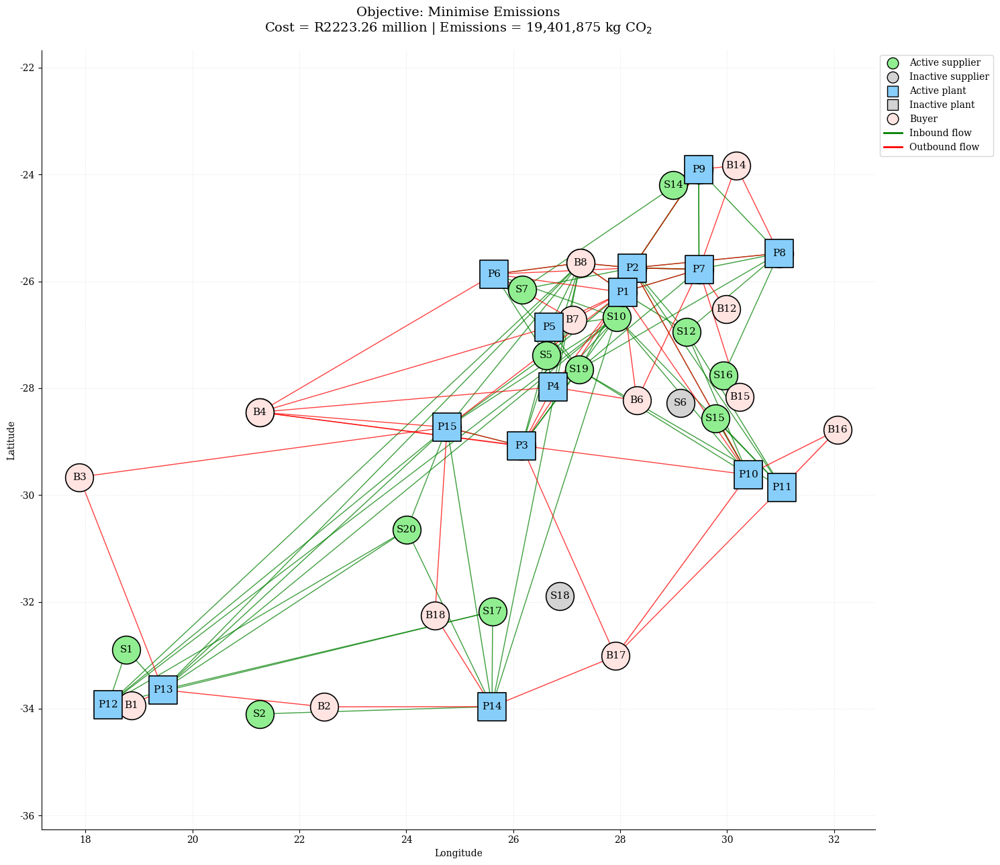

In [15]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E7_2_emissions,
    data_E7_2,
    coord_file="Master_Coordinates.xlsx"
)

### E7.3 – Plant Capacity 35%

In [16]:
data_E7_3 = Experiments.vary_plant_capacity(data_E7_0, plants=data_E7_0["P"], factor=0.35)

In [17]:
# Min-cost

mdl_E7_3_cost, vars_E7_3_cost = Functions.build_model(data_E7_3, objective="cost")

mdl_E7_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E7_3_cost.parameters.timelimit = 900

results_E7_3_cost = Functions.solve_and_extract(mdl_E7_3_cost, vars_E7_3_cost, data_E7_3, log_output=False)

Experiments.experiment_report(
    results_E7_3_cost,
    mdl_E7_3_cost,
    experiment_id="E7.3",
    scenario_name="Plant capacity 35% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E7.3
Scenario   : Plant capacity 35% – min-cost
Objective  : Min-Cost

Objective value : 2,206,057,971.60
Total cost      : R 2,206,057,971.60
Total emissions : 20,947,560.81 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P12, P15

--- Cost breakdown ---
raw_material_cost             : R 1,407,758,505.38
inbound_transport_cost        : R 148,445,512.00
production_cost               : R 295,225,448.22
plant_opening_cost            : R 273,179,000.00
outbound_transport_cost       : R 81,449,506.00

--- Emissions breakdown ---
inbound_emissions             : 3,291,851.84 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,591,708.97 kg CO2

--- Production ---
P1 - F1: 2,590.00 tonnes
P1 - F2: 2,800.00 tonnes
P1 - F3: 11,410.00 tonnes
P1 - F4: 3,150.00 tonnes
P1 - F5: 10,850.00 tonnes
P1 - F6: 11,200.00 tonnes
P2 - F1: 2,590.00 tonnes
P2 - F2: 2,800.00 tonnes
P2 - F3: 11,410.00 tonnes
P2 - F4:

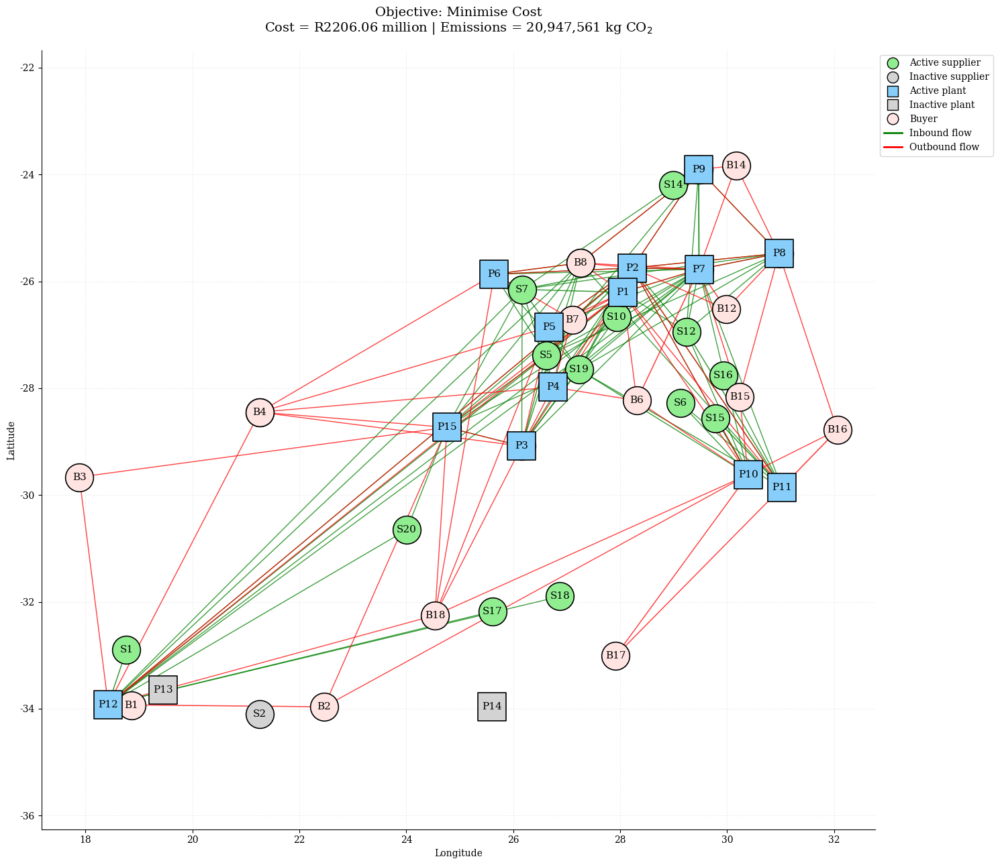

In [18]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E7_3_cost,
    data_E7_3,
    coord_file="Master_Coordinates.xlsx"
)

In [19]:
# Min-emissions

mdl_E7_3_emissions, vars_E7_3_emissions = Functions.build_model(data_E7_3, objective="emissions")

mdl_E7_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E7_3_emissions.parameters.timelimit = 900

results_E7_3_emissions = Functions.solve_and_extract(mdl_E7_3_emissions, vars_E7_3_emissions, data_E7_3, log_output=False)

Experiments.experiment_report(
    results_E7_3_emissions,
    mdl_E7_3_emissions,
    experiment_id="E7.3",
    scenario_name="Plant capacity 35% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E7.3
Scenario   : Plant capacity 35% – min-emissions
Objective  : Min-Emissions

Objective value : 20,221,631.25
Total cost      : R 2,254,258,313.00
Total emissions : 20,221,631.25 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P12, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,459,139,350.00
inbound_transport_cost        : R 134,673,689.00
production_cost               : R 295,912,340.00
plant_opening_cost            : R 291,419,000.00
outbound_transport_cost       : R 73,113,934.00

--- Emissions breakdown ---
inbound_emissions             : 2,851,882.69 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,305,748.56 kg CO2

--- Production ---
P1 - F1: 2,590.00 tonnes
P1 - F2: 2,800.00 tonnes
P1 - F3: 11,410.00 tonnes
P1 - F4: 3,150.00 tonnes
P1 - F5: 10,850.00 tonnes
P1 - F6: 11,200.00 tonnes
P2 - F1: 2,590.00 tonnes
P2 - F2: 2,800.00 tonnes
P2 - F3: 11,410.0

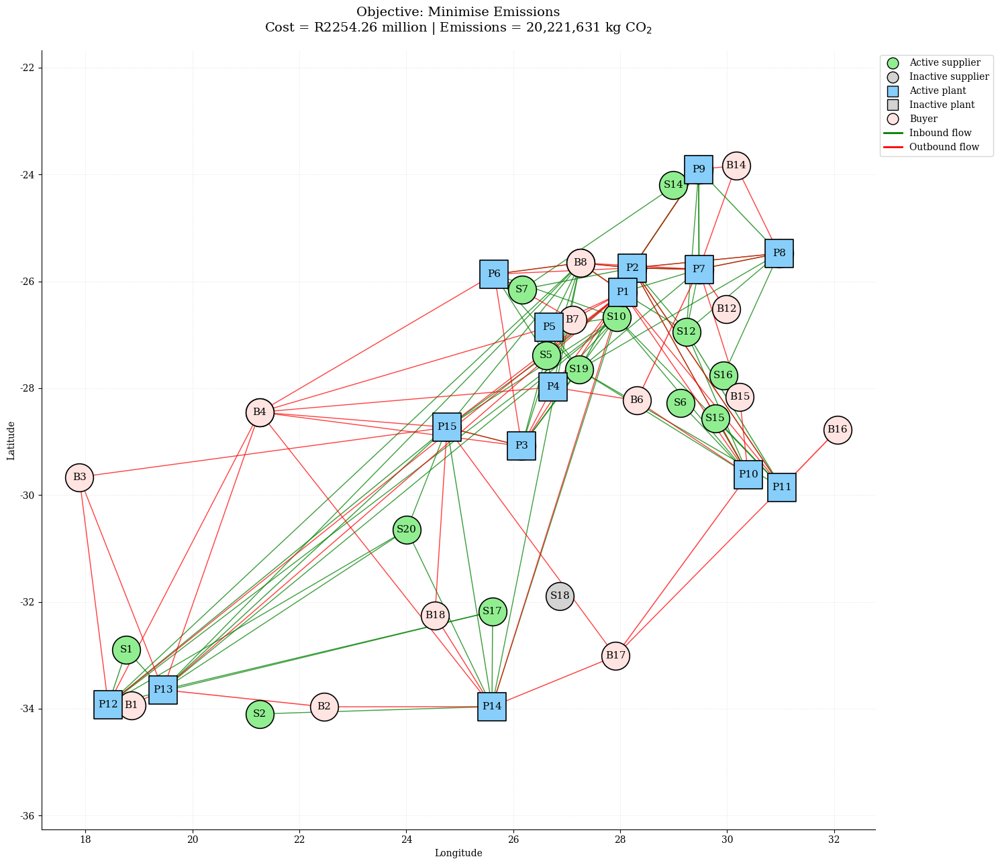

In [20]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E7_3_emissions,
    data_E7_3,
    coord_file="Master_Coordinates.xlsx"
)

## E8. Transport cost variation


In [22]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [23]:
master = Functions.load_master_data("Master_Data.xlsx")

data_E8_0 = Functions.build_experiment_data(
    master,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

### E8.1 – Transport Cost +50%

In [25]:
data_E8_1 = Experiments.vary_transport_cost(data_E8_0, factor=1.50)

In [26]:
# Min-cost

mdl_E8_1_cost, vars_E8_1_cost = Functions.build_model(data_E8_1, objective="cost")

mdl_E8_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E8_1_cost.parameters.timelimit = 900

results_E8_1_cost = Functions.solve_and_extract(mdl_E8_1_cost, vars_E8_1_cost, data_E8_1, log_output=False)

Experiments.experiment_report(
    results_E8_1_cost,
    mdl_E8_1_cost,
    experiment_id="E8.1",
    scenario_name="Transport cost +50% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E8.1
Scenario   : Transport cost +50% – min-cost
Objective  : Min-Cost

Objective value : 2,055,814,506.60
Total cost      : R 2,055,814,506.60
Total emissions : 19,809,859.77 kg CO2
Open plants     : P1, P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,401,460,627.90
inbound_transport_cost        : R 150,778,545.00
production_cost               : R 289,709,081.70
plant_opening_cost            : R 92,168,000.00
outbound_transport_cost       : R 121,698,252.00

--- Emissions breakdown ---
inbound_emissions             : 2,160,156.08 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,585,703.69 kg CO2

--- Production ---
P1 - F1: 7,391.60 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 25,629.00 tonnes
P1 - F4: 8,992.00 tonnes
P1 - F5: 22,612.00 tonnes
P1 - F6: 19,519.50 tonnes
P3 - F3: 11,775.73 tonnes
P3 - F4: 1,610.00 tonnes
P3 - F5: 11,184.00 tonnes
P3 - F6: 11,548.00 tonnes
P4 - F1: 1,

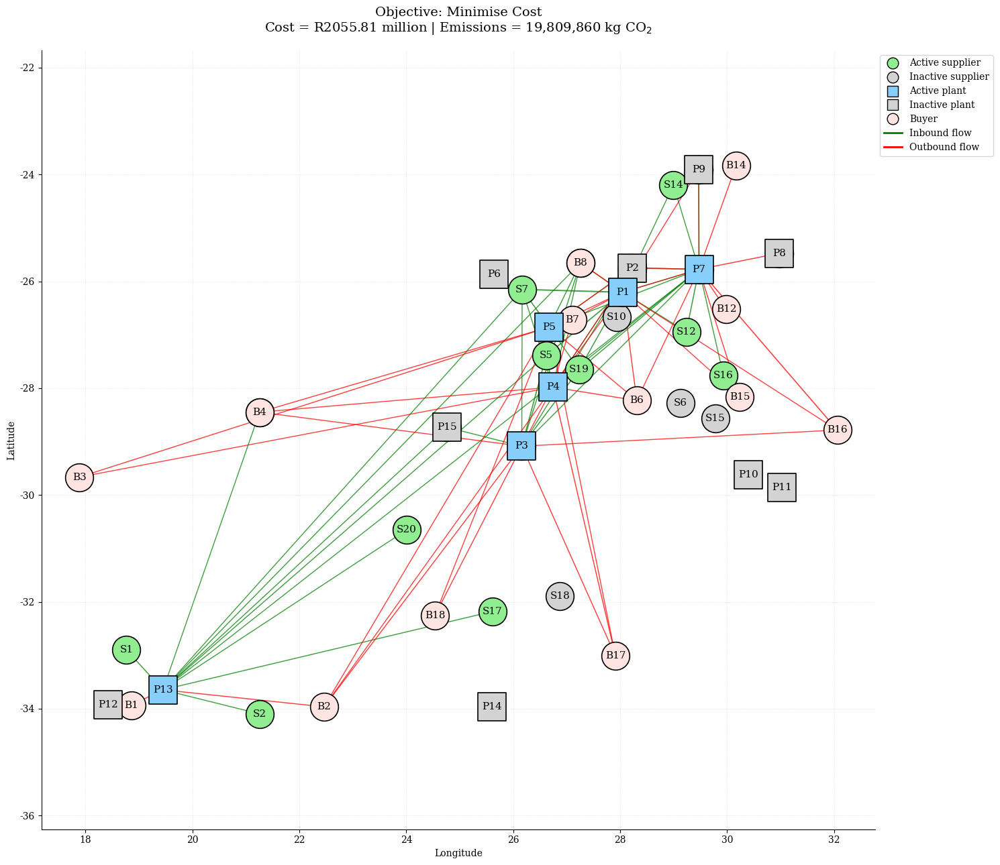

In [27]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E8_1_cost,
    data_E8_1,
    coord_file="Master_Coordinates.xlsx"
)

In [28]:
# Min-emissions

mdl_E8_1_emissions, vars_E8_1_emissions = Functions.build_model(data_E8_1, objective="emissions")

mdl_E8_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E8_1_emissions.parameters.timelimit = 900

results_E8_1_emissions = Functions.solve_and_extract(mdl_E8_1_emissions, vars_E8_1_emissions, data_E8_1, log_output=False)

Experiments.experiment_report(
    results_E8_1_emissions,
    mdl_E8_1_emissions,
    experiment_id="E8.1",
    scenario_name="Transport cost +50% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E8.1
Scenario   : Transport cost +50% – min-emissions
Objective  : Min-Emissions

Objective value : 18,964,156.80
Total cost      : R 2,192,033,697.38
Total emissions : 18,964,156.80 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,653,432.88
inbound_transport_cost        : R 162,391,485.00
production_cost               : R 299,469,673.50
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 77,324,106.00

--- Emissions breakdown ---
inbound_emissions             : 2,263,135.17 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,637,021.63 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 tonnes
P2 

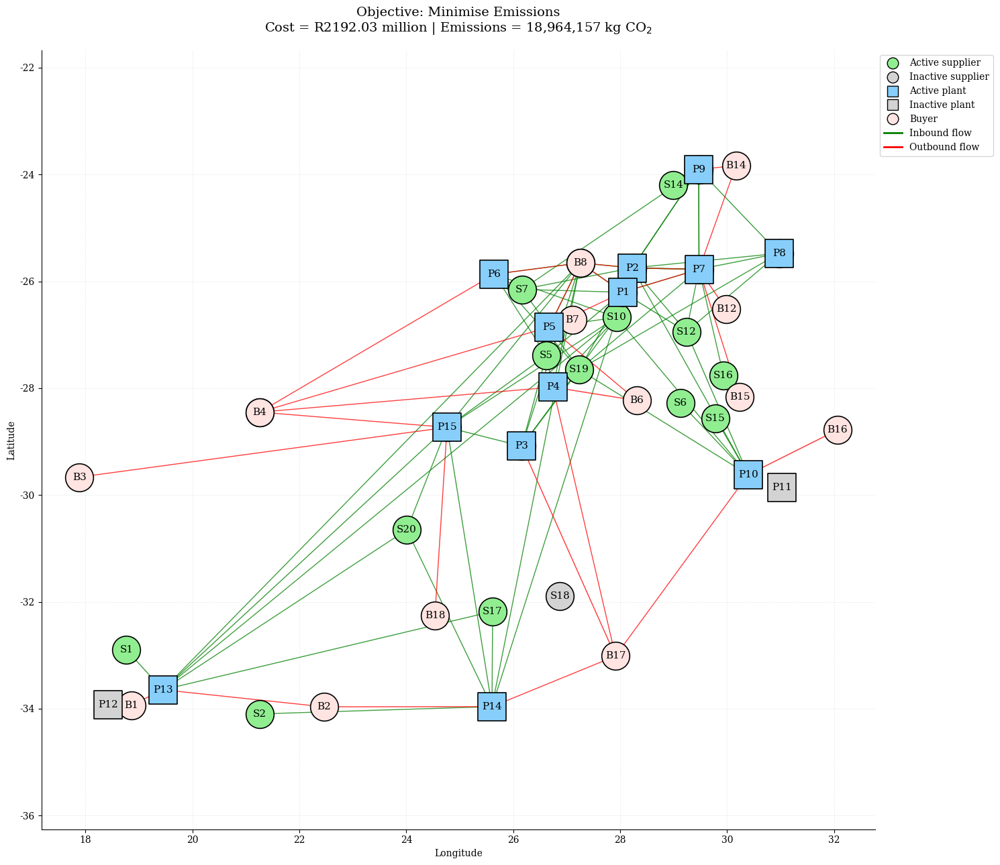

In [29]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E8_1_emissions,
    data_E8_1,
    coord_file="Master_Coordinates.xlsx"
)

### E8.2 – Transport Cost +100%

In [30]:
data_E8_2 = Experiments.vary_transport_cost(data_E8_0, factor=2.00)

In [31]:
# Min-cost

mdl_E8_2_cost, vars_E8_2_cost = Functions.build_model(data_E8_2, objective="cost")

mdl_E8_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E8_2_cost.parameters.timelimit = 900

results_E8_2_cost = Functions.solve_and_extract(mdl_E8_2_cost, vars_E8_2_cost, data_E8_2, log_output=False)

Experiments.experiment_report(
    results_E8_2_cost,
    mdl_E8_2_cost,
    experiment_id="E8.2",
    scenario_name="Transport cost +100% – min-cost",
    objective_name="Min-Cost"
)


EXPERIMENT REPORT
Experiment : E8.2
Scenario   : Transport cost +100% – min-cost
Objective  : Min-Cost

Objective value : 2,145,165,401.21
Total cost      : R 2,145,165,401.21
Total emissions : 19,738,662.37 kg CO2
Open plants     : P1, P3, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,404,512,401.39
inbound_transport_cost        : R 197,576,588.00
production_cost               : R 289,839,891.83
plant_opening_cost            : R 92,168,000.00
outbound_transport_cost       : R 161,068,520.00

--- Emissions breakdown ---
inbound_emissions             : 2,106,169.47 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,568,492.90 kg CO2

--- Production ---
P1 - F1: 7,386.58 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 24,888.00 tonnes
P1 - F4: 8,984.29 tonnes
P1 - F5: 21,628.56 tonnes
P1 - F6: 20,670.00 tonnes
P3 - F3: 11,794.00 tonnes
P3 - F4: 1,625.13 tonnes
P3 - F5: 11,156.00 tonnes
P3 - F6: 11,596.80 tonnes
P4 - F1: 1

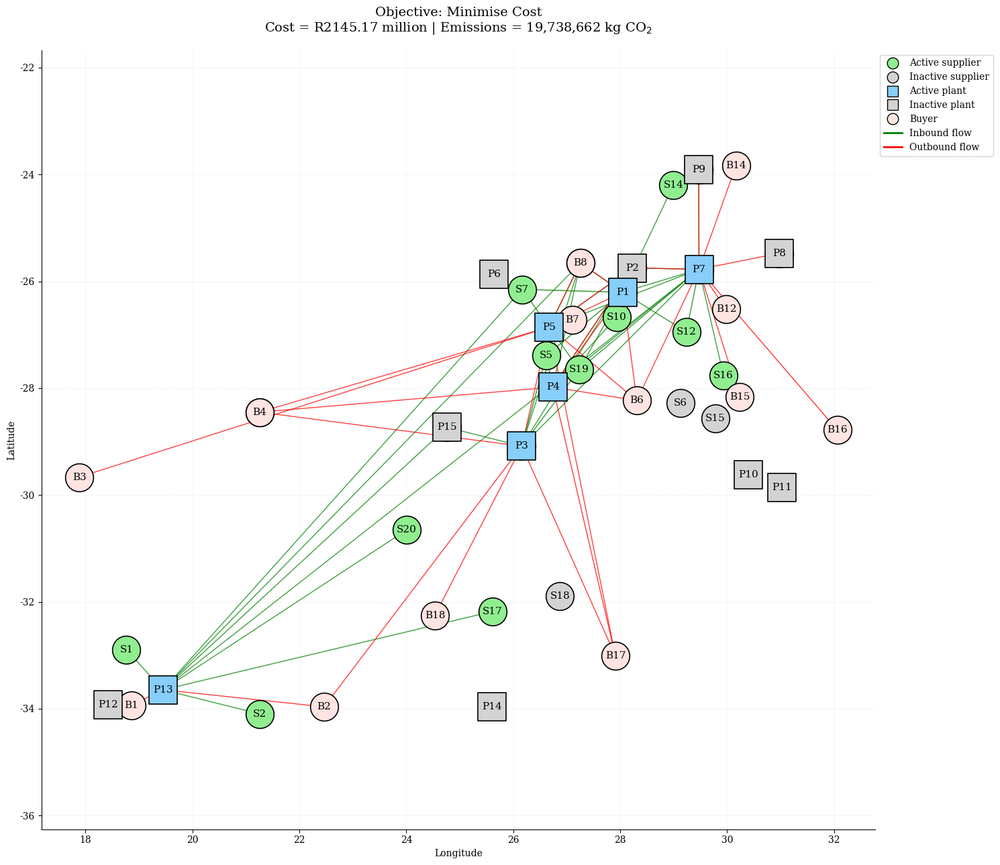

In [32]:
# Min-cost plot

Experiments.plot_exp_solution(
    results_E8_2_cost,
    data_E8_2,
    coord_file="Master_Coordinates.xlsx"
)

In [33]:
# Min-emissions

mdl_E8_2_emissions, vars_E8_2_emissions = Functions.build_model(data_E8_2, objective="emissions")

mdl_E8_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E8_2_emissions.parameters.timelimit = 900

results_E8_2_emissions = Functions.solve_and_extract(mdl_E8_2_emissions, vars_E8_2_emissions, data_E8_2, log_output=False)

Experiments.experiment_report(
    results_E8_2_emissions,
    mdl_E8_2_emissions,
    experiment_id="E8.2",
    scenario_name="Transport cost +100% – min-emissions",
    objective_name="Min-Emissions"
)


EXPERIMENT REPORT
Experiment : E8.2
Scenario   : Transport cost +100% – min-emissions
Objective  : Min-Emissions

Objective value : 18,964,156.80
Total cost      : R 2,271,938,894.38
Total emissions : 18,964,156.80 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,653,432.88
inbound_transport_cost        : R 216,521,980.00
production_cost               : R 299,469,673.50
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 103,098,808.00

--- Emissions breakdown ---
inbound_emissions             : 2,263,135.17 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,637,021.63 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 tonnes
P

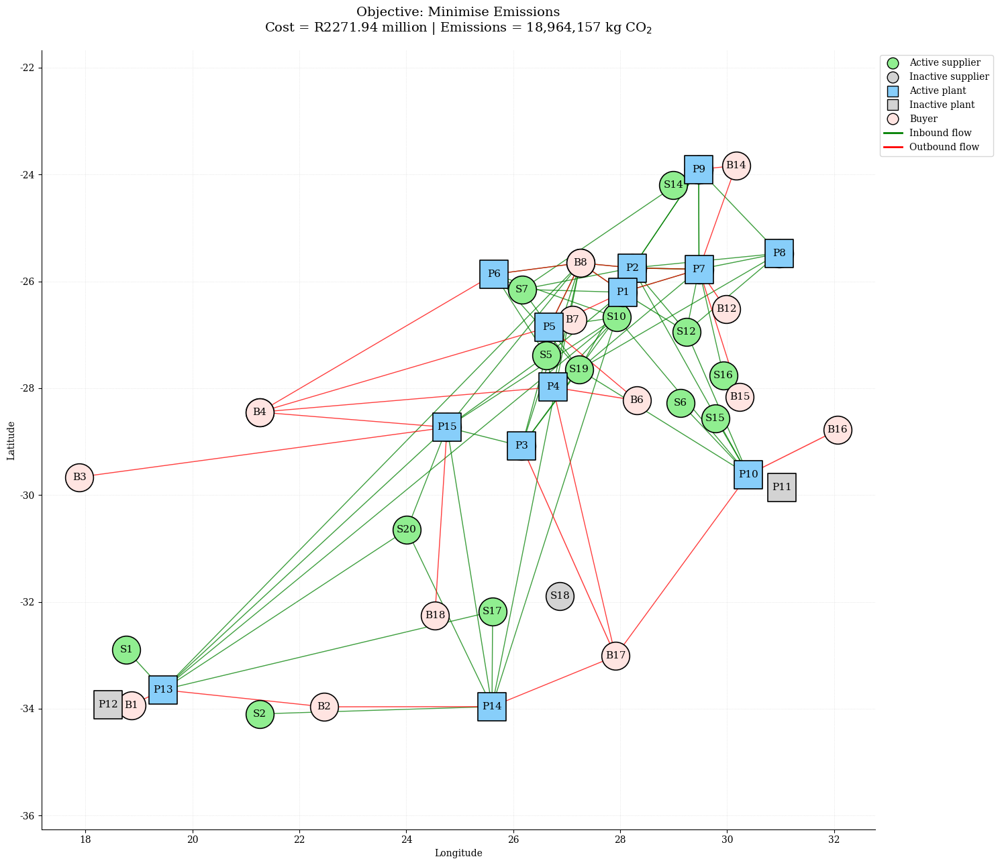

In [34]:
# Min-emissions plot

Experiments.plot_exp_solution(
    results_E8_2_emissions,
    data_E8_2,
    coord_file="Master_Coordinates.xlsx"
)

## E9. Transport emission-factor variation


In [37]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [40]:
master = Functions.load_master_data("Master_Data.xlsx")

data_E9_0 = Functions.build_experiment_data(
    master,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

### E9.1 – Transport emission factors ×0.50

In [41]:
data_E9_1 = Experiments.vary_transport_emission_factor(data_E9_0, 0.50)


EXPERIMENT REPORT
Experiment : E9.1
Scenario   : Transport emission factors ×0.50 – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 17,619,914.57 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 1,133,276.02 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,422,638.55 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F

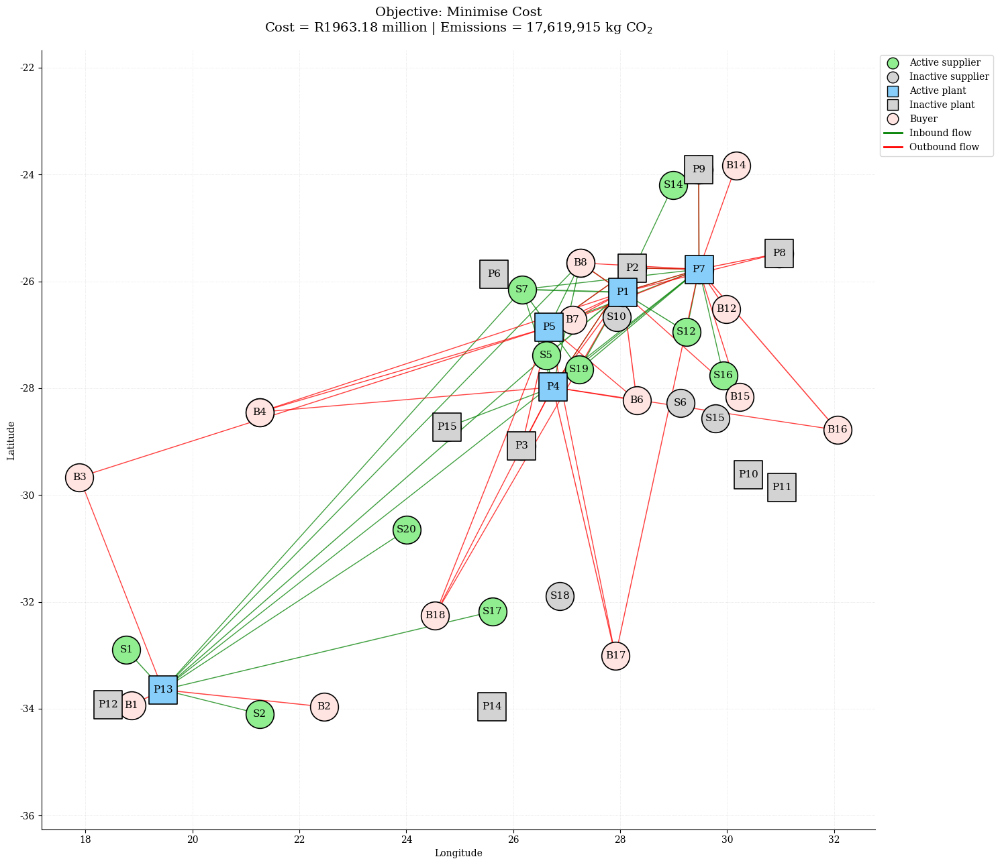


EXPERIMENT REPORT
Experiment : E9.1
Scenario   : Transport emission factors ×0.50 – min-emissions
Objective  : Min-Emissions

Objective value : 17,022,322.86
Total cost      : R 2,112,847,103.67
Total emissions : 17,022,322.86 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,454,006,015.90
inbound_transport_cost        : R 108,770,258.00
production_cost               : R 299,480,185.76
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,395,644.00

--- Emissions breakdown ---
inbound_emissions             : 1,139,535.70 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 818,787.16 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,470.27 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,918.00 tonnes
P2 - F3: 11,410.00

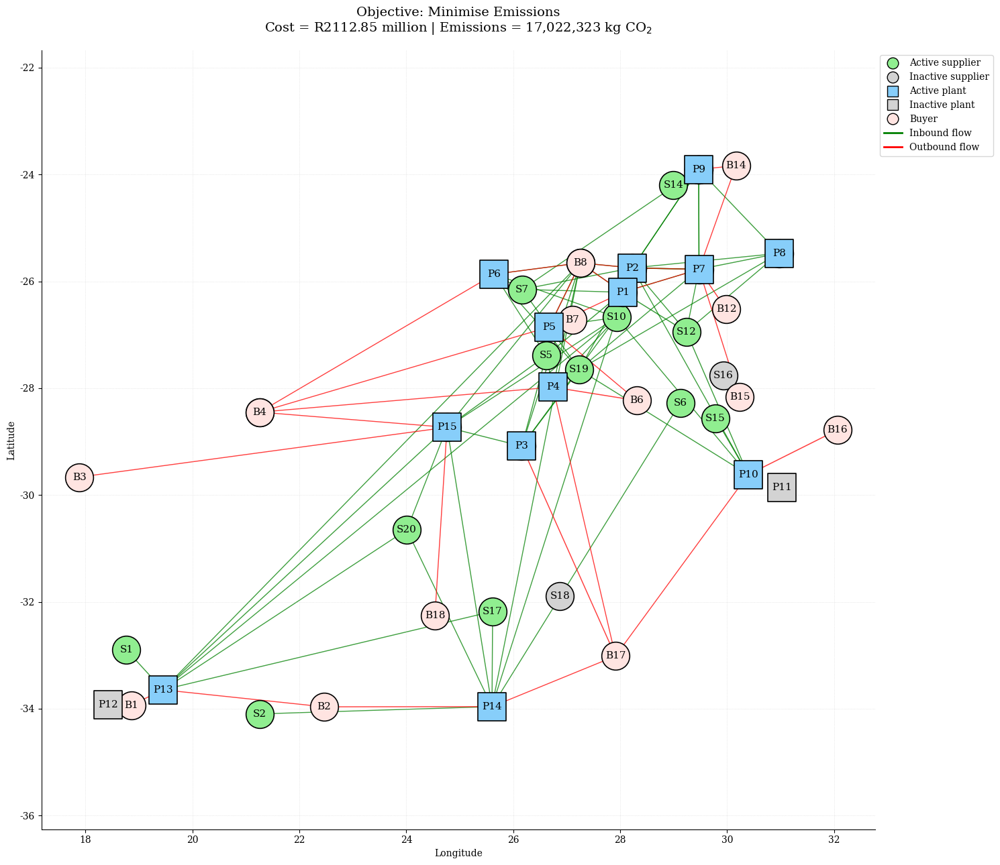

In [42]:
# Min-cost

mdl_E9_1_cost, vars_E9_1_cost = Functions.build_model(data_E9_1, objective="cost")

mdl_E9_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E9_1_cost.parameters.timelimit = 900

results_E9_1_cost = Functions.solve_and_extract(
    mdl_E9_1_cost,
    vars_E9_1_cost,
    data_E9_1,
    log_output=False
)

Experiments.experiment_report(
    results_E9_1_cost,
    mdl_E9_1_cost,
    experiment_id="E9.1",
    scenario_name="Transport emission factors ×0.50 – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E9_1_cost,
    data_E9_1
)


# Min-emissions

mdl_E9_1_emissions, vars_E9_1_emissions = Functions.build_model(data_E9_1, objective="emissions")

mdl_E9_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E9_1_emissions.parameters.timelimit = 900

results_E9_1_emissions = Functions.solve_and_extract(
    mdl_E9_1_emissions,
    vars_E9_1_emissions,
    data_E9_1,
    log_output=False
)

Experiments.experiment_report(
    results_E9_1_emissions,
    mdl_E9_1_emissions,
    experiment_id="E9.1",
    scenario_name="Transport emission factors ×0.50 – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E9_1_emissions,
    data_E9_1
)

### E9.2 – Transport emission factors ×1.50

In [43]:
data_E9_2 = Experiments.vary_transport_emission_factor(data_E9_0, 1.50)


EXPERIMENT REPORT
Experiment : E9.2
Scenario   : Transport emission factors ×1.50 – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 22,731,743.71 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 3,399,828.07 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 4,267,915.64 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F

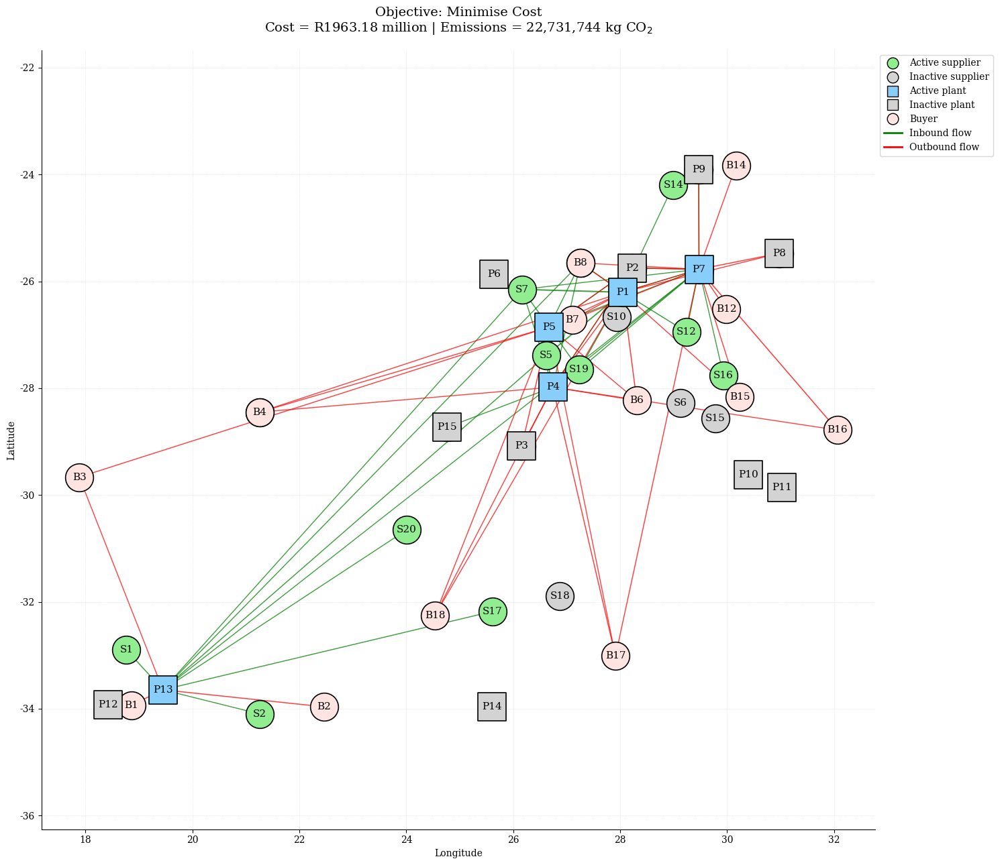


EXPERIMENT REPORT
Experiment : E9.2
Scenario   : Transport emission factors ×1.50 – min-emissions
Objective  : Min-Emissions

Objective value : 20,914,235.21
Total cost      : R 2,112,108,164.37
Total emissions : 20,914,235.21 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,653,432.87
inbound_transport_cost        : R 108,240,654.00
production_cost               : R 299,469,673.50
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,549,404.00

--- Emissions breakdown ---
inbound_emissions             : 3,394,702.75 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,455,532.45 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.

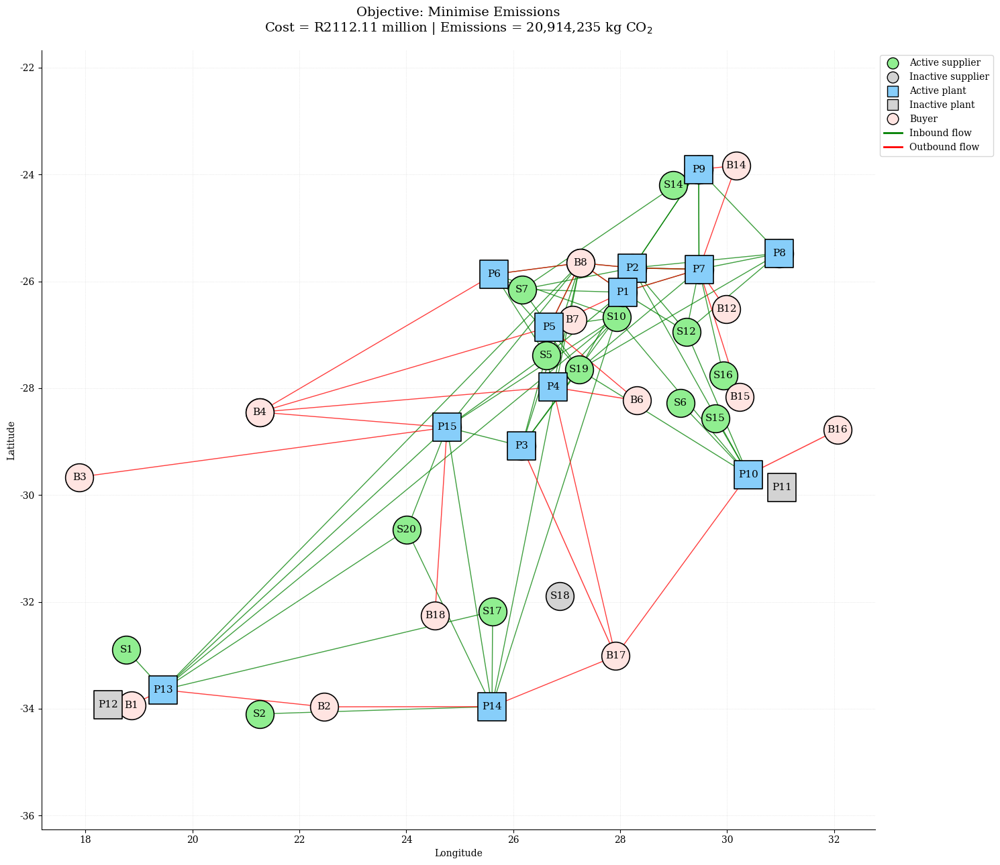

In [44]:
# Min-cost

mdl_E9_2_cost, vars_E9_2_cost = Functions.build_model(data_E9_2, objective="cost")

mdl_E9_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E9_2_cost.parameters.timelimit = 900

results_E9_2_cost = Functions.solve_and_extract(
    mdl_E9_2_cost,
    vars_E9_2_cost,
    data_E9_2,
    log_output=False
)

Experiments.experiment_report(
    results_E9_2_cost,
    mdl_E9_2_cost,
    experiment_id="E9.2",
    scenario_name="Transport emission factors ×1.50 – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E9_2_cost,
    data_E9_2
)


# Min-emissions

mdl_E9_2_emissions, vars_E9_2_emissions = Functions.build_model(data_E9_2, objective="emissions")

mdl_E9_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E9_2_emissions.parameters.timelimit = 900

results_E9_2_emissions = Functions.solve_and_extract(
    mdl_E9_2_emissions,
    vars_E9_2_emissions,
    data_E9_2,
    log_output=False
)

Experiments.experiment_report(
    results_E9_2_emissions,
    mdl_E9_2_emissions,
    experiment_id="E9.2",
    scenario_name="Transport emission factors ×1.50 – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E9_2_emissions,
    data_E9_2
)


### E9.3 – Transport emission factors ×2.00

In [45]:
data_E9_3 = Experiments.vary_transport_emission_factor(data_E9_0, 2.00)


EXPERIMENT REPORT
Experiment : E9.3
Scenario   : Transport emission factors ×2.00 – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 25,287,658.28 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 4,533,104.10 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 5,690,554.19 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F

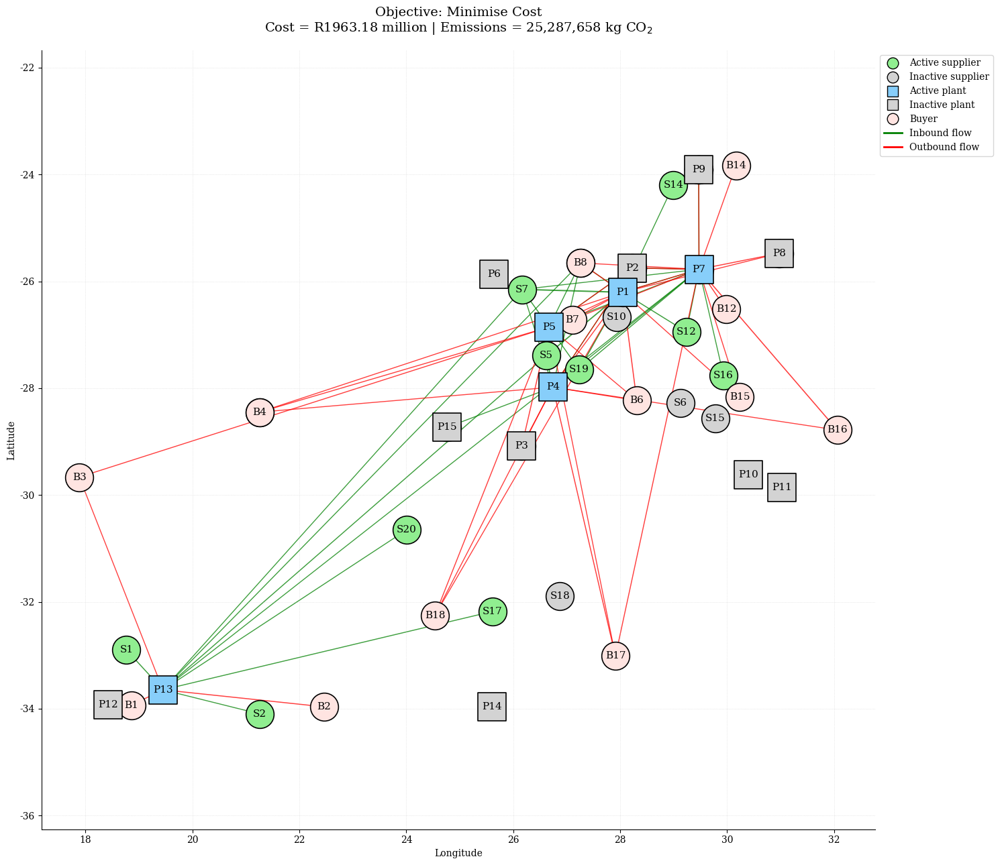


EXPERIMENT REPORT
Experiment : E9.3
Scenario   : Transport emission factors ×2.00 – min-emissions
Objective  : Min-Emissions

Objective value : 22,863,816.00
Total cost      : R 2,112,452,866.03
Total emissions : 22,863,816.00 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,986,968.83
inbound_transport_cost        : R 108,232,036.00
production_cost               : R 299,469,307.19
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,569,554.00

--- Emissions breakdown ---
inbound_emissions             : 4,525,770.97 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 3,274,045.03 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 7,989.82 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,835.19 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.

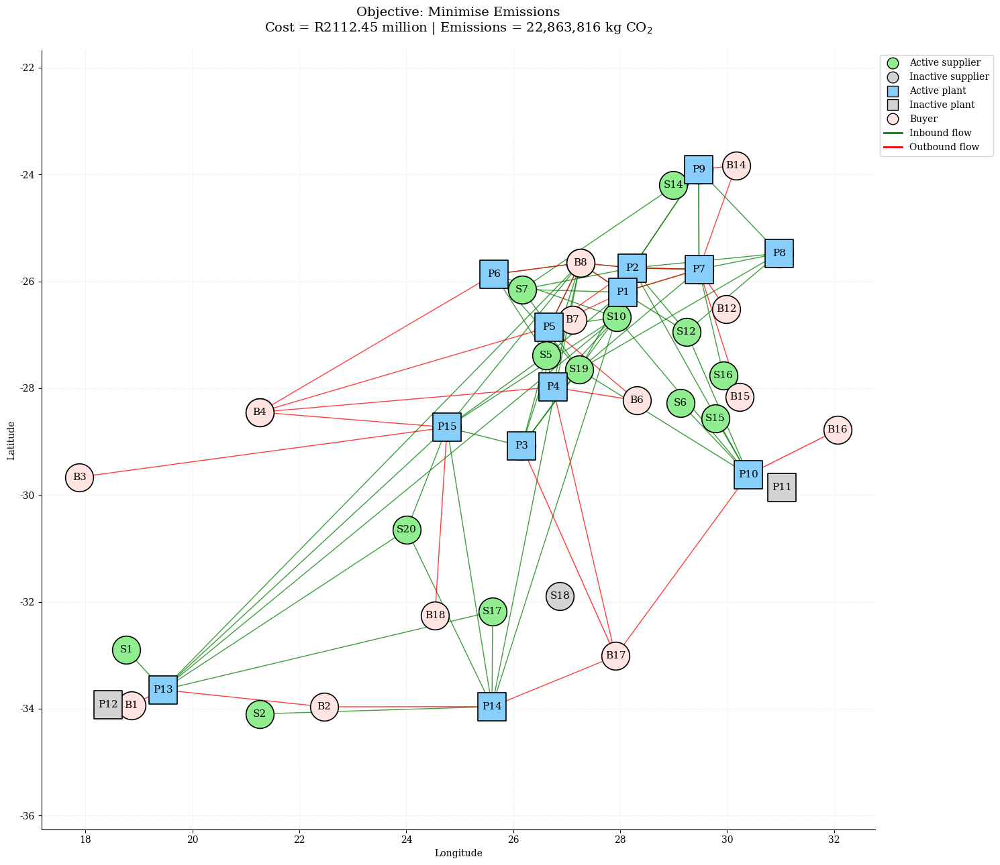

In [46]:
# Min-cost

mdl_E9_3_cost, vars_E9_3_cost = Functions.build_model(data_E9_3, objective="cost")

mdl_E9_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E9_3_cost.parameters.timelimit = 900

results_E9_3_cost = Functions.solve_and_extract(
    mdl_E9_3_cost,
    vars_E9_3_cost,
    data_E9_3,
    log_output=False
)

Experiments.experiment_report(
    results_E9_3_cost,
    mdl_E9_3_cost,
    experiment_id="E9.3",
    scenario_name="Transport emission factors ×2.00 – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E9_3_cost,
    data_E9_3
)


# Min-emissions

mdl_E9_3_emissions, vars_E9_3_emissions = Functions.build_model(data_E9_3, objective="emissions")

mdl_E9_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E9_3_emissions.parameters.timelimit = 900

results_E9_3_emissions = Functions.solve_and_extract(
    mdl_E9_3_emissions,
    vars_E9_3_emissions,
    data_E9_3,
    log_output=False
)

Experiments.experiment_report(
    results_E9_3_emissions,
    mdl_E9_3_emissions,
    experiment_id="E9.3",
    scenario_name="Transport emission factors ×2.00 – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E9_3_emissions,
    data_E9_3
)

## E10. Plant emission-factor variation


In [32]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [33]:
master = Functions.load_master_data("Master_Data.xlsx")

data_E9_0 = Functions.build_experiment_data(
    master,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

### E10.1 – Plant emission factors ×0.5

In [28]:
data_E10_1 = Experiments.vary_plant_emissions(data_E9_0, 0.5)


EXPERIMENT REPORT
Experiment : E10.1
Scenario   : Plant emission factors ×0.5 – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 12,643,829.14 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 2,266,552.05 kg CO2
plant_emissions               : 7,532,000.00 kg CO2
outbound_emissions            : 2,845,277.09 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F5: 5,

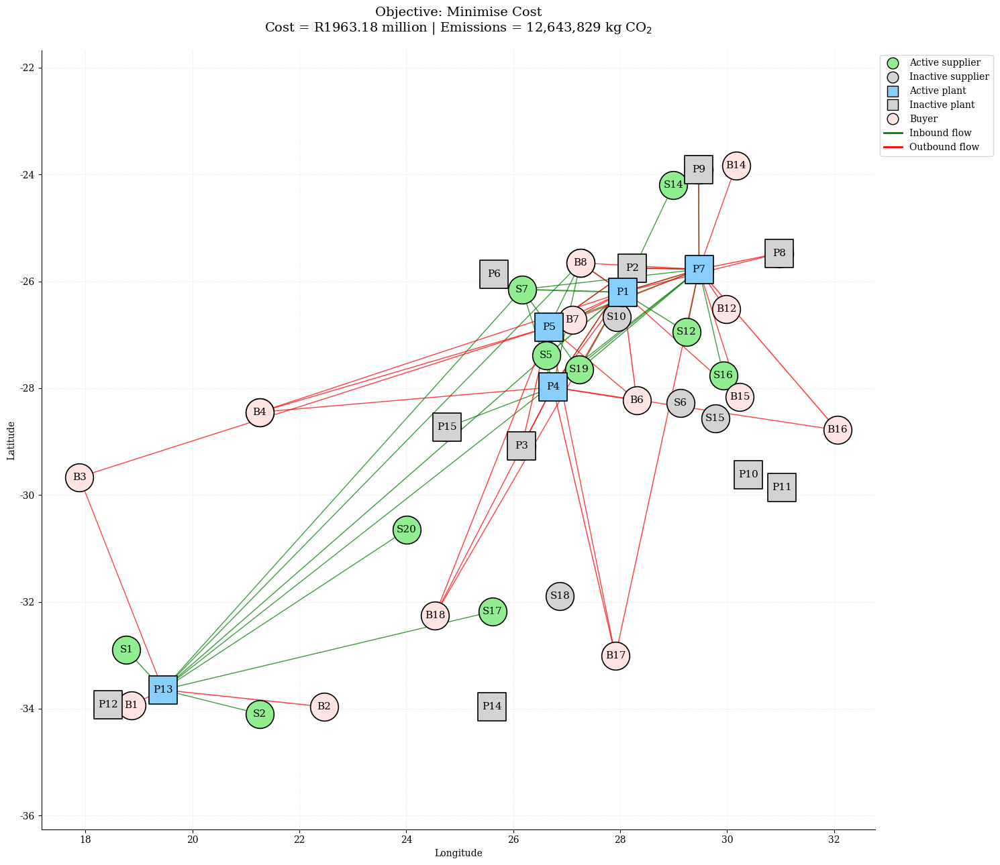


EXPERIMENT REPORT
Experiment : E10.1
Scenario   : Plant emission factors ×0.5 – min-emissions
Objective  : Min-Emissions

Objective value : 11,431,908.00
Total cost      : R 2,112,452,866.03
Total emissions : 11,431,908.00 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,453,986,968.83
inbound_transport_cost        : R 108,232,036.00
production_cost               : R 299,469,307.19
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,569,554.00

--- Emissions breakdown ---
inbound_emissions             : 2,262,885.48 kg CO2
plant_emissions               : 7,532,000.00 kg CO2
outbound_emissions            : 1,637,022.52 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 7,989.82 tonnes
P1 - F3: 6,454.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,835.19 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 to

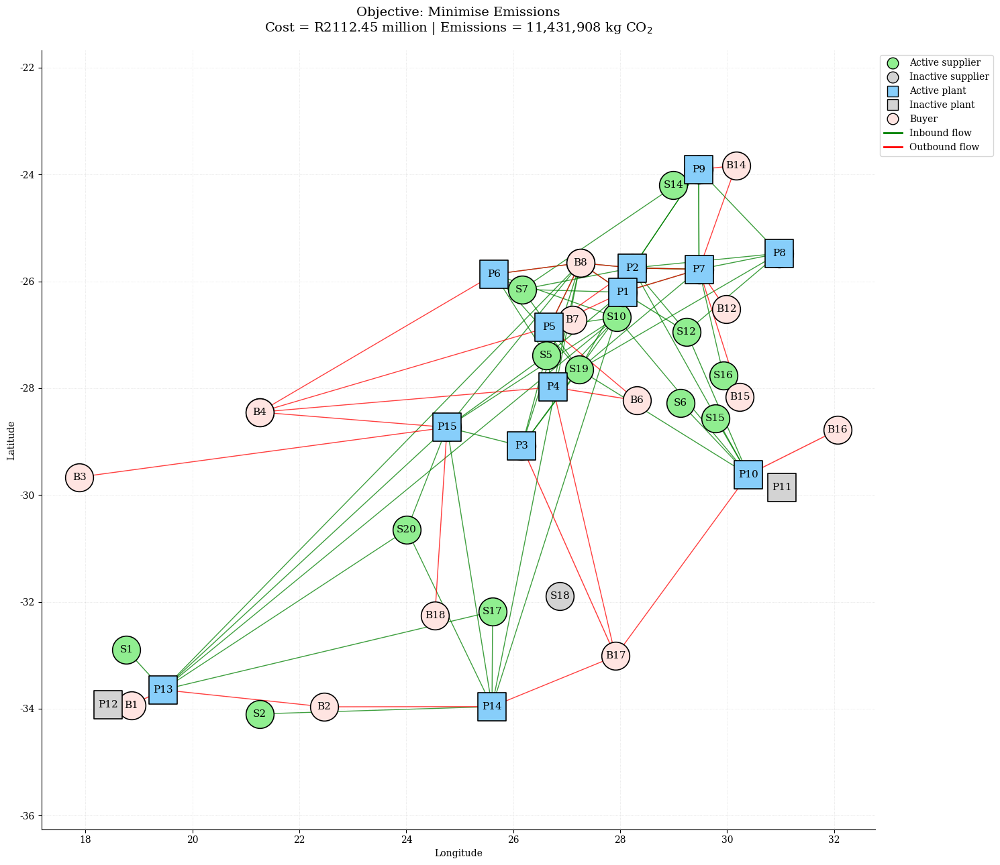

In [29]:

# Min-cost

mdl_E10_1_cost, vars_E10_1_cost = Functions.build_model(data_E10_1, objective="cost")

mdl_E10_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E10_1_cost.parameters.timelimit = 900

results_E10_1_cost = Functions.solve_and_extract(
    mdl_E10_1_cost,
    vars_E10_1_cost,
    data_E10_1,
    log_output=False
)

Experiments.experiment_report(
    results_E10_1_cost,
    mdl_E10_1_cost,
    experiment_id="E10.1",
    scenario_name="Plant emission factors ×0.5 – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E10_1_cost,
    data_E10_1
)

# Min-emissions

mdl_E10_1_emissions, vars_E10_1_emissions = Functions.build_model(
    data_E10_1,
    objective="emissions"
)

mdl_E10_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E10_1_emissions.parameters.timelimit = 900

results_E10_1_emissions = Functions.solve_and_extract(
    mdl_E10_1_emissions,
    vars_E10_1_emissions,
    data_E10_1,
    log_output=False
)

Experiments.experiment_report(
    results_E10_1_emissions,
    mdl_E10_1_emissions,
    experiment_id="E10.1",
    scenario_name="Plant emission factors ×0.5 – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E10_1_emissions,
    data_E10_1
)

### E10.2 – Plant emission factors ×1.5

In [34]:
data_E10_2 = Experiments.vary_plant_emissions(data_E9_0, 1.5)


EXPERIMENT REPORT
Experiment : E10.2
Scenario   : Plant emission factors ×1.5 – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 27,707,829.14 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 2,266,552.05 kg CO2
plant_emissions               : 22,596,000.00 kg CO2
outbound_emissions            : 2,845,277.09 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F5: 5

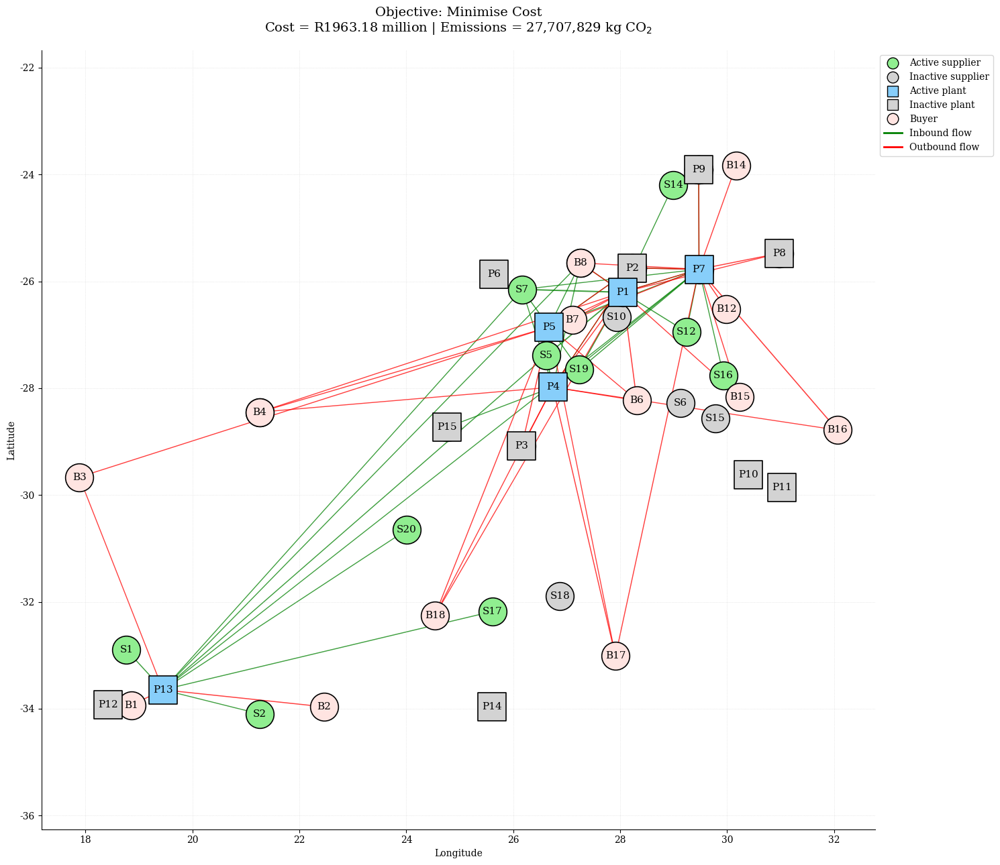


EXPERIMENT REPORT
Experiment : E10.2
Scenario   : Plant emission factors ×1.5 – min-emissions
Objective  : Min-Emissions

Objective value : 26,512,645.72
Total cost      : R 2,112,847,103.67
Total emissions : 26,512,645.72 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,454,006,015.90
inbound_transport_cost        : R 108,770,258.00
production_cost               : R 299,480,185.76
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,395,644.00

--- Emissions breakdown ---
inbound_emissions             : 2,279,071.39 kg CO2
plant_emissions               : 22,596,000.00 kg CO2
outbound_emissions            : 1,637,574.32 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,470.27 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,918.00 tonnes
P2 - F3: 11,410.00 t

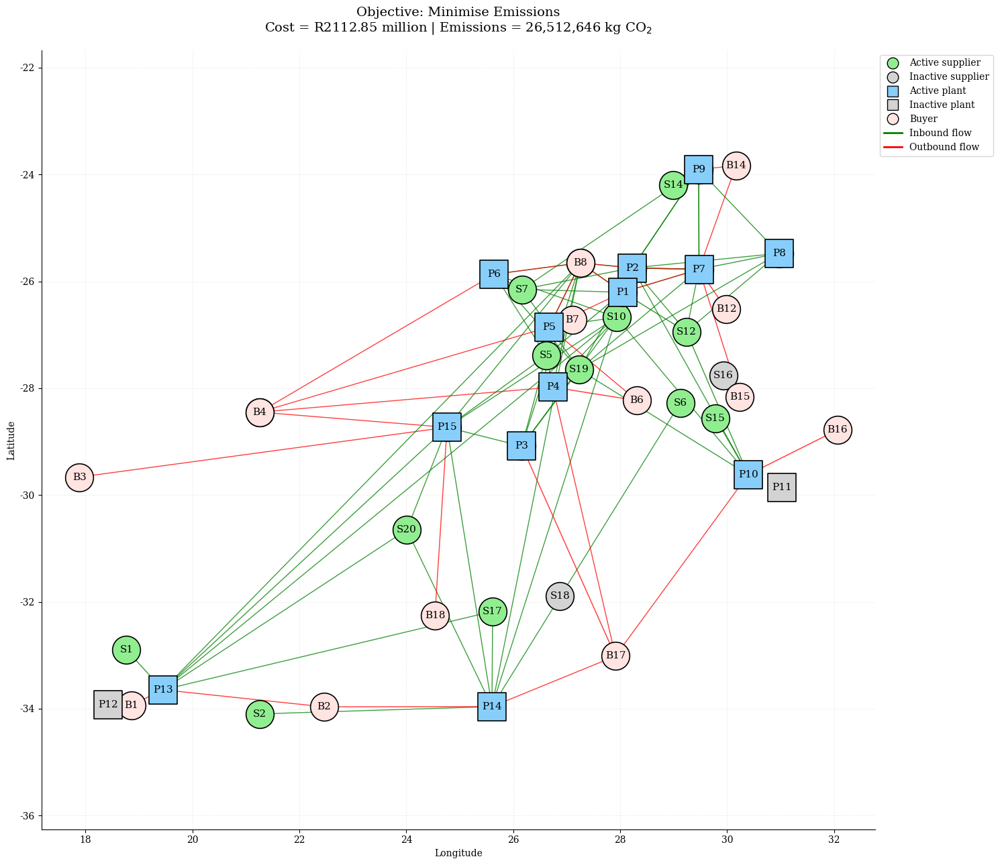

In [35]:
# Min-cost

mdl_E10_2_cost, vars_E10_2_cost = Functions.build_model(data_E10_2, objective="cost")

mdl_E10_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E10_2_cost.parameters.timelimit = 900

results_E10_2_cost = Functions.solve_and_extract(
    mdl_E10_2_cost,
    vars_E10_2_cost,
    data_E10_2,
    log_output=False
)

Experiments.experiment_report(
    results_E10_2_cost,
    mdl_E10_2_cost,
    experiment_id="E10.2",
    scenario_name="Plant emission factors ×1.5 – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E10_2_cost,
    data_E10_2
)

# Min-emissions

mdl_E10_2_emissions, vars_E10_2_emissions = Functions.build_model(
    data_E10_2,
    objective="emissions"
)

mdl_E10_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E10_2_emissions.parameters.timelimit = 900

results_E10_2_emissions = Functions.solve_and_extract(
    mdl_E10_2_emissions,
    vars_E10_2_emissions,
    data_E10_2,
    log_output=False
)

Experiments.experiment_report(
    results_E10_2_emissions,
    mdl_E10_2_emissions,
    experiment_id="E10.2",
    scenario_name="Plant emission factors ×1.5 – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E10_2_emissions,
    data_E10_2
)

### E10.3 – Plant emission factors ×2.0

In [36]:
data_E10_3 = Experiments.vary_plant_emissions(data_E9_0, 2.0)


EXPERIMENT REPORT
Experiment : E10.3
Scenario   : Plant emission factors ×2.0 – min-cost
Objective  : Min-Cost

Objective value : 1,963,184,038.00
Total cost      : R 1,963,184,038.00
Total emissions : 35,239,829.14 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,400,684,417.50
inbound_transport_cost        : R 103,746,170.00
production_cost               : R 288,164,252.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 89,249,198.00

--- Emissions breakdown ---
inbound_emissions             : 2,266,552.05 kg CO2
plant_emissions               : 30,128,000.00 kg CO2
outbound_emissions            : 2,845,277.09 kg CO2

--- Production ---
P1 - F1: 7,398.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,581.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,842.00 tonnes
P4 - F1: 1,050.00 tonnes
P4 - F2: 1,370.00 tonnes
P4 - F3: 5,787.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F5: 5

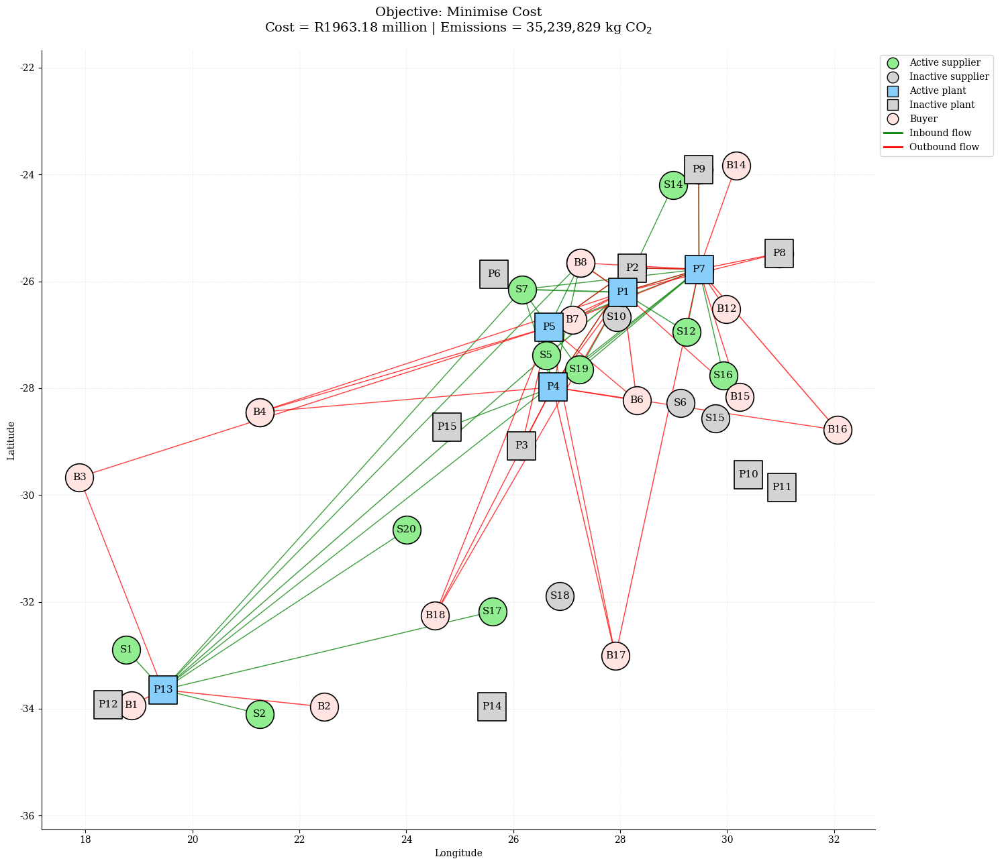


EXPERIMENT REPORT
Experiment : E10.3
Scenario   : Plant emission factors ×2.0 – min-emissions
Objective  : Min-Emissions

Objective value : 34,044,645.72
Total cost      : R 2,112,847,103.67
Total emissions : 34,044,645.72 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,454,006,015.90
inbound_transport_cost        : R 108,770,258.00
production_cost               : R 299,480,185.76
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,395,644.00

--- Emissions breakdown ---
inbound_emissions             : 2,279,071.39 kg CO2
plant_emissions               : 30,128,000.00 kg CO2
outbound_emissions            : 1,637,574.32 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,470.27 tonnes
P1 - F4: 6,170.00 tonnes
P1 - F5: 7,834.00 tonnes
P1 - F6: 9,414.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,918.00 tonnes
P2 - F3: 11,410.00 t

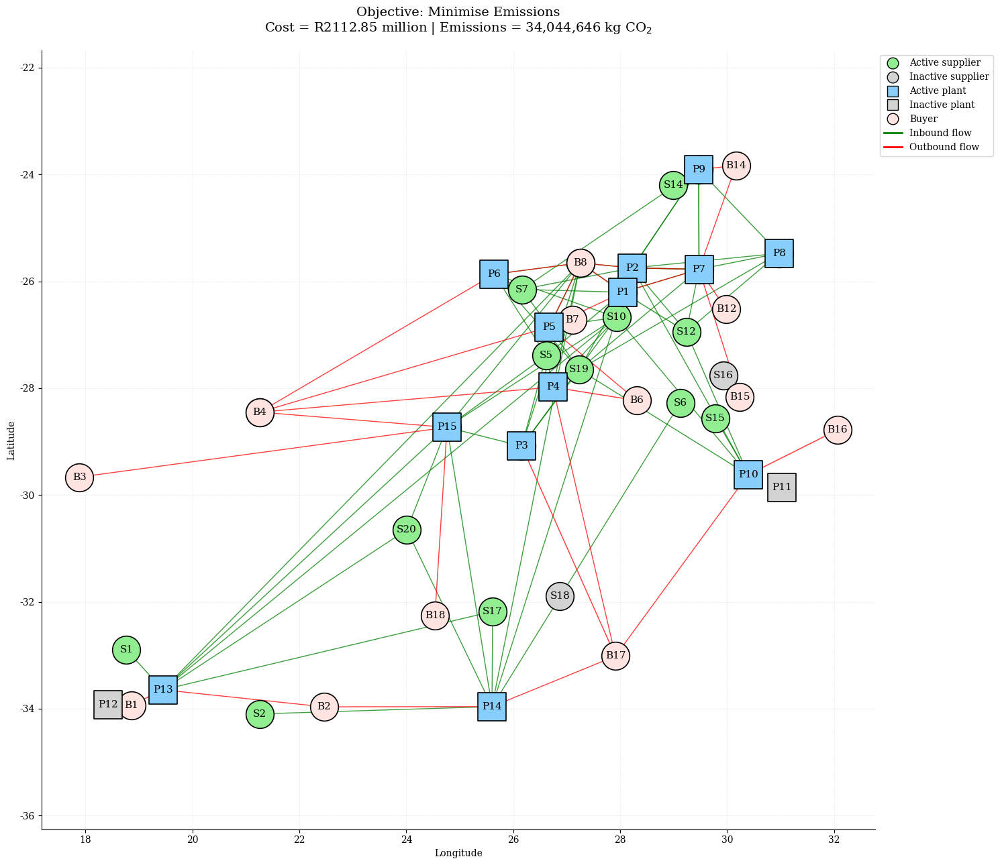

In [37]:

# Min-cost

mdl_E10_3_cost, vars_E10_3_cost = Functions.build_model(data_E10_3, objective="cost")

mdl_E10_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E10_3_cost.parameters.timelimit = 900

results_E10_3_cost = Functions.solve_and_extract(
    mdl_E10_3_cost,
    vars_E10_3_cost,
    data_E10_3,
    log_output=False
)

Experiments.experiment_report(
    results_E10_3_cost,
    mdl_E10_3_cost,
    experiment_id="E10.3",
    scenario_name="Plant emission factors ×2.0 – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E10_3_cost,
    data_E10_3
)

# Min-emissions

mdl_E10_3_emissions, vars_E10_3_emissions = Functions.build_model(
    data_E10_3,
    objective="emissions"
)

mdl_E10_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E10_3_emissions.parameters.timelimit = 900

results_E10_3_emissions = Functions.solve_and_extract(
    mdl_E10_3_emissions,
    vars_E10_3_emissions,
    data_E10_3,
    log_output=False
)

Experiments.experiment_report(
    results_E10_3_emissions,
    mdl_E10_3_emissions,
    experiment_id="E10.3",
    scenario_name="Plant emission factors ×2.0 – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E10_3_emissions,
    data_E10_3
)

## E11. Suppleir Capacity Restriction


In [43]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [44]:
master = Functions.load_master_data("Master_Data.xlsx")

data_E11_0 = Functions.build_experiment_data(
    master,
    plants=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15"],
    suppliers=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20"],
    buyers=["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9", "B10", "B11", "B12", "B13", "B14", "B15", "B16", "B17", "B18"],
    materials=["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10"],
    feeds=["F1", "F2", "F3", "F4", "F5", "F6"],
    trucks=["T1", "T2", "T3", "T4", "T5"]
)

### E11.1 Reduced supplier capacity - Mpumalanga availability 75%

In [45]:
data_E11_1 = Experiments.vary_supplier_capacity(data_E11_0, suppliers=["S11", "S12"], factor=0.75)


EXPERIMENT REPORT
Experiment : E11.1
Scenario   : Mpumalanga availability 75% – min-cost
Objective  : Min-Cost

Objective value : 1,971,223,106.23
Total cost      : R 1,971,223,106.23
Total emissions : 20,303,724.70 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,402,501,343.67
inbound_transport_cost        : R 112,133,570.00
production_cost               : R 288,537,582.57
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 86,710,610.00

--- Emissions breakdown ---
inbound_emissions             : 2,476,429.39 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,763,295.31 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,600.00 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,994.87 tonnes
P4 - F1: 1,042.00 tonnes
P4 - F2: 1,400.00 tonnes
P4 - F3: 5,800.00 tonnes
P4 - F4: 1,568.00 tonnes
P4 - F5: 5

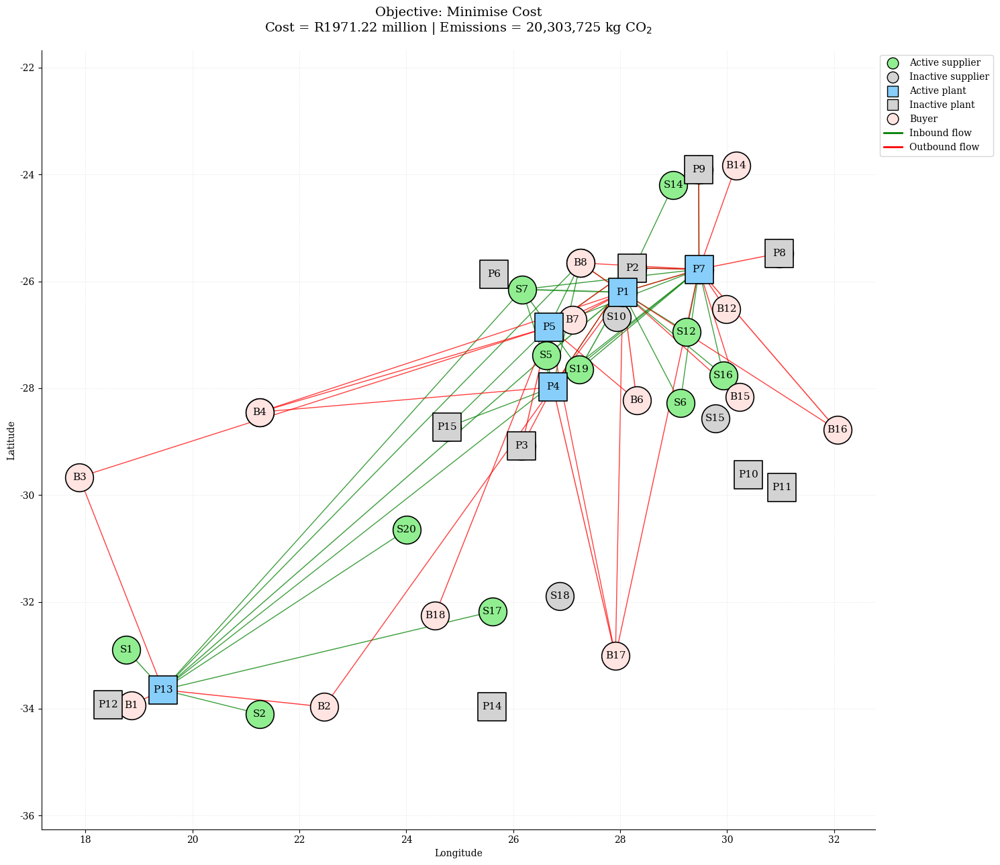

In [46]:
# Min-cost

mdl_E11_1_cost, vars_E11_1_cost = Functions.build_model(
    data_E11_1,
    objective="cost"
)

mdl_E11_1_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E11_1_cost.parameters.timelimit = 900

results_E11_1_cost = Functions.solve_and_extract(
    mdl_E11_1_cost,
    vars_E11_1_cost,
    data_E11_1,
    log_output=False
)

Experiments.experiment_report(
    results_E11_1_cost,
    mdl_E11_1_cost,
    experiment_id="E11.1",
    scenario_name="Mpumalanga availability 75% – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E11_1_cost,
    data_E11_1,
    coord_file="Master_Coordinates.xlsx"
)


EXPERIMENT REPORT
Experiment : E11.1
Scenario   : Mpumalanga availability 75% – min-emissions
Objective  : Min-Emissions

Objective value : 18,999,385.82
Total cost      : R 2,116,156,759.83
Total emissions : 18,999,385.82 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,455,961,629.67
inbound_transport_cost        : R 109,559,952.00
production_cost               : R 299,712,586.17
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 51,727,592.00

--- Emissions breakdown ---
inbound_emissions             : 2,292,649.73 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,642,736.09 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 6,118.00 tonnes
P1 - F4: 6,125.00 tonnes
P1 - F5: 7,853.83 tonnes
P1 - F6: 7,796.33 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 t

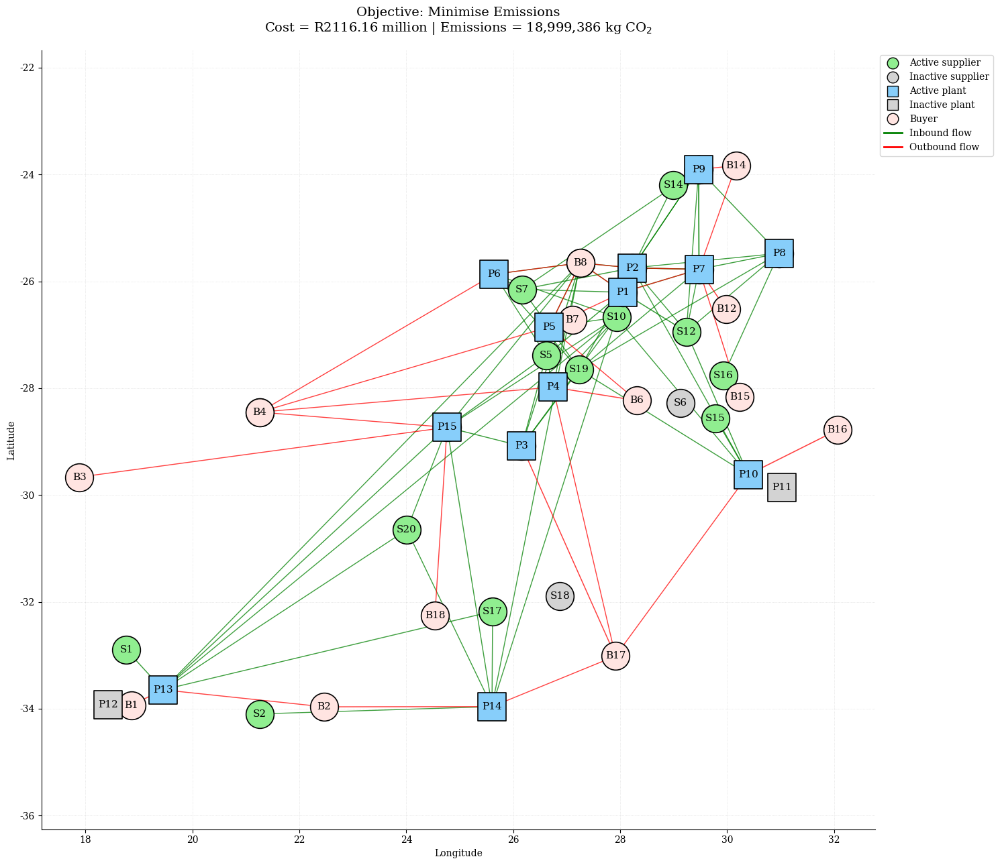

In [47]:
# Min-emissions

mdl_E11_1_emissions, vars_E11_1_emissions = Functions.build_model(
    data_E11_1,
    objective="emissions"
)

mdl_E11_1_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E11_1_emissions.parameters.timelimit = 900

results_E11_1_emissions = Functions.solve_and_extract(
    mdl_E11_1_emissions,
    vars_E11_1_emissions,
    data_E11_1,
    log_output=False
)

Experiments.experiment_report(
    results_E11_1_emissions,
    mdl_E11_1_emissions,
    experiment_id="E11.1",
    scenario_name="Mpumalanga availability 75% – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E11_1_emissions,
    data_E11_1,
    coord_file="Master_Coordinates.xlsx"
)

### E11.2 Reduced supplier capacity - Mpumalanga availability 50%

In [48]:
data_E11_2 = Experiments.vary_supplier_capacity(
    data_E11_0,
    suppliers=["S11", "S12"],
    factor=0.50
)


EXPERIMENT REPORT
Experiment : E11.2
Scenario   : Mpumalanga availability 50% – min-cost
Objective  : Min-Cost

Objective value : 1,981,494,502.00
Total cost      : R 1,981,494,502.00
Total emissions : 20,431,810.63 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,407,732,482.50
inbound_transport_cost        : R 117,175,210.00
production_cost               : R 288,544,891.50
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 86,701,918.00

--- Emissions breakdown ---
inbound_emissions             : 2,603,477.98 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,764,332.65 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,592.50 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 32,000.00 tonnes
P4 - F1: 1,046.50 tonnes
P4 - F2: 1,386.50 tonnes
P4 - F3: 5,800.00 tonnes
P4 - F4: 1,596.00 tonnes
P4 - F5: 5

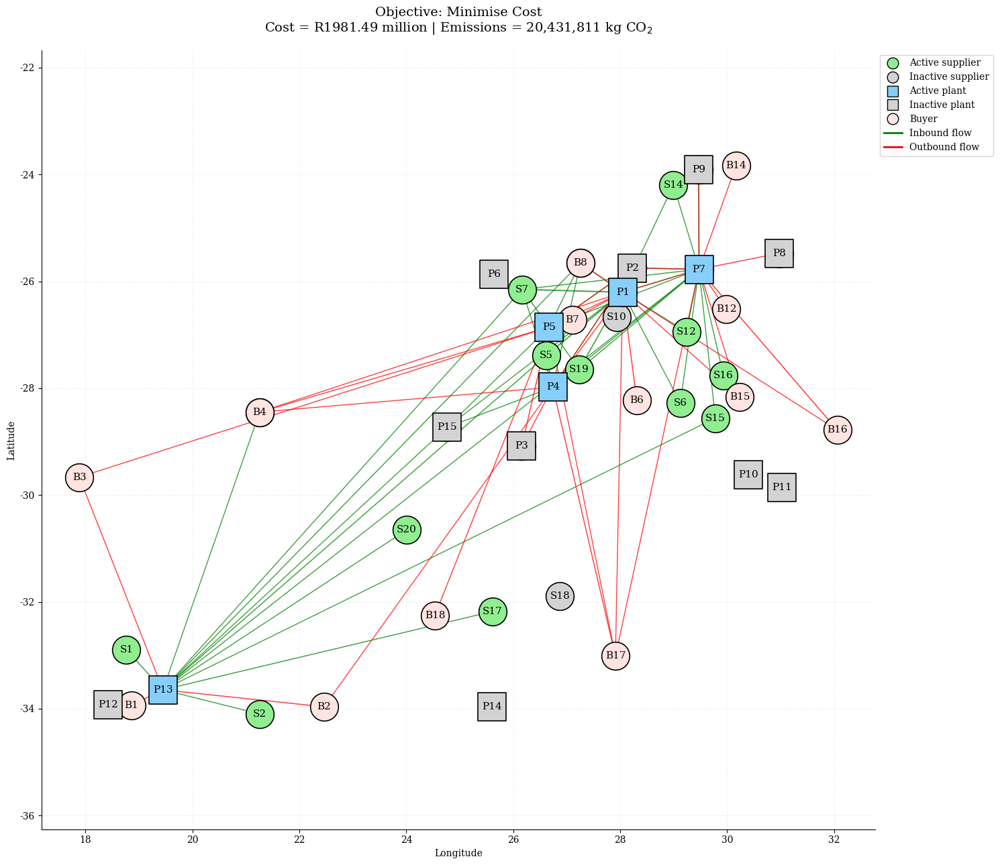

In [49]:
# Min-cost

mdl_E11_2_cost, vars_E11_2_cost = Functions.build_model(
    data_E11_2,
    objective="cost"
)

mdl_E11_2_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E11_2_cost.parameters.timelimit = 900

results_E11_2_cost = Functions.solve_and_extract(
    mdl_E11_2_cost,
    vars_E11_2_cost,
    data_E11_2,
    log_output=False
)

Experiments.experiment_report(
    results_E11_2_cost,
    mdl_E11_2_cost,
    experiment_id="E11.2",
    scenario_name="Mpumalanga availability 50% – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E11_2_cost,
    data_E11_2,
    coord_file="Master_Coordinates.xlsx"
)


EXPERIMENT REPORT
Experiment : E11.2
Scenario   : Mpumalanga availability 50% – min-emissions
Objective  : Min-Emissions

Objective value : 19,053,886.57
Total cost      : R 2,123,671,254.05
Total emissions : 19,053,886.57 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,460,772,366.83
inbound_transport_cost        : R 113,311,014.00
production_cost               : R 299,696,403.22
plant_opening_cost            : R 199,195,000.00
outbound_transport_cost       : R 50,696,470.00

--- Emissions breakdown ---
inbound_emissions             : 2,378,287.37 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,611,599.20 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 7,986.12 tonnes
P1 - F3: 6,080.00 tonnes
P1 - F4: 6,250.00 tonnes
P1 - F5: 7,727.33 tonnes
P1 - F6: 7,790.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410.00 t

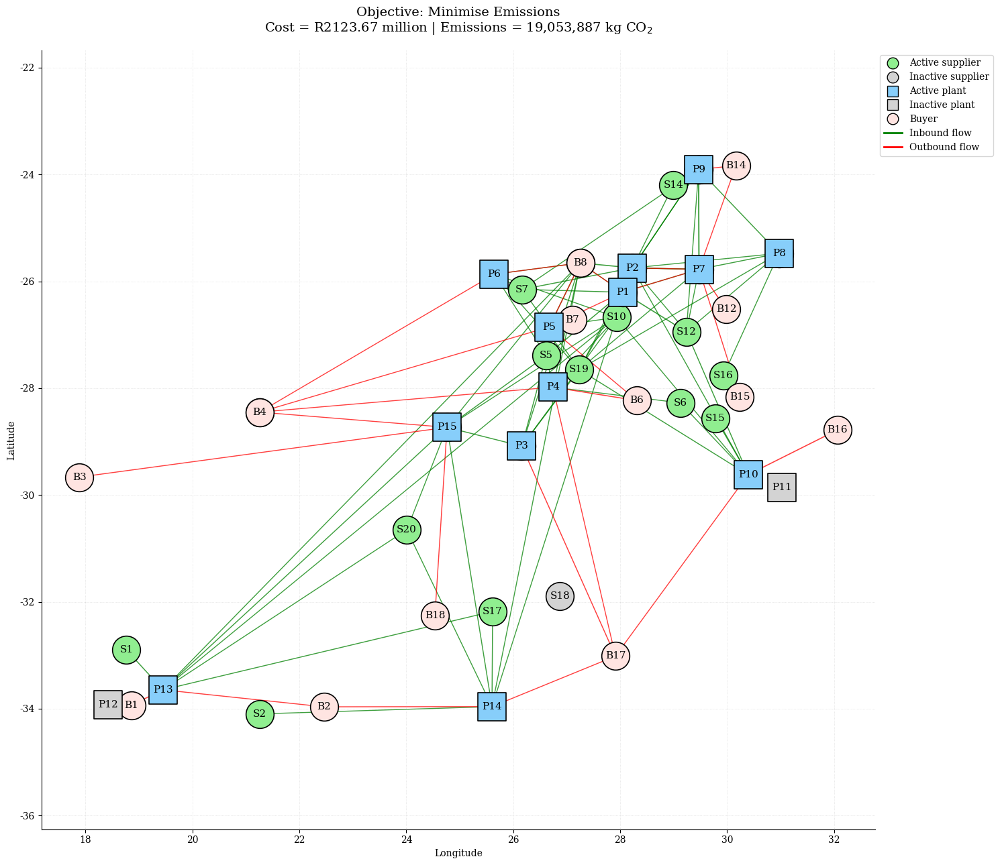

In [50]:
# Min-emissions

mdl_E11_2_emissions, vars_E11_2_emissions = Functions.build_model(
    data_E11_2,
    objective="emissions"
)

mdl_E11_2_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E11_2_emissions.parameters.timelimit = 900

results_E11_2_emissions = Functions.solve_and_extract(
    mdl_E11_2_emissions,
    vars_E11_2_emissions,
    data_E11_2,
    log_output=False
)

Experiments.experiment_report(
    results_E11_2_emissions,
    mdl_E11_2_emissions,
    experiment_id="E11.2",
    scenario_name="Mpumalanga availability 50% – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E11_2_emissions,
    data_E11_2,
    coord_file="Master_Coordinates.xlsx"
)

### E11.3 Reduced supplier capacity - Mpumalanga availability 25%

In [51]:
data_E11_3 = Experiments.vary_supplier_capacity(
    data_E11_0,
    suppliers=["S11", "S12"],
    factor=0.25
)


EXPERIMENT REPORT
Experiment : E11.3
Scenario   : Mpumalanga availability 25% – min-cost
Objective  : Min-Cost

Objective value : 1,995,208,331.23
Total cost      : R 1,995,208,331.23
Total emissions : 20,625,742.89 kg CO2
Open plants     : P1, P4, P5, P7, P13

--- Cost breakdown ---
raw_material_cost             : R 1,413,805,396.44
inbound_transport_cost        : R 124,691,579.00
production_cost               : R 288,545,045.79
plant_opening_cost            : R 81,340,000.00
outbound_transport_cost       : R 86,826,310.00

--- Emissions breakdown ---
inbound_emissions             : 2,797,539.80 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 2,764,203.09 kg CO2

--- Production ---
P1 - F1: 7,397.67 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 32,598.00 tonnes
P1 - F4: 9,000.00 tonnes
P1 - F5: 31,000.00 tonnes
P1 - F6: 31,978.50 tonnes
P4 - F1: 1,033.50 tonnes
P4 - F2: 1,398.47 tonnes
P4 - F3: 5,800.00 tonnes
P4 - F4: 1,575.00 tonnes
P4 - F5: 5

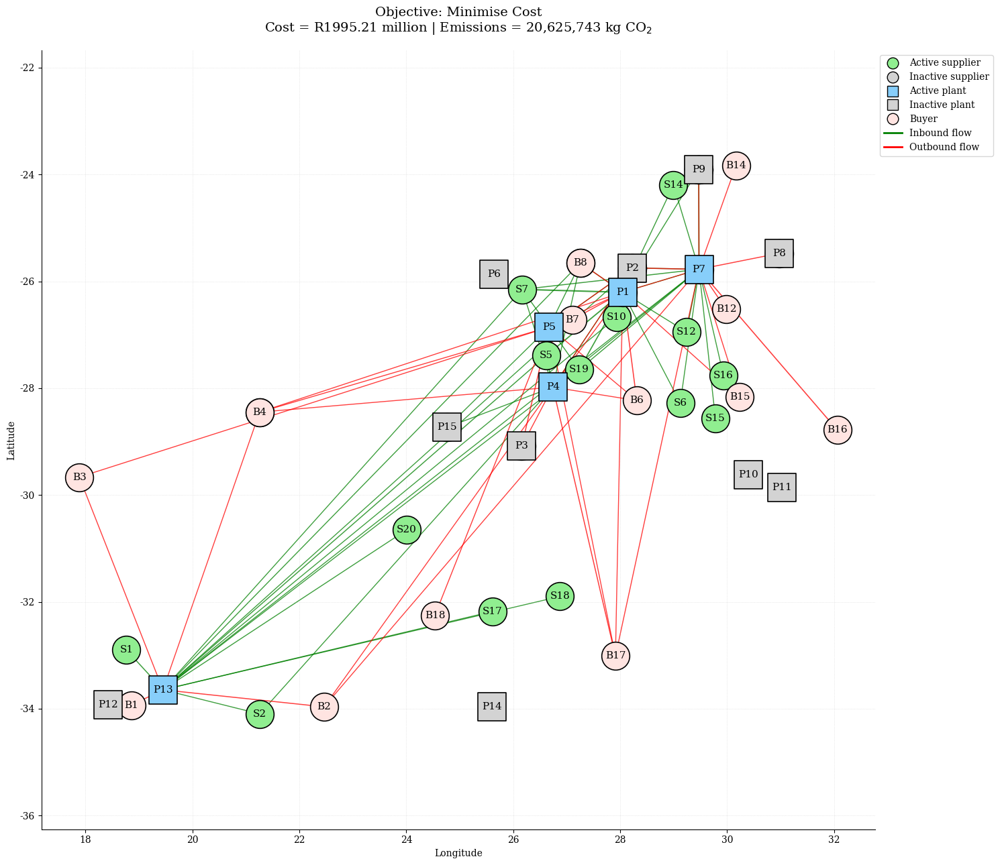

In [52]:
# Min-cost

mdl_E11_3_cost, vars_E11_3_cost = Functions.build_model(
    data_E11_3,
    objective="cost"
)

mdl_E11_3_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E11_3_cost.parameters.timelimit = 900

results_E11_3_cost = Functions.solve_and_extract(
    mdl_E11_3_cost,
    vars_E11_3_cost,
    data_E11_3,
    log_output=False
)

Experiments.experiment_report(
    results_E11_3_cost,
    mdl_E11_3_cost,
    experiment_id="E11.3",
    scenario_name="Mpumalanga availability 25% – min-cost",
    objective_name="Min-Cost"
)

# Min-cost plot

Experiments.plot_exp_solution(
    results_E11_3_cost,
    data_E11_3,
    coord_file="Master_Coordinates.xlsx"
)


EXPERIMENT REPORT
Experiment : E11.3
Scenario   : Mpumalanga availability 25% – min-emissions
Objective  : Min-Emissions

Objective value : 19,147,215.73
Total cost      : R 2,179,324,131.67
Total emissions : 19,147,215.73 kg CO2
Open plants     : P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P13, P14, P15

--- Cost breakdown ---
raw_material_cost             : R 1,464,627,935.00
inbound_transport_cost        : R 120,358,143.00
production_cost               : R 300,160,379.67
plant_opening_cost            : R 245,971,000.00
outbound_transport_cost       : R 48,206,674.00

--- Emissions breakdown ---
inbound_emissions             : 2,551,157.29 kg CO2
plant_emissions               : 15,064,000.00 kg CO2
outbound_emissions            : 1,532,058.44 kg CO2

--- Production ---
P1 - F1: 7,400.00 tonnes
P1 - F2: 8,000.00 tonnes
P1 - F3: 4,960.00 tonnes
P1 - F4: 7,090.00 tonnes
P1 - F5: 7,330.00 tonnes
P1 - F6: 7,790.00 tonnes
P2 - F1: 7,400.00 tonnes
P2 - F2: 7,910.00 tonnes
P2 - F3: 11,410

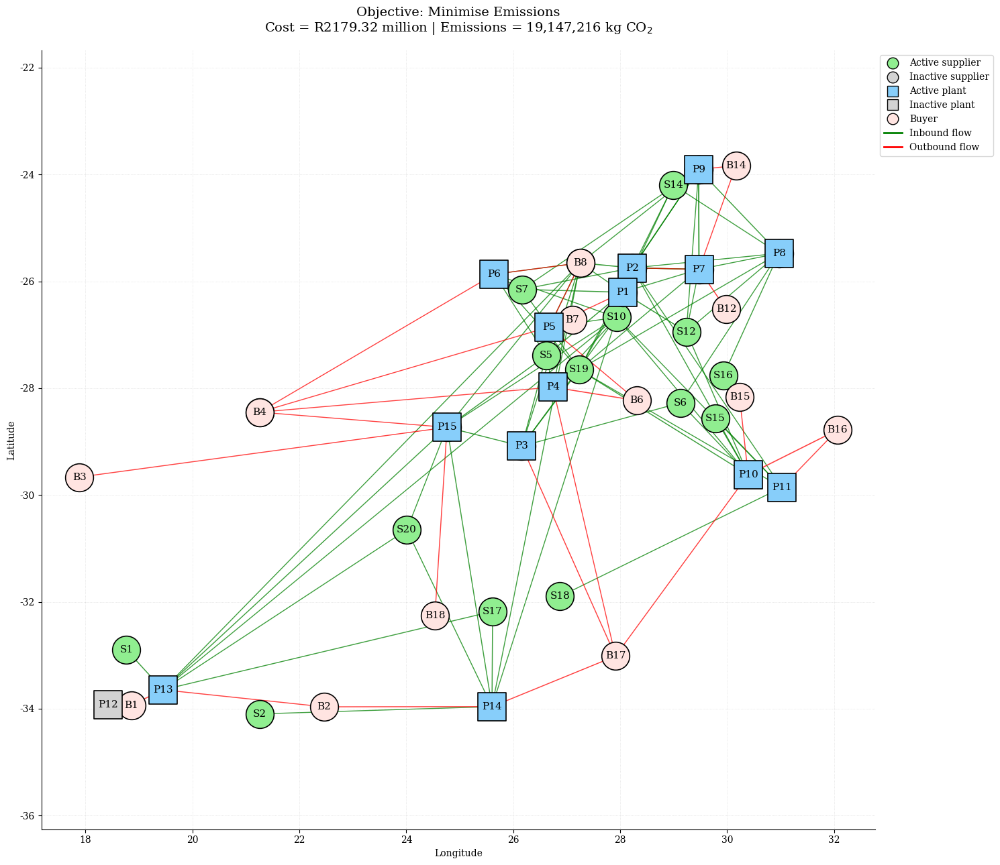

In [53]:
# Min-emissions

mdl_E11_3_emissions, vars_E11_3_emissions = Functions.build_model(
    data_E11_3,
    objective="emissions"
)

mdl_E11_3_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E11_3_emissions.parameters.timelimit = 900

results_E11_3_emissions = Functions.solve_and_extract(
    mdl_E11_3_emissions,
    vars_E11_3_emissions,
    data_E11_3,
    log_output=False
)

Experiments.experiment_report(
    results_E11_3_emissions,
    mdl_E11_3_emissions,
    experiment_id="E11.3",
    scenario_name="Mpumalanga availability 25% – min-emissions",
    objective_name="Min-Emissions"
)

# Min-emissions plot

Experiments.plot_exp_solution(
    results_E11_3_emissions,
    data_E11_3,
    coord_file="Master_Coordinates.xlsx"
)

In [59]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

In [56]:
Experiments.stress_test_report(
    results_E11_1_cost,
    mdl_E11_1_cost,
    experiment_id="E11.1",
    scenario_name="test",
    objective_name="Min-Cost"
)


STRESS TEST REPORT
Experiment : E11.1
Scenario   : test
Objective  : Min-Cost

--- Model size ---
Number of variables   : 184,905
Number of constraints : 185,453
Number of binaries    : 15
Number of integers    : 92,400

--- Solve statistics ---
Solve status : integer optimal, tolerance
Solve time   : 16.89 s
MIP gap      : 0.000470

--- Solution ---
Objective value : 1,971,223,106.23
Total cost      : R 1,971,223,106.23
Total emissions : 20,303,724.70 kg CO2
Open plants     : 5


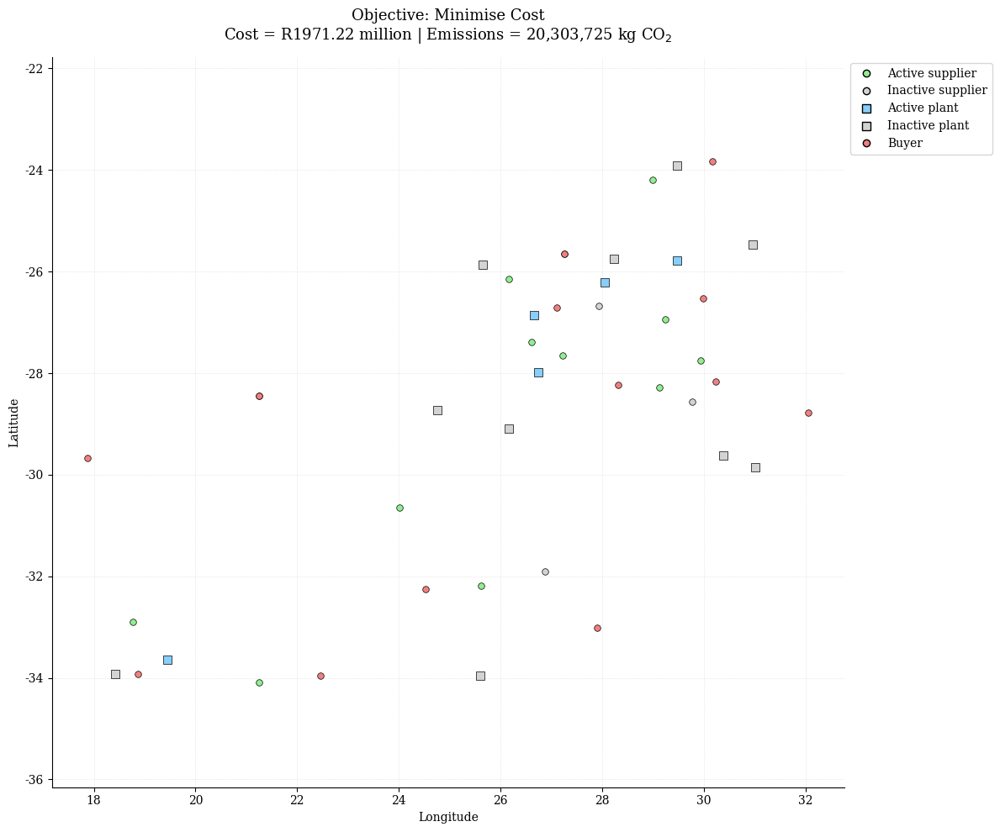

In [60]:
Experiments.stress_test_plot(
    results_E11_1_cost,
    data_E11_1,
    coord_file="Master_Coordinates.xlsx"
)

## E12. Model size and computational stress testing



In [61]:
importlib.reload(Experiments)

<module 'Experiments' from 'c:\\Users\\Nikita\\OneDrive - Stellenbosch University\\AAA Masters\\Coding\\Experiments.py'>

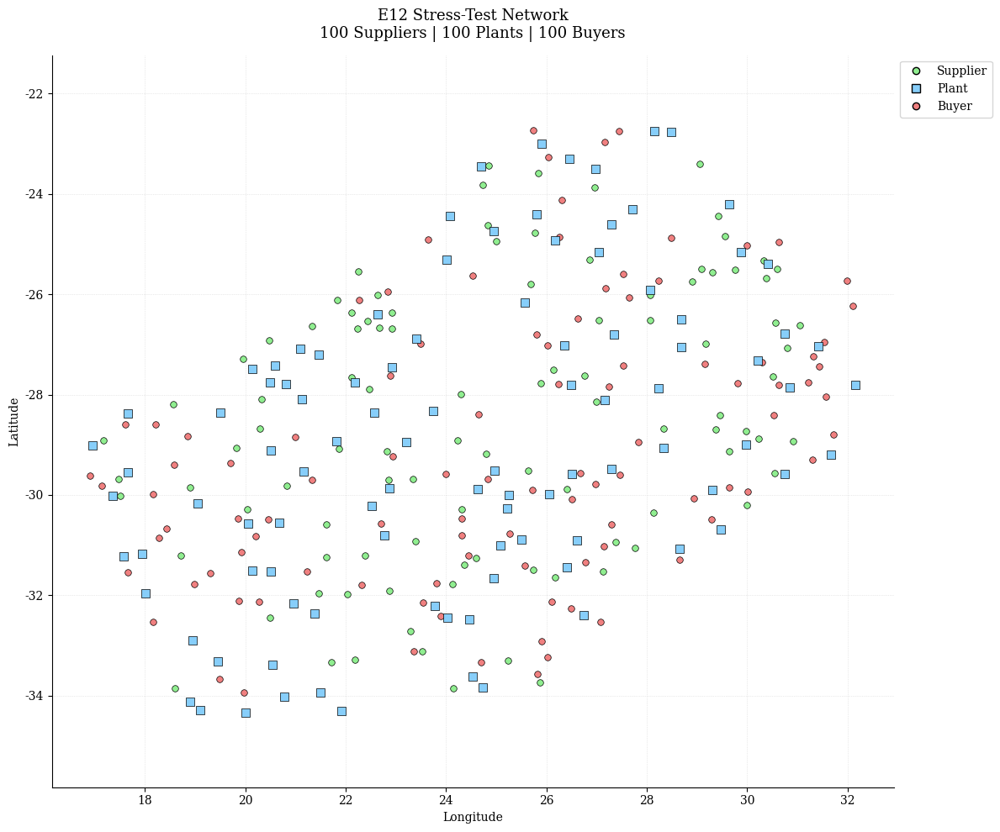

In [ ]:
Experiments.full_plot_coordinates(
    coord_file="E12_Coordinates_random.xlsx"
)

## Test 60/60/60

In [4]:
# ============================================================
# E12 – Exploratory Stress Test: 60/60/60
# ============================================================

import Functions
import Experiments
import importlib

importlib.reload(Functions)
importlib.reload(Experiments)

# Load expanded dataset
master_E12 = Functions.load_master_data("E12_data.xlsx")

# Build 60/60/60 network
data_E12_60 = Functions.build_experiment_data(
    master_E12,
    plants=[f"P{i}" for i in range(1, 61)],
    suppliers=[f"S{i}" for i in range(1, 61)],
    buyers=[f"B{i}" for i in range(1, 61)],
    materials=[f"M{i}" for i in range(1, 11)],
    feeds=[f"F{i}" for i in range(1, 7)],
    trucks=[f"T{i}" for i in range(1, 6)]
)

print("E12 – 60/60/60 network loaded successfully.")

E12 – 60/60/60 network loaded successfully.


Version identifier: 22.1.2.0 | 2024-11-25 | 0edbb82fd
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               3600
CPXPARAM_MIP_Tolerances_MIPGap                   0.001
Tried aggregator 1 time.
MIP Presolve eliminated 1575913 rows and 1471200 columns.
Reduced MIP has 730427 rows, 833220 columns, and 2294280 nonzeros.
Reduced MIP has 60 binaries, 416400 generals, 0 SOSs, and 0 indicators.
Presolve time = 7.17 sec. (2217.89 ticks)
Probing time = 1.20 sec. (49.13 ticks)
Presolve has eliminated 0 rows and 0 columns...
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 730427 rows, 833220 columns, and 2294280 nonzeros.
Reduced MIP has 60 binaries, 416400 generals, 0 SOSs, and 0 indicators.
Presolve time = 5.99 sec. (414901.37 ticks)
Probing time = 0.72 sec. (38.59 ticks)
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic search.
Parallel mode: deterministic, using up to 12 threads.
Root relaxation solution 

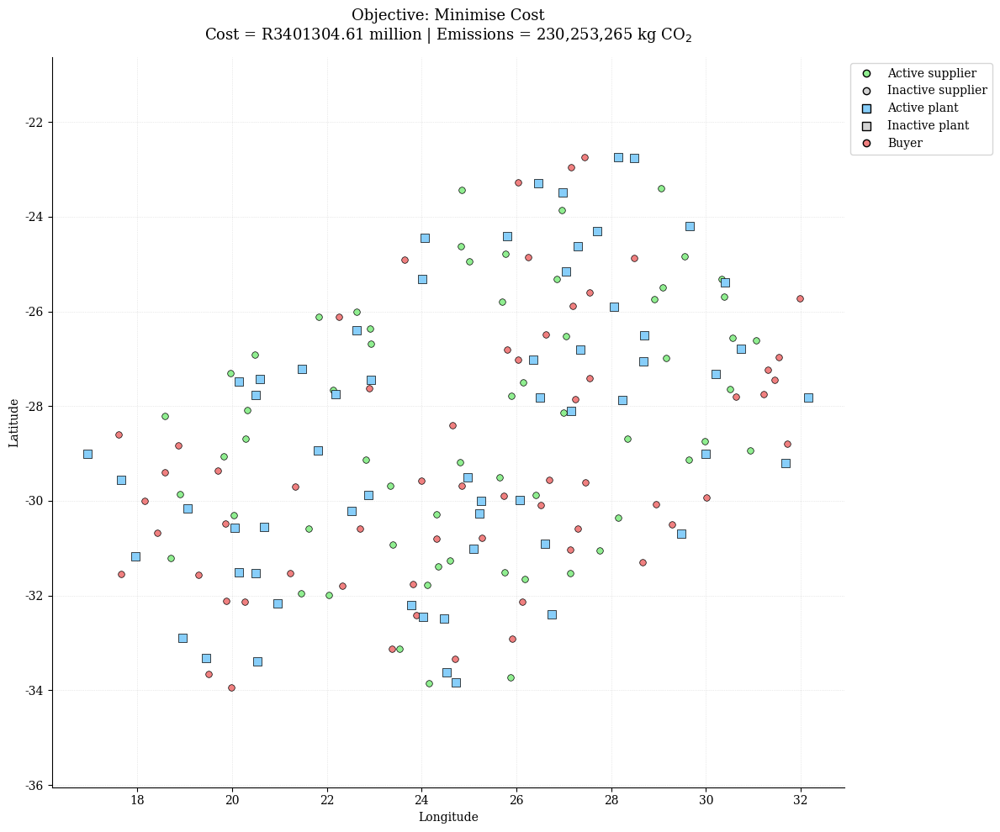

In [2]:
# ============================================================
# E12 – 60/60/60: Min-Cost
# ============================================================

mdl_E12_60_cost, vars_E12_60_cost = Functions.build_model(
    data_E12_60,
    objective="cost"
)

mdl_E12_60_cost.parameters.mip.tolerances.mipgap = 0.001
mdl_E12_60_cost.parameters.timelimit = 3600

results_E12_60_cost = Functions.solve_and_extract(
    mdl_E12_60_cost,
    vars_E12_60_cost,
    data_E12_60,
    log_output=True
)

# Report
Experiments.stress_test_report(
    results_E12_60_cost,
    mdl_E12_60_cost,
    experiment_id="E12 – Exploratory",
    scenario_name="60 suppliers / 60 plants / 60 buyers",
    objective_name="Min-Cost"
)

# Plot (only if a feasible solution was returned)
if results_E12_60_cost is not None:

    Experiments.stress_test_plot(
        results_E12_60_cost,
        data_E12_60,
        coord_file="E12_Coordinates.xlsx"
    )

Version identifier: 22.1.2.0 | 2024-11-25 | 0edbb82fd
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               3600
CPXPARAM_MIP_Tolerances_MIPGap                   0.001
Tried aggregator 1 time.
MIP Presolve eliminated 1680013 rows and 1658580 columns.
Reduced MIP has 626327 rows, 645840 columns, and 1919520 nonzeros.
Reduced MIP has 60 binaries, 312300 generals, 0 SOSs, and 0 indicators.
Presolve time = 7.50 sec. (2414.21 ticks)
Probing time = 0.86 sec. (41.56 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 626327 rows, 645840 columns, and 1919520 nonzeros.
Reduced MIP has 60 binaries, 312300 generals, 0 SOSs, and 0 indicators.
Presolve time = 4.33 sec. (1072.18 ticks)
Probing time = 0.45 sec. (32.20 ticks)
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic search.
Parallel mode: deterministic, using up to 12 threads.
Root relaxation solution time = 4.55 sec. (1184.04 ticks)

        Nodes   

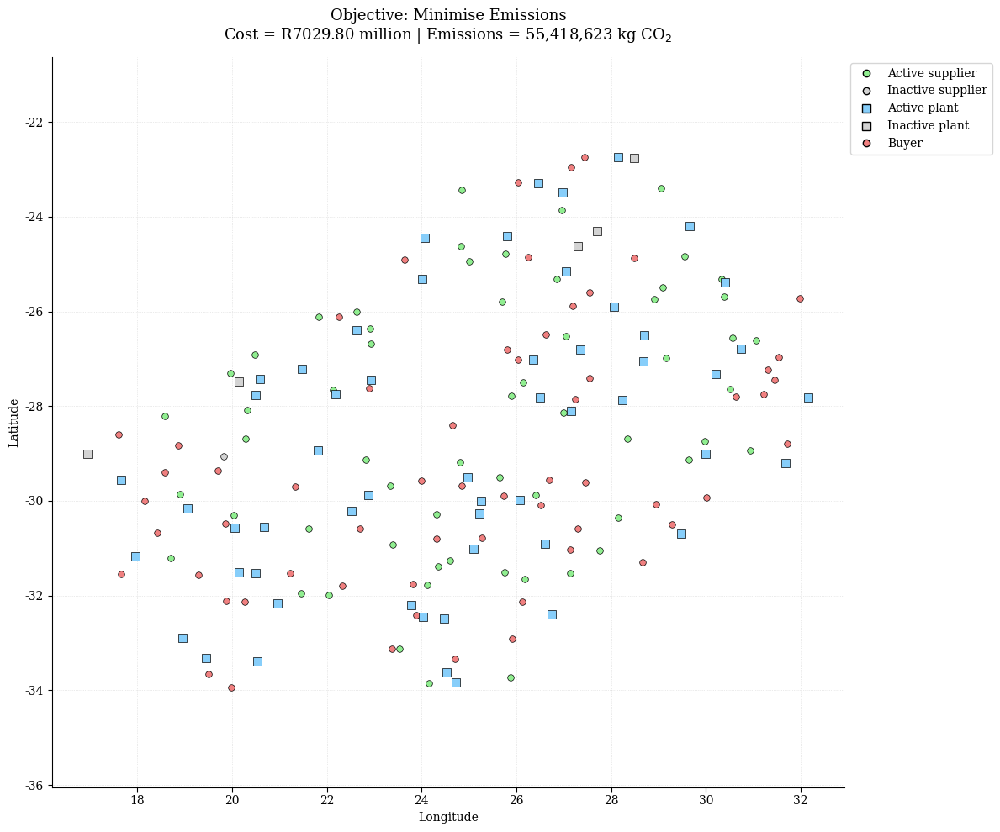

In [5]:
# ============================================================
# E12 – 60/60/60: Min-Emissions
# ============================================================

mdl_E12_60_emissions, vars_E12_60_emissions = Functions.build_model(
    data_E12_60,
    objective="emissions"
)

mdl_E12_60_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E12_60_emissions.parameters.timelimit = 3600

results_E12_60_emissions = Functions.solve_and_extract(
    mdl_E12_60_emissions,
    vars_E12_60_emissions,
    data_E12_60,
    log_output=True
)

# Report
Experiments.stress_test_report(
    results_E12_60_emissions,
    mdl_E12_60_emissions,
    experiment_id="E12 – Exploratory",
    scenario_name="60 suppliers / 60 plants / 60 buyers",
    objective_name="Min-Emissions"
)

# Plot (only if a feasible solution was returned)
if results_E12_60_emissions is not None:

    Experiments.stress_test_plot(
        results_E12_60_emissions,
        data_E12_60,
        coord_file="E12_Coordinates.xlsx"
    )

In [ ]:
# ============================================================
# E12 – Exploratory Stress Test: 60/60/60
# ============================================================

import Functions
import Experiments
import importlib

importlib.reload(Functions)
importlib.reload(Experiments)

# Load expanded dataset
master_E12 = Functions.load_master_data("E12_data.xlsx")

# Build 60/60/60 network
data_E12_60 = Functions.build_experiment_data(
    master_E12,
    plants=[f"P{i}" for i in range(1, 61)],
    suppliers=[f"S{i}" for i in range(1, 61)],
    buyers=[f"B{i}" for i in range(1, 61)],
    materials=[f"M{i}" for i in range(1, 11)],
    feeds=[f"F{i}" for i in range(1, 7)],
    trucks=[f"T{i}" for i in range(1, 6)]
)

print("E12 – 60/60/60 network loaded successfully.")

In [7]:
# ============================================================
# E12 – 60/60/60: Min-Emissions
# ============================================================

mdl_E12_60_emissions, vars_E12_60_emissions = Functions.build_model(
    data_E12_60,
    objective="emissions"
)

mdl_E12_60_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E12_60_emissions.parameters.timelimit = 3600

results_E12_60_emissions = Functions.solve_and_extract(
    mdl_E12_60_emissions,
    vars_E12_60_emissions,
    data_E12_60,
    log_output=True
)

# Report
Experiments.stress_test_report(
    results_E12_60_emissions,
    mdl_E12_60_emissions,
    experiment_id="E12 – Exploratory",
    scenario_name="60 suppliers / 60 plants / 60 buyers",
    objective_name="Min-Emissions"
)

# Plot (only if a feasible solution was returned)
if results_E12_60_emissions is not None:

    Experiments.stress_test_plot(
        results_E12_60_emissions,
        data_E12_60,
        coord_file="E12_Coordinates.xlsx"
        
    )

Exception ignored in: <function ZipFile.__del__ at 0x000001EA24EE2660>
Traceback (most recent call last):
  File "c:\Users\Nikita\anaconda3\envs\feed_model\Lib\zipfile.py", line 1908, in __del__
    self.close()
  File "c:\Users\Nikita\anaconda3\envs\feed_model\Lib\zipfile.py", line 1910, in close
    def close(self):

KeyboardInterrupt: 


KeyboardInterrupt: 

E12 – 70/70/70 network loaded successfully.
Version identifier: 22.1.2.0 | 2024-11-25 | 0edbb82fd
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               3600
CPXPARAM_MIP_Tolerances_MIPGap                   0.001
Tried aggregator 1 time.
MIP Presolve eliminated 2271508 rows and 2241960 columns.
Reduced MIP has 867222 rows, 894530 columns, and 2658040 nonzeros.
Reduced MIP has 70 binaries, 432600 generals, 0 SOSs, and 0 indicators.
Presolve time = 10.70 sec. (3304.20 ticks)
Probing time = 2.14 sec. (57.76 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 867222 rows, 894530 columns, and 2658040 nonzeros.
Reduced MIP has 70 binaries, 432600 generals, 0 SOSs, and 0 indicators.
Presolve time = 6.88 sec. (1489.12 ticks)
Probing time = 1.41 sec. (44.59 ticks)
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic search.
Parallel mode: deterministic, using up to 12 threads.
Root relaxation solution time 

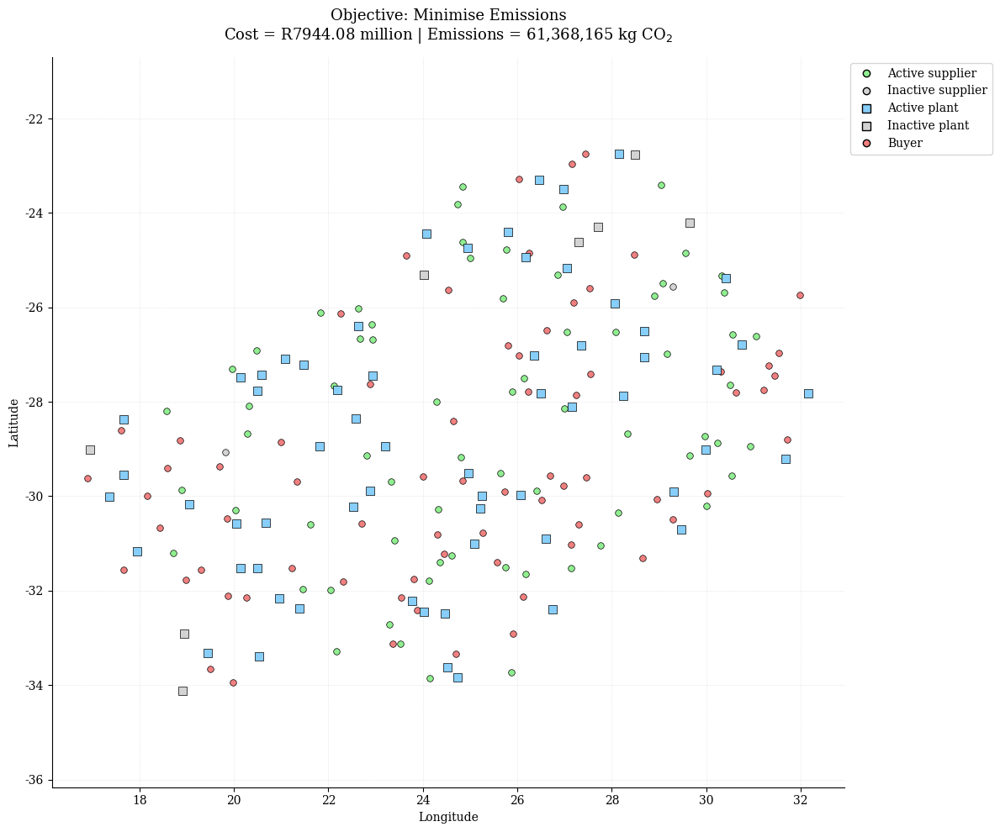

In [8]:
# ============================================================
# E12 – Exploratory Stress Test: 70/70/70
# ============================================================

import Functions
import Experiments
import importlib

importlib.reload(Functions)
importlib.reload(Experiments)

# Load expanded dataset
master_E12 = Functions.load_master_data("E12_data.xlsx")

# Build 70/70/70 network
data_E12_70 = Functions.build_experiment_data(
    master_E12,
    plants=[f"P{i}" for i in range(1, 71)],
    suppliers=[f"S{i}" for i in range(1, 71)],
    buyers=[f"B{i}" for i in range(1, 71)],
    materials=[f"M{i}" for i in range(1, 11)],
    feeds=[f"F{i}" for i in range(1, 7)],
    trucks=[f"T{i}" for i in range(1, 6)]
)

print("E12 – 70/70/70 network loaded successfully.")


# ============================================================
# E12 – 70/70/70: Min-Emissions
# ============================================================

mdl_E12_70_emissions, vars_E12_70_emissions = Functions.build_model(
    data_E12_70,
    objective="emissions"
)

mdl_E12_70_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E12_70_emissions.parameters.timelimit = 3600

results_E12_70_emissions = Functions.solve_and_extract(
    mdl_E12_70_emissions,
    vars_E12_70_emissions,
    data_E12_70,
    log_output=True
)

# Report
Experiments.stress_test_report(
    results_E12_70_emissions,
    mdl_E12_70_emissions,
    experiment_id="E12 – Exploratory",
    scenario_name="70 suppliers / 70 plants / 70 buyers",
    objective_name="Min-Emissions"
)

# Plot (only if a feasible solution was returned)
if results_E12_70_emissions is not None:

    Experiments.stress_test_plot(
        results_E12_70_emissions,
        data_E12_70,
        coord_file="E12_Coordinates.xlsx"
    )

In [10]:
# ============================================================
# E12 – Exploratory Stress Test: 80/80/80
# ============================================================

import Functions
import Experiments
import importlib

importlib.reload(Functions)
importlib.reload(Experiments)

# Load expanded dataset
master_E12 = Functions.load_master_data("E12_data.xlsx")

# Build 80/80/80 network
data_E12_80 = Functions.build_experiment_data(
    master_E12,
    plants=[f"P{i}" for i in range(1, 81)],
    suppliers=[f"S{i}" for i in range(1, 81)],
    buyers=[f"B{i}" for i in range(1, 81)],
    materials=[f"M{i}" for i in range(1, 11)],
    feeds=[f"F{i}" for i in range(1, 7)],
    trucks=[f"T{i}" for i in range(1, 6)]
)

print("E12 – 80/80/80 network loaded successfully.")


# ============================================================
# E12 – 80/80/80: Min-Emissions
# ============================================================

mdl_E12_80_emissions, vars_E12_80_emissions = Functions.build_model(
    data_E12_80,
    objective="emissions"
)

mdl_E12_80_emissions.parameters.mip.tolerances.mipgap = 0.001
mdl_E12_80_emissions.parameters.timelimit = 3600

results_E12_80_emissions = Functions.solve_and_extract(
    mdl_E12_80_emissions,
    vars_E12_80_emissions,
    data_E12_80,
    log_output=True
)

# Report
Experiments.stress_test_report(
    results_E12_80_emissions,
    mdl_E12_80_emissions,
    experiment_id="E12 – Exploratory",
    scenario_name="80 suppliers / 80 plants / 80 buyers",
    objective_name="Min-Emissions"
)

# Plot (only if a feasible solution was returned)
if results_E12_80_emissions is not None:

    Experiments.stress_test_plot(
        results_E12_80_emissions,
        data_E12_80,
        coord_file="E12_Coordinates.xlsx"
    )

E12 – 80/80/80 network loaded successfully.
Version identifier: 22.1.2.0 | 2024-11-25 | 0edbb82fd
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               3600
CPXPARAM_MIP_Tolerances_MIPGap                   0.001
Tried aggregator 1 time.
MIP Presolve eliminated 2976013 rows and 2937840 columns.
Reduced MIP has 1123107 rows, 1158720 columns, and 3442560 nonzeros.
Reduced MIP has 80 binaries, 560400 generals, 0 SOSs, and 0 indicators.
Presolve time = 9.41 sec. (4306.82 ticks)
Probing time = 3.14 sec. (75.01 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 1123107 rows, 1158720 columns, and 3442560 nonzeros.
Reduced MIP has 80 binaries, 560400 generals, 0 SOSs, and 0 indicators.
Presolve time = 5.03 sec. (1930.79 ticks)
Probing time = 1.08 sec. (57.75 ticks)
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic search.
Parallel mode: deterministic, using up to 12 threads.
Root relaxation solution ti

________________